## SINDy + Timestepping

  Weak SINDy + Kernel SSP3 Timestepping
  Spatial obs: No=64/256  Temporal obs: Nt_snap=300

[1] Generating KS ground truth (ETDRK4, nu=0.01) ...
    ETDRK4: dt_fine=1.25e-04  nt_fine=8000 ...
    Spatial obs: No=64/256  (25.0% of grid)
    shape=(300, 256)  |u|_max=30.7397

[2] LOO-CV for kernel hyperparameters (sparse spatial obs) ...

  LOO-CV  Ld=6.2832  Nc=64  No=64  (7x5 grid)
    sig=0.0503 (0.008xLd)  lam=8.99e-07  LOO=1.7506e+02  cond=3.9e+06
    sig=0.0503 (0.008xLd)  lam=8.99e-05  LOO=1.8881e+01  cond=3.9e+04
    sig=0.0503 (0.008xLd)  lam=8.99e-03  LOO=1.1627e+01  cond=3.9e+02
    sig=0.0503 (0.008xLd)  lam=8.99e-02  LOO=1.6364e+01  cond=4.0e+01
    sig=0.0503 (0.008xLd)  lam=4.50e-01  LOO=2.7470e+01  cond=8.9e+00
    sig=0.1005 (0.016xLd)  lam=1.82e-06  LOO=9.8285e-01  cond=5.8e+06
    sig=0.1005 (0.016xLd)  lam=1.82e-04  LOO=1.1622e+00  cond=5.8e+04
    sig=0.1005 (0.016xLd)  lam=1.82e-02  LOO=2.5316e+00  cond=5.8e+02
    sig=0.1005 (0.016xLd)  lam=1.82e-01  LOO=7.0832e+0

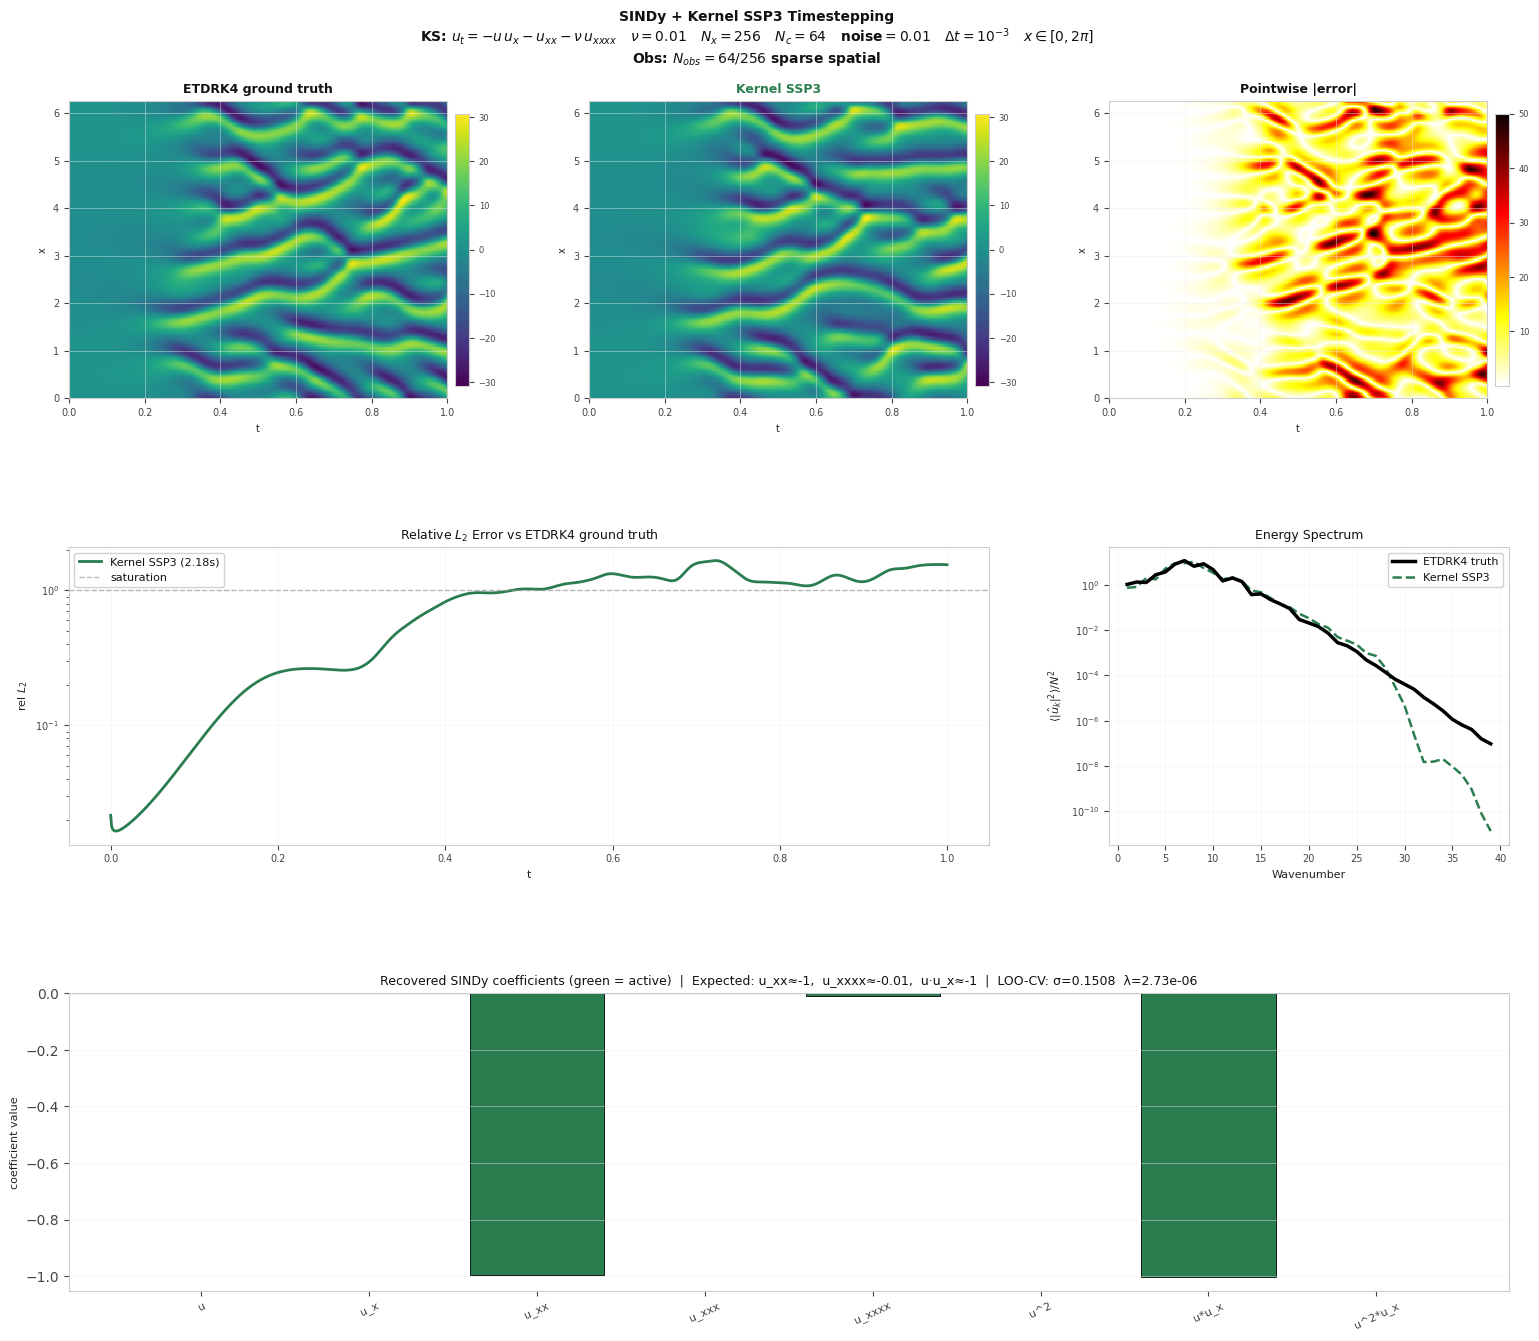

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
from scipy.linalg import cho_factor, cho_solve
from scipy.ndimage import uniform_filter1d


# ================================================================
# Spectral helpers
# ================================================================

def wavenum(N, Ld):
    return 2.0 * np.pi * np.fft.rfftfreq(N, d=Ld / N)


def spec_derivs_rows(F, Ld):
    M, Nx = F.shape
    k  = wavenum(Nx, Ld)
    Fh = np.fft.rfft(F, axis=1)
    Fx    = np.fft.irfft(1j * k[None, :] * Fh,        n=Nx, axis=1)
    Fxx   = np.fft.irfft(-(k[None, :]**2) * Fh,       n=Nx, axis=1)
    Fxxx  = np.fft.irfft(-1j * (k[None, :]**3) * Fh,  n=Nx, axis=1)
    Fxxxx = np.fft.irfft((k[None, :]**4) * Fh,        n=Nx, axis=1)
    return Fx, Fxx, Fxxx, Fxxxx


# ================================================================
# Periodic Gaussian kernel + analytic derivatives
# ================================================================

def ker(x, c, sig, Ld):
    d = np.pi * (x[:, None] - c[None, :]) / Ld
    return np.exp(-2.0 * np.sin(d)**2 / sig**2)


def ker_derivs(x, c, sig, Ld):
    p     = np.pi / Ld
    d     = p * (x[:, None] - c[None, :])
    Phi   = np.exp(-2.0 * np.sin(d)**2 / sig**2)
    f1    = -4.0 * p    * np.sin(d) * np.cos(d) / sig**2
    f1p   = -4.0 * p**2 * np.cos(2 * d)         / sig**2
    f1pp  =  8.0 * p**3 * np.sin(2 * d)         / sig**2
    f1ppp = 16.0 * p**4 * np.cos(2 * d)         / sig**2
    Phi_x    = Phi * f1
    Phi_xx   = Phi * (f1**2 + f1p)
    Phi_xxx  = Phi * (f1**3 + 3*f1*f1p + f1pp)
    Phi_xxxx = Phi * (f1**4 + 6*f1**2*f1p + 3*f1p**2 + 4*f1*f1pp + f1ppp)
    return Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx


# ================================================================
# ETDRK4 ground truth
# ================================================================

def ks_truth_etdrk4(u0, nu, x, dt, nt, Mq=64):
    nx   = x.size
    dx   = x[1] - x[0]
    k    = 2.0 * np.pi * np.fft.fftfreq(nx, d=dx)
    ik   = 1j * k
    Lhat = k**2 - nu * k**4
    E    = np.exp(dt * Lhat)
    E2   = np.exp(0.5 * dt * Lhat)
    roots = np.exp(1j * np.pi * (np.arange(1, Mq + 1) - 0.5) / Mq)
    LR    = dt * Lhat[:, None] + roots[None, :]
    Q  = dt * np.real(np.mean((np.exp(LR / 2.0) - 1.0) / LR, axis=1))
    f1 = dt * np.real(np.mean((-4.0 - LR + np.exp(LR)*(4.0 - 3.0*LR + LR**2)) / LR**3, axis=1))
    f2 = dt * np.real(np.mean((2.0 + LR + np.exp(LR)*(-2.0 + LR)) / LR**3, axis=1))
    f3 = dt * np.real(np.mean((-4.0 - 3.0*LR - LR**2 + np.exp(LR)*(4.0 - LR)) / LR**3, axis=1))
    def N_hat(vhat):
        u  = np.fft.ifft(vhat).real
        ux = np.fft.ifft(ik * vhat).real
        return np.fft.fft(-u * ux)
    U    = np.zeros((nt + 1, nx))
    U[0] = u0
    v    = np.fft.fft(u0)
    for n in range(nt):
        Nv = N_hat(v)
        a  = E2*v + Q*Nv;              Na = N_hat(a)
        b  = E2*v + Q*Na;              Nb = N_hat(b)
        c  = E2*a + Q*(2.0*Nb - Nv);  Nc = N_hat(c)
        v  = E*v + f1*Nv + 2.0*f2*(Na + Nb) + f3*Nc
        U[n + 1] = np.fft.ifft(v).real
    return U


def make_ic(x):
    return (np.cos(x) + 0.1*np.sin(2*x) - 0.1*np.cos(3*x) + 0.05*np.sin(5*x))


def generate_data(Nx=256, Nt_snap=300, t_max=1.0, nu=0.01,
                  x_min=0.0, x_max=2.0*np.pi,
                  noise_std=1e-2, dt_truth=1e-3, truth_refine=8, seed=0,
                  n_obs_x=None):
    x  = np.linspace(x_min, x_max, Nx, endpoint=False)
    u0 = make_ic(x)
    Ld = x_max - x_min
    nt       = int(round(t_max / dt_truth))
    dt_fine  = dt_truth / truth_refine
    nt_fine  = nt * truth_refine
    print(f"    ETDRK4: dt_fine={dt_fine:.2e}  nt_fine={nt_fine} ...")
    U_fine   = ks_truth_etdrk4(u0, nu, x, dt_fine, nt_fine)
    U_truth  = U_fine[::truth_refine][:nt + 1]
    t_full   = np.linspace(0.0, t_max, nt + 1)
    idx      = np.linspace(0, nt, Nt_snap, dtype=int)
    t_snap   = t_full[idx]
    U_true   = U_truth[idx]
    rng      = np.random.default_rng(seed)
    U_obs    = U_true + noise_std * rng.standard_normal(U_true.shape)

    No = Nx if n_obs_x is None else int(n_obs_x)
    No = min(No, Nx)
    if No == Nx:
        obs_idx = np.arange(Nx)
    else:
        obs_idx = np.sort(rng.choice(Nx, No, replace=False))
    x_obs   = x[obs_idx]
    U_obs_s = U_obs[:, obs_idx]

    print(f"    Spatial obs: No={No}/{Nx}  "
          f"({'full grid' if No == Nx else f'{No/Nx*100:.1f}% of grid'})")

    return (x, t_snap, U_true, U_obs, Ld, t_full, U_truth,
            x_obs, obs_idx, U_obs_s)


# ================================================================
# LOO-CV
# ================================================================

def loo_cv_error(U_obs, Phi, lam):
    Nx, Nc = Phi.shape
    Mass   = Phi.T @ Phi + lam * np.eye(Nc)
    cho    = cho_factor(Mass)
    B      = cho_solve(cho, Phi.T)
    H_ii   = np.einsum("ij,ji->i", Phi, B)
    denom  = np.clip(1.0 - H_ii, 1e-6, None)
    total  = 0.0
    for u in U_obs:
        alpha = cho_solve(cho, Phi.T @ u)
        resid = (u - Phi @ alpha) / denom
        total += float(np.dot(resid, resid))
    return total / (len(U_obs) * Nx)


def find_sig_lam(U_obs_s, x_obs, Ld, Nc,
                 sig_fractions_of_Ld=(0.008, 0.016, 0.024, 0.032, 0.048, 0.064, 0.080),
                 lam_multipliers=(1e-6, 1e-4, 1e-2, 1e-1, 5e-1),
                 max_cond=1e10, verbose=True):
    No = len(x_obs)
    centers = np.linspace(0.0, Ld, Nc, endpoint=False)
    best_err, best_sig, best_lam = np.inf, None, None
    if verbose:
        print(f"\n  LOO-CV  Ld={Ld:.4f}  Nc={Nc}  No={No}  "
              f"({len(sig_fractions_of_Ld)}x{len(lam_multipliers)} grid)")
    for sf in sig_fractions_of_Ld:
        sig = Ld * sf
        Phi = ker(x_obs, centers, sig, Ld)
        G   = Phi.T @ Phi
        lam_scale = np.trace(G) / G.shape[0]
        for lm in lam_multipliers:
            lam  = lam_scale * lm
            cond = np.linalg.cond(G + lam * np.eye(Nc))
            if cond > max_cond:
                continue
            err = loo_cv_error(U_obs_s, Phi, lam)
            if verbose:
                print(f"    sig={sig:.4f} ({sf:.3f}xLd)  lam={lam:.2e}  "
                      f"LOO={err:.4e}  cond={cond:.1e}")
            if err < best_err:
                best_err, best_sig, best_lam = err, sig, lam
    if best_sig is None:
        raise RuntimeError("LOO-CV: no valid (sig, lam) found.")
    if verbose:
        print(f"\n  -> best: sig={best_sig:.4f}  lam={best_lam:.2e}  "
              f"LOO={best_err:.4e}")
    return best_sig, best_lam


# ================================================================
# Weak SINDy
# ================================================================

WEAK_LABELS = ["u", "u_x", "u_xx", "u_xxx", "u_xxxx",
               "u^2", "u*u_x", "u^2*u_x"]


def _make_spatial_test_fns(x, Ld, n_test_x, width_frac_x):
    Nx      = len(x)
    centers = np.linspace(0.0, Ld, n_test_x, endpoint=False)
    width   = width_frac_x * Ld
    Phi_x   = np.zeros((n_test_x, Nx))
    for i, c in enumerate(centers):
        d = ((x - c + 0.5*Ld) % Ld) - 0.5*Ld
        s = d / width
        inside = np.abs(s) < 1.0
        Phi_x[i, inside] = (1.0 - s[inside]**2)**3
    return Phi_x


def _make_temporal_test_fns(t_obs, n_test_t, width_frac_t):
    Nt    = len(t_obs)
    width = width_frac_t * (t_obs[-1] - t_obs[0])
    cents = np.linspace(t_obs[0] + width, t_obs[-1] - width, n_test_t)
    Psi   = np.zeros((n_test_t, Nt))
    dPsi  = np.zeros((n_test_t, Nt))
    for m, tc in enumerate(cents):
        s      = (t_obs - tc) / width
        inside = np.abs(s) < 1.0
        Psi [m, inside] =  (1.0 - s[inside]**2)**3
        dPsi[m, inside] = -6.0 * s[inside] * (1.0 - s[inside]**2)**2 / width
    return Psi, dPsi


def _build_theta_b(U_den, t_obs, Ld, n_test_x, n_test_t,
                   width_frac_x, width_frac_t):
    Nt, Nx = U_den.shape
    dx     = Ld / Nx
    dt_vec = np.gradient(t_obs)
    x      = np.linspace(0.0, Ld, Nx, endpoint=False)
    Phi_x  = _make_spatial_test_fns(x, Ld, n_test_x, width_frac_x)
    Phi_x1, Phi_x2, Phi_x3, Phi_x4 = spec_derivs_rows(Phi_x, Ld)
    Psi_t, dPsi_t = _make_temporal_test_fns(t_obs, n_test_t, width_frac_t)
    Phi0_w = dx * Phi_x;   Phi1_w = dx * Phi_x1
    Phi2_w = dx * Phi_x2;  Phi3_w = dx * Phi_x3;  Phi4_w = dx * Phi_x4
    Psi_w  = Psi_t  * dt_vec[None, :]
    dPsi_w = dPsi_t * dt_vec[None, :]
    def weak(Q, Pw, Fw):
        return (Pw @ Q @ Fw.T).ravel()
    U2 = U_den**2;  U3 = U_den**3
    b     = -weak(U_den, dPsi_w, Phi0_w)
    Theta = np.column_stack([
        weak(U_den, Psi_w, Phi0_w),
       -weak(U_den, Psi_w, Phi1_w),
       +weak(U_den, Psi_w, Phi2_w),
       -weak(U_den, Psi_w, Phi3_w),
       +weak(U_den, Psi_w, Phi4_w),
        weak(U2,    Psi_w, Phi0_w),
       -0.5    * weak(U2, Psi_w, Phi1_w),
       -(1/3)  * weak(U3, Psi_w, Phi1_w),
    ])
    return Theta, b


def stls_relative(Theta, b, rel_thr=0.05, ridge=1e-8, max_iter=30):
    col_norms = np.linalg.norm(Theta, axis=0)
    col_norms[col_norms == 0.0] = 1.0
    Tn  = Theta / col_norms
    xi  = np.linalg.solve(Tn.T @ Tn + ridge * np.eye(Tn.shape[1]), Tn.T @ b)
    prev = None
    for _ in range(max_iter):
        mx = np.max(np.abs(xi))
        if mx < 1e-15:  xi[:] = 0.0;  break
        active = np.abs(xi) >= rel_thr * mx
        if not np.any(active):  xi[:] = 0.0;  break
        if prev is not None and np.array_equal(active, prev):  break
        xi_new = np.zeros_like(xi)
        Ta = Tn[:, active]
        xi_new[active] = np.linalg.solve(
            Ta.T @ Ta + ridge * np.eye(active.sum()), Ta.T @ b)
        xi = xi_new;  prev = active.copy()
    active = np.abs(xi) > 0
    if np.any(active):
        Ta = Tn[:, active]
        xi_db = np.zeros_like(xi)
        xi_db[active] = np.linalg.lstsq(Ta, b, rcond=None)[0]
        xi = xi_db
    return xi / col_norms


def run_weak_sindy(U_den, t_obs, Ld, n_test_x, n_test_t,
                   width_frac_x, width_frac_t, rel_thr, ridge, verbose=False):
    Theta, b  = _build_theta_b(U_den, t_obs, Ld,
                                n_test_x, n_test_t, width_frac_x, width_frac_t)
    xi        = stls_relative(Theta, b, rel_thr=rel_thr, ridge=ridge)
    resid_rel = np.linalg.norm(Theta @ xi - b) / (np.linalg.norm(b) + 1e-14)
    n_active  = int(np.sum(np.abs(xi) > 1e-10))
    return xi, {"resid_rel": resid_rel, "n_active": n_active}


# ================================================================
# Scoring helpers
# ================================================================

def linear_stability_penalty(xi, Ld, Nx):
    k     = wavenum(Nx, Ld)
    lam_k = (xi[0] + xi[1]*(1j*k) + xi[2]*(-(k**2))
             + xi[3]*(-(1j)*(k**3)) + xi[4]*(k**4))
    pos   = np.maximum(np.real(lam_k), 0.0)
    return float(np.mean(np.minimum(pos, 25.0)**2))


_ssp3_g     = (3.0 + np.sqrt(3.0)) / 6.0
_ssp3_A_imp = np.array([[_ssp3_g,0,0],[1-2*_ssp3_g,_ssp3_g,0],[0.5,0.5-_ssp3_g,_ssp3_g]])
_ssp3_A_exp = np.array([[0,0,0],[1,0,0],[0.25,0.25,0]], dtype=float)
_ssp3_b     = np.array([1/6, 1/6, 2/3], dtype=float)


def _linear_symbol(xi, k):
    return (xi[0] + xi[1]*(1j*k) + xi[2]*(-(k**2))
            + xi[3]*(-(1j*k**3)) + xi[4]*(k**4))


def _N_phys(Ui, Ui_hat, k, xi, Nx):
    Ux = np.fft.irfft(1j * k * Ui_hat, n=Nx)
    return xi[5]*Ui**2 + xi[6]*Ui*Ux + xi[7]*Ui**2*Ux


def _ssp3_kernel_step(alpha, K0, cho, xi, dt, Ld):
    Nx    = K0.shape[0]
    k     = wavenum(Nx, Ld)
    lam   = _linear_symbol(xi, k)
    denom = 1.0 - dt * _ssp3_g * lam
    u_n   = K0 @ alpha
    Vp, Nh_l, Lh_l = [], [], []
    for i in range(3):
        r = u_n.copy()
        for j in range(i):
            if _ssp3_A_exp[i,j]: r = r + dt*_ssp3_A_exp[i,j]*Nh_l[j]
            if _ssp3_A_imp[i,j]: r = r + dt*_ssp3_A_imp[i,j]*Lh_l[j]
        rh  = np.fft.rfft(r)
        Vih = rh / denom
        Vi  = np.fft.irfft(Vih, n=Nx)
        Vp.append(Vi)
        Nh_l.append(_N_phys(Vi, Vih, k, xi, Nx))
        Lh_l.append(np.fft.irfft(lam * Vih, n=Nx))
    u_new = u_n.copy()
    for i in range(3):
        u_new = u_new + dt*(_ssp3_b[i]*Nh_l[i] + _ssp3_b[i]*Lh_l[i])
    if not np.all(np.isfinite(u_new)):
        return alpha, False
    return cho_solve(cho, K0.T @ u_new), True


def rollout_score(x, t_obs, U_true, U_obs, Ld, xi, sig_cv, lam_cv,
                  Nc=64, horizon_frac=0.15):
    c    = np.linspace(0.0, Ld, Nc, endpoint=False)
    K0   = ker(x, c, sig_cv, Ld)
    cho  = cho_factor(K0.T @ K0 + lam_cv * np.eye(Nc))
    alpha = cho_solve(cho, K0.T @ U_obs[0])
    amp0  = np.max(np.abs(K0 @ alpha)) + 1e-14
    dt_r  = np.median(np.diff(t_obs))
    n_steps = max(1, int(round(horizon_frac * (t_obs[-1] - t_obs[0]) / dt_r)))
    U_pred = [K0 @ alpha]
    for _ in range(n_steps):
        try:
            alpha, ok = _ssp3_kernel_step(alpha, K0, cho, xi, dt_r, Ld)
            u = K0 @ alpha
        except Exception:
            return np.inf, False
        if not ok or not np.all(np.isfinite(u)) or np.max(np.abs(u)) > 8.0*amp0:
            return np.inf, False
        U_pred.append(u)
    U_pred = np.array(U_pred)
    t_pred = t_obs[0] + dt_r * np.arange(len(U_pred))
    idx    = [np.argmin(np.abs(t_obs - tt)) for tt in t_pred]
    err    = (np.linalg.norm(U_pred - U_true[idx]) /
              (np.linalg.norm(U_true[idx]) + 1e-14))
    return err, True


def total_score(resid_rel, n_active, stab_pen, pred_err, stable):
    s  = 1.0*resid_rel + 0.08*n_active + 0.2*stab_pen
    s += 2.0*pred_err if stable else 1e6
    return s


# ================================================================
# 3-stage disciplined hyperparameter search
# ================================================================

def _denoise(U_obs, k_cut, t_smooth):
    Nt, Nx = U_obs.shape
    Uh = np.fft.rfft(U_obs, axis=1)
    Uh[:, min(k_cut, Uh.shape[1]):] = 0.0
    U = np.fft.irfft(Uh, n=Nx, axis=1)
    if t_smooth > 1:
        U = uniform_filter1d(U, size=t_smooth, axis=0, mode="nearest")
    return U


def stage1_denoising(U_obs, verbose=True):
    Uh_ref = np.fft.rfft(U_obs, axis=1).copy()
    Uh_ref[:, 40:] = 0.0
    U_ref  = uniform_filter1d(
        np.fft.irfft(Uh_ref, n=U_obs.shape[1], axis=1),
        size=3, axis=0, mode="nearest")
    best = (np.inf, 48, 3)
    if verbose: print("\n  Stage 1 — denoising  (9 candidates)")
    for kc in [32, 48, 64]:
        for ts in [1, 3, 5]:
            U_den = _denoise(U_obs, kc, ts)
            score = float(np.linalg.norm(U_den - U_ref) /
                          (np.linalg.norm(U_ref) + 1e-14))
            if verbose: print(f"    k_cut={kc}  t_smooth={ts}  score={score:.4f}")
            if score < best[0]: best = (score, kc, ts)
    if verbose: print(f"  -> k_cut={best[1]}  t_smooth={best[2]}")
    return best[1], best[2]


def stage2_integration(U_obs, t_obs, Ld, k_cut, t_smooth, verbose=True):
    U_den = _denoise(U_obs, k_cut, t_smooth)
    best  = (np.inf, 16, 24, 0.10, 0.08)
    if verbose: print(f"\n  Stage 2 — integration  (16 candidates)")
    for ntx in [16, 32]:
        for ntt in [24, 48]:
            for wfx in [0.08, 0.14]:
                for wft in [0.06, 0.10]:
                    Theta, b = _build_theta_b(U_den, t_obs, Ld, ntx, ntt, wfx, wft)
                    xi_ls = np.linalg.lstsq(Theta, b, rcond=None)[0]
                    res   = (np.linalg.norm(Theta @ xi_ls - b) /
                             (np.linalg.norm(b) + 1e-14))
                    if verbose:
                        print(f"    ntx={ntx} ntt={ntt} wfx={wfx} wft={wft}  "
                              f"resid={res:.4e}")
                    if res < best[0]: best = (res, ntx, ntt, wfx, wft)
    if verbose:
        print(f"  -> n_test_x={best[1]}  n_test_t={best[2]}  "
              f"width_frac_x={best[3]}  width_frac_t={best[4]}")
    return best[1], best[2], best[3], best[4]


def stage3_sparsity(U_obs, t_obs, Ld, x, k_cut, t_smooth,
                    n_test_x, n_test_t, width_frac_x, width_frac_t,
                    sig_cv, lam_cv, U_true, Nc=64, verbose=True):
    U_den = _denoise(U_obs, k_cut, t_smooth)
    best_score, best_xi, best_params = np.inf, None, (0.05, 1e-8)
    if verbose: print(f"\n  Stage 3 — sparsity  (9 candidates)")
    for rt in [0.03, 0.05, 0.10]:
        for rg in [1e-10, 1e-8, 1e-6]:
            xi, diag = run_weak_sindy(U_den, t_obs, Ld, n_test_x, n_test_t,
                                      width_frac_x, width_frac_t, rt, rg)
            stab = linear_stability_penalty(xi, Ld, len(x))
            pred_err, stable = rollout_score(x, t_obs, U_true, U_obs, Ld,
                                             xi, sig_cv, lam_cv, Nc=Nc)
            sc = total_score(diag["resid_rel"], diag["n_active"],
                             stab, pred_err, stable)
            if verbose:
                print(f"    rel_thr={rt}  ridge={rg:.0e}  "
                      f"resid={diag['resid_rel']:.3e}  n_act={diag['n_active']}  "
                      f"stab={stab:.3e}  "
                      f"pred={'inf' if not stable else f'{pred_err:.3e}'}  "
                      f"score={sc:.4e}")
            if sc < best_score:
                best_score, best_xi, best_params = sc, xi.copy(), (rt, rg)
    if verbose:
        print(f"  -> rel_thr={best_params[0]}  ridge={best_params[1]:.0e}  "
              f"score={best_score:.4e}")
    return best_xi, U_den, best_params


def disciplined_sindy_search(U_obs, t_obs, x, Ld, U_true, sig_cv, lam_cv,
                              Nc=64, verbose=True):
    print("\n" + "="*60)
    print("  Disciplined 3-stage weak-SINDy search  (34 evals)")
    print("="*60)
    k_cut, t_smooth = stage1_denoising(U_obs, verbose=verbose)
    n_test_x, n_test_t, wfx, wft = stage2_integration(
        U_obs, t_obs, Ld, k_cut, t_smooth, verbose=verbose)
    xi, U_den, (rt, rg) = stage3_sparsity(
        U_obs, t_obs, Ld, x, k_cut, t_smooth,
        n_test_x, n_test_t, wfx, wft,
        sig_cv, lam_cv, U_true, Nc=Nc, verbose=verbose)
    print("\n  Final xi:")
    for nm, v in zip(WEAK_LABELS, xi):
        if abs(v) > 1e-10:
            print(f"    {nm:10s}: {v:+.6f}  ***")
        else:
            print(f"    {nm:10s}: {v:+.6f}")
    return xi, U_den


# ================================================================
# IMEX tableau  —  SSP3 only
# ================================================================

_g3        = (3.0 + np.sqrt(3.0)) / 6.0
_sp3_A_exp = np.array([[0,0,0],[1,0,0],[0.25,0.25,0]], dtype=float)
_sp3_A_imp = np.array([[_g3,0,0],[1-2*_g3,_g3,0],[0.5,0.5-_g3,_g3]], dtype=float)
_sp3_b     = np.array([1/6, 1/6, 2/3], dtype=float)


# ================================================================
# Kernel rollout  —  alpha-space IMEX (SSP3)
# ================================================================

def _N_alpha(alpha, Phi, Phi_x, xi):
    u  = Phi   @ alpha
    ux = Phi_x @ alpha
    N  = xi[5]*u**2 + xi[6]*u*ux + xi[7]*u**2*ux
    return Phi.T @ N


def rollout_kernel(u0_obs, x_obs, x, xi, Ld, dt, Nt, Nc, sig, lam_ker,
                   max_amp=50.0):
    Nx  = len(x)
    No  = len(x_obs)
    ns  = len(_sp3_b)

    c    = np.linspace(0.0, Ld, Nc, endpoint=False)
    Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx = ker_derivs(x, c, sig, Ld)
    L_a = (xi[0]*(Phi.T @ Phi)
         + xi[1]*(Phi.T @ Phi_x)
         + xi[2]*(Phi.T @ Phi_xx)
         + xi[3]*(Phi.T @ Phi_xxx)
         + xi[4]*(Phi.T @ Phi_xxxx))

    M         = Phi.T @ Phi
    M_final   = cho_factor(M + lam_ker * np.eye(Nc))

    diag_vals = sorted(set(float(_sp3_A_imp[i, i]) for i in range(ns)))
    M_stages  = {}
    for g in diag_vals:
        A_g = M - dt * g * L_a
        M_stages[g] = cho_factor(A_g + lam_ker * np.eye(Nc))

    # IC: project sparse observations
    Phi_obs = ker(x_obs, c, sig, Ld)
    M_obs   = cho_factor(Phi_obs.T @ Phi_obs + lam_ker * np.eye(Nc))
    alpha   = cho_solve(M_obs, Phi_obs.T @ u0_obs)

    U      = [Phi @ alpha]
    blowup = None
    t0     = time.perf_counter()

    for step in range(Nt):
        Ma_n    = M @ alpha
        stage_N = []
        stage_L = []

        for i in range(ns):
            rhs = Ma_n.copy()
            for j in range(i):
                if _sp3_A_exp[i, j] != 0.0:
                    rhs = rhs + dt * _sp3_A_exp[i, j] * stage_N[j]
                if _sp3_A_imp[i, j] != 0.0:
                    rhs = rhs + dt * _sp3_A_imp[i, j] * stage_L[j]
            g   = float(_sp3_A_imp[i, i])
            a_i = cho_solve(M_stages[g], rhs)
            stage_N.append(_N_alpha(a_i, Phi, Phi_x, xi))
            stage_L.append(L_a @ a_i)

        rhs_f = Ma_n.copy()
        for i in range(ns):
            rhs_f = rhs_f + dt * _sp3_b[i] * (stage_N[i] + stage_L[i])

        alpha_new = cho_solve(M_final, rhs_f)
        u_new     = Phi @ alpha_new

        if not np.all(np.isfinite(u_new)) or np.max(np.abs(u_new)) > max_amp:
            blowup = step
            break

        alpha = alpha_new
        U.append(u_new)

    wt = time.perf_counter() - t0
    if blowup is not None:
        print(f"  [Kernel SSP3] blowup at step {blowup}  (t={blowup*dt:.4f})")

    return np.array(U), wt, blowup


# ================================================================
# Metrics
# ================================================================

def rel_l2_t(U_pred, U_ref):
    n = min(len(U_pred), len(U_ref))
    return np.linalg.norm(U_pred[:n]-U_ref[:n], axis=1) / (
           np.linalg.norm(U_ref[:n], axis=1) + 1e-12)


def align_gt(U_pred, t_arr, t_full, U_full):
    n   = len(U_pred)
    idx = [np.argmin(np.abs(t_full - tt)) for tt in t_arr[:n]]
    return U_full[idx]


def spectrum(U):
    return np.mean(np.abs(np.fft.rfft(U, axis=1))**2, axis=0) / U.shape[1]**2


# ================================================================
# Plot  —  kernel method only
# ================================================================

def _plot(x, t_pred, t_full, U_full, U_ker, wt_ker, blow_ker,
          err_ker, nu, Nc, sig_cv, lam_cv, xi, dt, x_max,
          n_obs_x=None, Nx=256):

    plt.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white",
        "axes.edgecolor": "#cccccc", "axes.labelcolor": "#222222",
        "xtick.color": "#444444", "ytick.color": "#444444",
        "text.color": "#111111", "grid.color": "#eeeeee",
        "grid.linewidth": 0.6,
    })

    Nt = len(t_pred) - 1

    def pad(U):
        if len(U) >= Nt+1: return U[:Nt+1]
        return np.vstack([U, np.full((Nt+1-len(U), Nx), np.nan)])

    idx_gt = [np.argmin(np.abs(t_full - tt)) for tt in t_pred]
    U_gt   = U_full[idx_gt]
    vm     = np.nanmax(np.abs(U_gt))

    ker_color = "#2a7d4f"

    fig = plt.figure(figsize=(16, 14))
    fig.patch.set_facecolor("white")
    gs  = gridspec.GridSpec(3, 3, figure=fig,
                            left=0.07, right=0.97, top=0.91, bottom=0.06,
                            hspace=0.50, wspace=0.30)

    def make_ax(r, c):
        ax = fig.add_subplot(gs[r, c])
        ax.tick_params(labelsize=7)
        ax.grid(True, lw=0.5, alpha=0.6)
        return ax

    def imax(ax, Z, vmin, vmax):
        im = ax.imshow(np.nan_to_num(Z).T, aspect="auto", origin="lower",
                       cmap="viridis",
                       extent=[t_pred[0], t_pred[-1], x[0], x[-1]],
                       vmin=vmin, vmax=vmax, interpolation="nearest")
        ax.set_xlabel("t", fontsize=7); ax.set_ylabel("x", fontsize=7)
        return im

    def add_cb(ax, im):
        c = fig.colorbar(im, ax=ax, fraction=0.034, pad=0.02)
        c.ax.tick_params(labelsize=6)

    # Row 0: spacetime plots
    ax_gt = make_ax(0, 0)
    im0   = imax(ax_gt, U_gt, -vm, vm)
    add_cb(ax_gt, im0)
    ax_gt.set_title("ETDRK4 ground truth", fontsize=9, fontweight="bold")

    ax_ker = make_ax(0, 1)
    blow_str = (f"  ⚠ blowup @ t={blow_ker*dt:.3f}" if blow_ker is not None else "")
    im1 = imax(ax_ker, pad(U_ker), -vm, vm)
    add_cb(ax_ker, im1)
    ax_ker.set_title(f"Kernel SSP3{blow_str}", fontsize=9,
                     color=ker_color, fontweight="bold")

    ax_err_map = make_ax(0, 2)
    err_map = np.abs(pad(U_ker) - U_gt)
    im2 = ax_err_map.imshow(np.nan_to_num(err_map).T, aspect="auto", origin="lower",
                             cmap="hot_r",
                             extent=[t_pred[0], t_pred[-1], x[0], x[-1]],
                             interpolation="nearest")
    add_cb(ax_err_map, im2)
    ax_err_map.set_xlabel("t", fontsize=7); ax_err_map.set_ylabel("x", fontsize=7)
    ax_err_map.set_title("Pointwise |error|", fontsize=9, fontweight="bold")

    # Row 1: rel-L2 error + energy spectrum
    ax_l2 = fig.add_subplot(gs[1, :2])
    ax_l2.tick_params(labelsize=7); ax_l2.grid(True, lw=0.5, alpha=0.6)
    n_k = len(U_ker)
    lbl = (f"Kernel SSP3 ({wt_ker:.2f}s)" if blow_ker is None
           else f"Kernel SSP3 — blowup @t={blow_ker*dt:.3f}")
    ax_l2.semilogy(t_pred[:n_k], err_ker[:n_k],
                   color=ker_color, lw=2.0, label=lbl)
    if blow_ker is not None:
        ax_l2.axvline(blow_ker*dt, color=ker_color, lw=1.2, ls=":", alpha=0.7)
    ax_l2.axhline(1.0, color="#999999", lw=1.0, ls="--", alpha=0.7,
                  label="saturation")
    ax_l2.set_xlabel("t", fontsize=8); ax_l2.set_ylabel("rel $L_2$", fontsize=8)
    ax_l2.set_title("Relative $L_2$ Error vs ETDRK4 ground truth", fontsize=9)
    ax_l2.legend(fontsize=8, framealpha=0.9)

    ax_sp = fig.add_subplot(gs[1, 2])
    ax_sp.tick_params(labelsize=7); ax_sp.grid(True, lw=0.5, alpha=0.6)
    modes = np.arange(1, 40)
    ax_sp.semilogy(modes, spectrum(U_gt)[modes], color="black",
                   lw=2.5, label="ETDRK4 truth", zorder=5)
    if blow_ker is None:
        ax_sp.semilogy(modes, spectrum(U_ker)[modes],
                       color=ker_color, lw=1.8, ls="--", label="Kernel SSP3")
    ax_sp.set_xlabel("Wavenumber", fontsize=8)
    ax_sp.set_ylabel(r"$\langle|\hat{u}_k|^2\rangle/N^2$", fontsize=8)
    ax_sp.set_title("Energy Spectrum", fontsize=9)
    ax_sp.legend(fontsize=8, framealpha=0.9)

    # Row 2: SINDy coefficients
    ax_xi = fig.add_subplot(gs[2, :])
    active = np.abs(xi) > 1e-10
    bar_c  = ["#2a7d4f" if a else "#cccccc" for a in active]
    ax_xi.bar(WEAK_LABELS, xi, color=bar_c, edgecolor="k", linewidth=0.6)
    ax_xi.axhline(0, color="k", linewidth=0.8)
    ax_xi.set_title(
        f"Recovered SINDy coefficients (green = active)  |  "
        f"Expected: u_xx≈-1,  u_xxxx≈-{nu},  u·u_x≈-1  |  "
        f"LOO-CV: σ={sig_cv:.4f}  λ={lam_cv:.2e}",
        fontsize=9)
    ax_xi.set_ylabel("coefficient value", fontsize=8)
    ax_xi.tick_params(axis="x", rotation=25, labelsize=8)
    ax_xi.grid(True, axis="y", lw=0.5, alpha=0.6)

    No_str = (f"$N_{{obs}}={n_obs_x}/{Nx}$ sparse spatial"
              if n_obs_x and n_obs_x < Nx else "full spatial grid")
    fig.suptitle(
        "SINDy + Kernel SSP3 Timestepping\n"
        r"KS: $u_t = -u\,u_x - u_{xx} - \nu\,u_{xxxx}$"
        + f"   $\\nu={nu}$   $N_x={Nx}$   $N_c={Nc}$   "
          f"noise$={0.01}$   $\\Delta t=10^{{-3}}$   "
          f"$x\\in[0,{x_max/np.pi:.0f}\\pi]$\n"
          f"Obs: {No_str}",
        fontsize=10, fontweight="bold", y=0.975)
    plt.show()


# ================================================================
# Main
# ================================================================

def main():
    Nx           = 256
    x_min, x_max = 0.0, 2.0 * np.pi
    t_max        = 1.0
    dt_truth     = 1e-3
    truth_refine = 8
    nu           = 0.01
    Nt_snap      = 300
    noise_std    = 1e-2
    Nc           = 64
    dt           = dt_truth
    Nt           = int(round(t_max / dt))
    n_obs_x      = 64

    print("="*60)
    print("  Weak SINDy + Kernel SSP3 Timestepping")
    print(f"  Spatial obs: No={n_obs_x}/{Nx}  Temporal obs: Nt_snap={Nt_snap}")
    print("="*60)

    # [1] Data
    print(f"\n[1] Generating KS ground truth (ETDRK4, nu={nu}) ...")
    (x, t_obs, U_true, U_obs, Ld, t_full, U_truth_full,
     x_obs, obs_idx, U_obs_s) = generate_data(
        Nx=Nx, Nt_snap=Nt_snap, t_max=t_max, nu=nu,
        x_min=x_min, x_max=x_max, noise_std=noise_std,
        dt_truth=dt_truth, truth_refine=truth_refine, seed=0,
        n_obs_x=n_obs_x)
    print(f"    shape={U_true.shape}  |u|_max={np.max(np.abs(U_true)):.4f}")

    # [2] LOO-CV
    print("\n[2] LOO-CV for kernel hyperparameters (sparse spatial obs) ...")
    sig_cv, lam_cv = find_sig_lam(
        U_obs_s, x_obs, Ld, Nc,
        sig_fractions_of_Ld=(0.008,0.016,0.024,0.032,0.048,0.064,0.080),
        lam_multipliers=(1e-6,1e-4,1e-2,1e-1,5e-1),
        verbose=True)

    # [3] Weak SINDy
    print("\n[3] 3-stage weak-SINDy search ...")
    xi, U_den = disciplined_sindy_search(
        U_obs, t_obs, x, Ld, U_true, sig_cv, lam_cv, Nc=Nc, verbose=True)

    # [4] Kernel SSP3 rollout
    print("\n[4] Kernel SSP3 rollout ...")
    t_pred  = np.linspace(0, t_max, Nt + 1)
    u0_obs  = U_obs_s[0]

    U_ker, wt_ker, blow_ker = rollout_kernel(
        u0_obs, x_obs, x, xi, Ld, dt, Nt, Nc, sig_cv, lam_cv)
    gt_ker  = align_gt(U_ker, t_pred, t_full, U_truth_full)
    err_ker = rel_l2_t(U_ker, gt_ker)

    n = len(U_ker)
    st = float(np.mean(err_ker[t_pred[:n] < 0.05])) if blow_ker is None else np.inf
    print(f"    steps={n-1}  wall={wt_ker:.3f}s  short-t err={st:.3e}"
          + ("  BLOWUP" if blow_ker is not None else ""))

    # [5] Plot
    print("\n[5] Plotting ...")
    _plot(x, t_pred, t_full, U_truth_full,
          U_ker, wt_ker, blow_ker, err_ker,
          nu, Nc, sig_cv, lam_cv, xi, dt, x_max,
          n_obs_x=len(x_obs), Nx=Nx)


if __name__ == "__main__":
    main()

## SINDy + timestepping + 4DVar (2 step)

  Weak SINDy + Kernel SSP3 + RKHS 4DVar
  Spatial obs: No=64/256  Temporal obs: Nt_snap=300

[1] Generating KS ground truth (ETDRK4, nu=0.01) ...
    ETDRK4: dt_fine=1.25e-04  nt_fine=8000 ...
    Spatial obs: No=64/256  (25.0% of grid)
    shape=(300, 256)  |u|_max=30.7397

[2] LOO-CV for kernel hyperparameters ...

  LOO-CV  Ld=6.2832  Nc=64  No=64  (7x5 grid)
    sig=0.0503 (0.008xLd)  lam=8.99e-07  LOO=1.7506e+02  cond=3.9e+06
    sig=0.0503 (0.008xLd)  lam=8.99e-05  LOO=1.8881e+01  cond=3.9e+04
    sig=0.0503 (0.008xLd)  lam=8.99e-03  LOO=1.1627e+01  cond=3.9e+02
    sig=0.0503 (0.008xLd)  lam=8.99e-02  LOO=1.6364e+01  cond=4.0e+01
    sig=0.0503 (0.008xLd)  lam=4.50e-01  LOO=2.7470e+01  cond=8.9e+00
    sig=0.1005 (0.016xLd)  lam=1.82e-06  LOO=9.8285e-01  cond=5.8e+06
    sig=0.1005 (0.016xLd)  lam=1.82e-04  LOO=1.1622e+00  cond=5.8e+04
    sig=0.1005 (0.016xLd)  lam=1.82e-02  LOO=2.5316e+00  cond=5.8e+02
    sig=0.1005 (0.016xLd)  lam=1.82e-01  LOO=7.0832e+00  cond=5.9e+01
    s

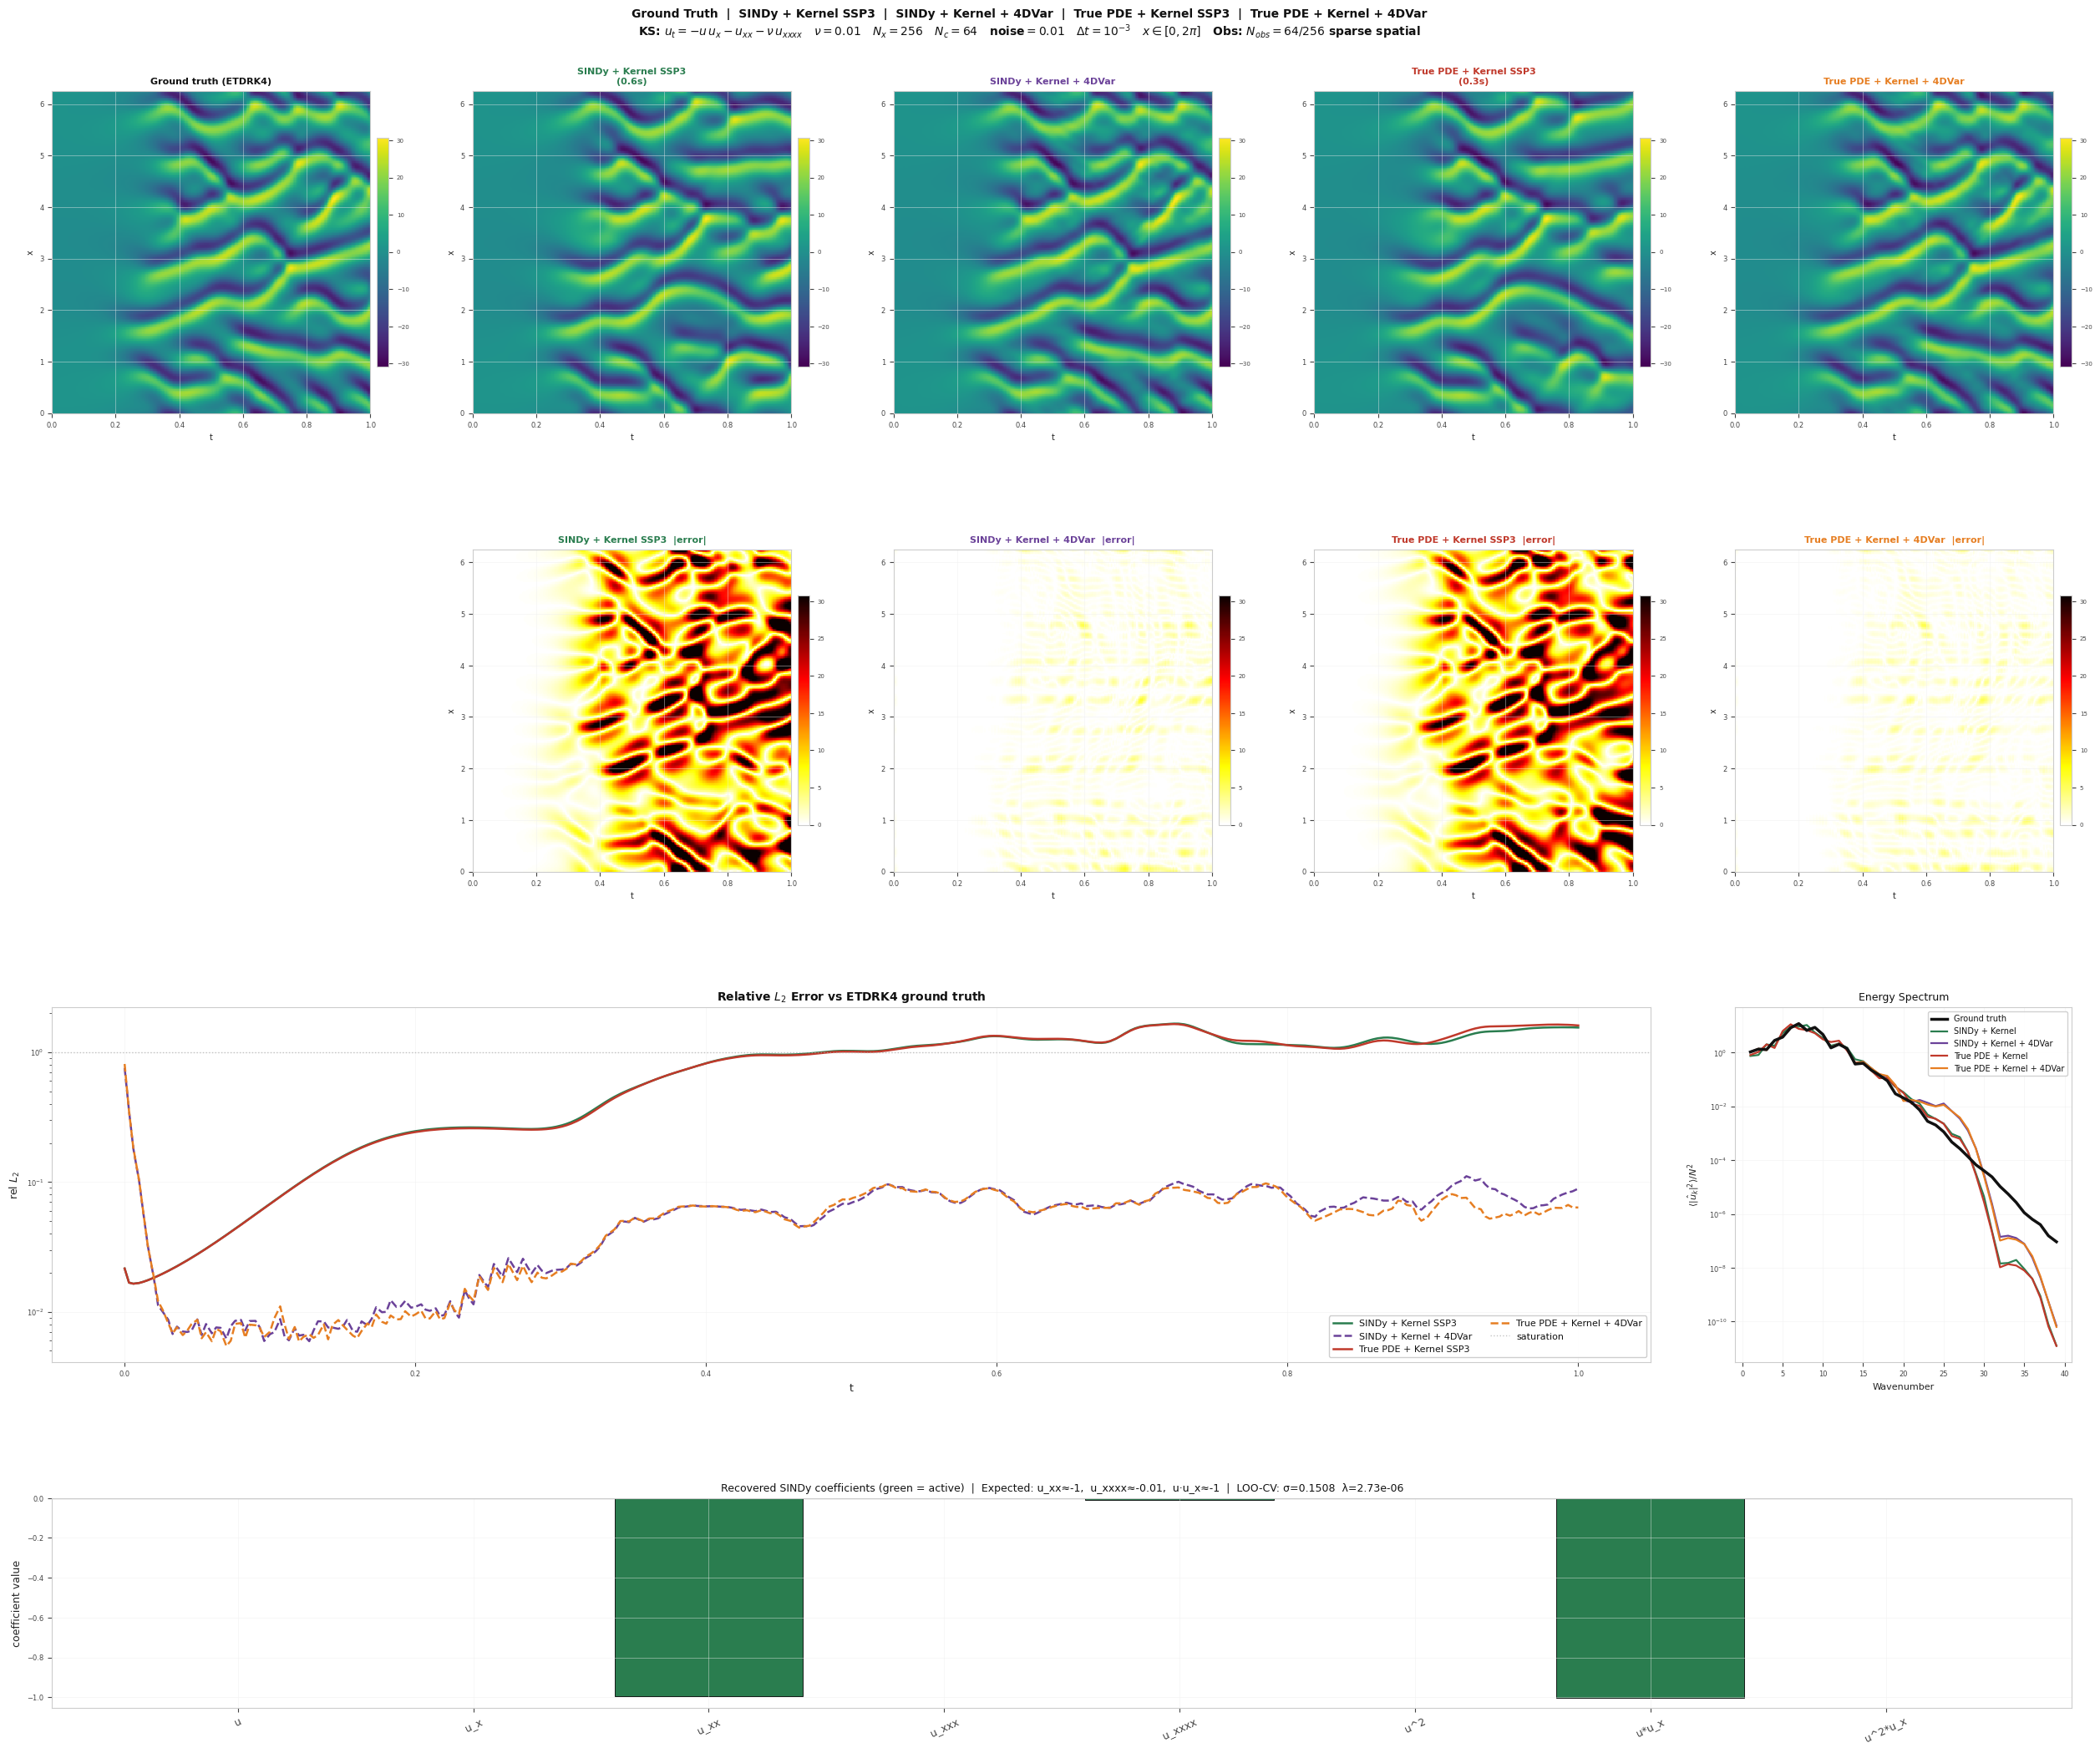

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
from scipy.linalg import cho_factor, cho_solve
from scipy.ndimage import uniform_filter1d


# ================================================================
# Spectral helpers
# ================================================================

def wavenum(N, Ld):
    return 2.0 * np.pi * np.fft.rfftfreq(N, d=Ld / N)


def spec_derivs_rows(F, Ld):
    M, Nx = F.shape
    k  = wavenum(Nx, Ld)
    Fh = np.fft.rfft(F, axis=1)
    Fx    = np.fft.irfft(1j * k[None, :] * Fh,        n=Nx, axis=1)
    Fxx   = np.fft.irfft(-(k[None, :]**2) * Fh,       n=Nx, axis=1)
    Fxxx  = np.fft.irfft(-1j * (k[None, :]**3) * Fh,  n=Nx, axis=1)
    Fxxxx = np.fft.irfft((k[None, :]**4) * Fh,        n=Nx, axis=1)
    return Fx, Fxx, Fxxx, Fxxxx


# ================================================================
# Periodic Gaussian kernel + analytic derivatives
# ================================================================

def ker(x, c, sig, Ld):
    d = np.pi * (x[:, None] - c[None, :]) / Ld
    return np.exp(-2.0 * np.sin(d)**2 / sig**2)


def ker_derivs(x, c, sig, Ld):
    p     = np.pi / Ld
    d     = p * (x[:, None] - c[None, :])
    Phi   = np.exp(-2.0 * np.sin(d)**2 / sig**2)
    f1    = -4.0 * p    * np.sin(d) * np.cos(d) / sig**2
    f1p   = -4.0 * p**2 * np.cos(2 * d)         / sig**2
    f1pp  =  8.0 * p**3 * np.sin(2 * d)         / sig**2
    f1ppp = 16.0 * p**4 * np.cos(2 * d)         / sig**2
    Phi_x    = Phi * f1
    Phi_xx   = Phi * (f1**2 + f1p)
    Phi_xxx  = Phi * (f1**3 + 3*f1*f1p + f1pp)
    Phi_xxxx = Phi * (f1**4 + 6*f1**2*f1p + 3*f1p**2 + 4*f1*f1pp + f1ppp)
    return Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx


# ================================================================
# ETDRK4 ground truth
# ================================================================

def ks_truth_etdrk4(u0, nu, x, dt, nt, Mq=64):
    nx   = x.size
    dx   = x[1] - x[0]
    k    = 2.0 * np.pi * np.fft.fftfreq(nx, d=dx)
    ik   = 1j * k
    Lhat = k**2 - nu * k**4
    E    = np.exp(dt * Lhat)
    E2   = np.exp(0.5 * dt * Lhat)
    roots = np.exp(1j * np.pi * (np.arange(1, Mq + 1) - 0.5) / Mq)
    LR    = dt * Lhat[:, None] + roots[None, :]
    Q  = dt * np.real(np.mean((np.exp(LR / 2.0) - 1.0) / LR, axis=1))
    f1 = dt * np.real(np.mean((-4.0 - LR + np.exp(LR)*(4.0 - 3.0*LR + LR**2)) / LR**3, axis=1))
    f2 = dt * np.real(np.mean((2.0 + LR + np.exp(LR)*(-2.0 + LR)) / LR**3, axis=1))
    f3 = dt * np.real(np.mean((-4.0 - 3.0*LR - LR**2 + np.exp(LR)*(4.0 - LR)) / LR**3, axis=1))
    def N_hat(vhat):
        u  = np.fft.ifft(vhat).real
        ux = np.fft.ifft(ik * vhat).real
        return np.fft.fft(-u * ux)
    U    = np.zeros((nt + 1, nx))
    U[0] = u0
    v    = np.fft.fft(u0)
    for n in range(nt):
        Nv = N_hat(v)
        a  = E2*v + Q*Nv;              Na = N_hat(a)
        b  = E2*v + Q*Na;              Nb = N_hat(b)
        c  = E2*a + Q*(2.0*Nb - Nv);  Nc = N_hat(c)
        v  = E*v + f1*Nv + 2.0*f2*(Na + Nb) + f3*Nc
        U[n + 1] = np.fft.ifft(v).real
    return U


def make_ic(x):
    return (np.cos(x) + 0.1*np.sin(2*x) - 0.1*np.cos(3*x) + 0.05*np.sin(5*x))


def generate_data(Nx=256, Nt_snap=300, t_max=1.0, nu=0.01,
                  x_min=0.0, x_max=2.0*np.pi,
                  noise_std=1e-2, dt_truth=1e-3, truth_refine=8, seed=0,
                  n_obs_x=None):
    x  = np.linspace(x_min, x_max, Nx, endpoint=False)
    u0 = make_ic(x)
    Ld = x_max - x_min
    nt       = int(round(t_max / dt_truth))
    dt_fine  = dt_truth / truth_refine
    nt_fine  = nt * truth_refine
    print(f"    ETDRK4: dt_fine={dt_fine:.2e}  nt_fine={nt_fine} ...")
    U_fine   = ks_truth_etdrk4(u0, nu, x, dt_fine, nt_fine)
    U_truth  = U_fine[::truth_refine][:nt + 1]
    t_full   = np.linspace(0.0, t_max, nt + 1)
    idx      = np.linspace(0, nt, Nt_snap, dtype=int)
    t_snap   = t_full[idx]
    U_true   = U_truth[idx]
    rng      = np.random.default_rng(seed)
    U_obs    = U_true + noise_std * rng.standard_normal(U_true.shape)

    No = Nx if n_obs_x is None else int(n_obs_x)
    No = min(No, Nx)
    if No == Nx:
        obs_idx = np.arange(Nx)
    else:
        obs_idx = np.sort(rng.choice(Nx, No, replace=False))
    x_obs   = x[obs_idx]
    U_obs_s = U_obs[:, obs_idx]

    # print(f"    Spatial obs: No={No}/{Nx}  "
    #       f"({'full grid' if No == Nx else f'{No/Nx*100:.1f}% of grid'})")

    return (x, t_snap, U_true, U_obs, Ld, t_full, U_truth,
            x_obs, obs_idx, U_obs_s)


# ================================================================
# LOO-CV
# ================================================================

def loo_cv_error(U_obs, Phi, lam):
    Nx, Nc = Phi.shape
    Mass   = Phi.T @ Phi + lam * np.eye(Nc)
    cho    = cho_factor(Mass)
    B      = cho_solve(cho, Phi.T)
    H_ii   = np.einsum("ij,ji->i", Phi, B)
    denom  = np.clip(1.0 - H_ii, 1e-6, None)
    total  = 0.0
    for u in U_obs:
        alpha = cho_solve(cho, Phi.T @ u)
        resid = (u - Phi @ alpha) / denom
        total += float(np.dot(resid, resid))
    return total / (len(U_obs) * Nx)


def find_sig_lam(U_obs_s, x_obs, Ld, Nc,
                 sig_fractions_of_Ld=(0.008, 0.016, 0.024, 0.032, 0.048, 0.064, 0.080),
                 lam_multipliers=(1e-6, 1e-4, 1e-2, 1e-1, 5e-1),
                 max_cond=1e10, verbose=False):
    No = len(x_obs)
    centers = np.linspace(0.0, Ld, Nc, endpoint=False)
    best_err, best_sig, best_lam = np.inf, None, None
    if verbose:
        print(f"\n  LOO-CV  Ld={Ld:.4f}  Nc={Nc}  No={No}  "
              f"({len(sig_fractions_of_Ld)}x{len(lam_multipliers)} grid)")
    for sf in sig_fractions_of_Ld:
        sig = Ld * sf
        Phi = ker(x_obs, centers, sig, Ld)
        G   = Phi.T @ Phi
        lam_scale = np.trace(G) / G.shape[0]
        for lm in lam_multipliers:
            lam  = lam_scale * lm
            cond = np.linalg.cond(G + lam * np.eye(Nc))
            if cond > max_cond:
                continue
            err = loo_cv_error(U_obs_s, Phi, lam)
            if verbose:
                # print(f"    sig={sig:.4f} ({sf:.3f}xLd)  lam={lam:.2e}  "
                #       f"LOO={err:.4e}  cond={cond:.1e}")
            if err < best_err:
                best_err, best_sig, best_lam = err, sig, lam
    if best_sig is None:
        raise RuntimeError("LOO-CV: no valid (sig, lam) found.")
    if verbose:
        print(f"\n  -> best: sig={best_sig:.4f}  lam={best_lam:.2e}  "
              f"LOO={best_err:.4e}")
    return best_sig, best_lam


# ================================================================
# Weak SINDy
# ================================================================

WEAK_LABELS = ["u", "u_x", "u_xx", "u_xxx", "u_xxxx",
               "u^2", "u*u_x", "u^2*u_x"]


def _make_spatial_test_fns(x, Ld, n_test_x, width_frac_x):
    Nx      = len(x)
    centers = np.linspace(0.0, Ld, n_test_x, endpoint=False)
    width   = width_frac_x * Ld
    Phi_x   = np.zeros((n_test_x, Nx))
    for i, c in enumerate(centers):
        d = ((x - c + 0.5*Ld) % Ld) - 0.5*Ld
        s = d / width
        inside = np.abs(s) < 1.0
        Phi_x[i, inside] = (1.0 - s[inside]**2)**3
    return Phi_x


def _make_temporal_test_fns(t_obs, n_test_t, width_frac_t):
    Nt    = len(t_obs)
    width = width_frac_t * (t_obs[-1] - t_obs[0])
    cents = np.linspace(t_obs[0] + width, t_obs[-1] - width, n_test_t)
    Psi   = np.zeros((n_test_t, Nt))
    dPsi  = np.zeros((n_test_t, Nt))
    for m, tc in enumerate(cents):
        s      = (t_obs - tc) / width
        inside = np.abs(s) < 1.0
        Psi [m, inside] =  (1.0 - s[inside]**2)**3
        dPsi[m, inside] = -6.0 * s[inside] * (1.0 - s[inside]**2)**2 / width
    return Psi, dPsi


def _build_theta_b(U_den, t_obs, Ld, n_test_x, n_test_t,
                   width_frac_x, width_frac_t):
    Nt, Nx = U_den.shape
    dx     = Ld / Nx
    dt_vec = np.gradient(t_obs)
    x      = np.linspace(0.0, Ld, Nx, endpoint=False)
    Phi_x  = _make_spatial_test_fns(x, Ld, n_test_x, width_frac_x)
    Phi_x1, Phi_x2, Phi_x3, Phi_x4 = spec_derivs_rows(Phi_x, Ld)
    Psi_t, dPsi_t = _make_temporal_test_fns(t_obs, n_test_t, width_frac_t)
    Phi0_w = dx * Phi_x;   Phi1_w = dx * Phi_x1
    Phi2_w = dx * Phi_x2;  Phi3_w = dx * Phi_x3;  Phi4_w = dx * Phi_x4
    Psi_w  = Psi_t  * dt_vec[None, :]
    dPsi_w = dPsi_t * dt_vec[None, :]
    def weak(Q, Pw, Fw):
        return (Pw @ Q @ Fw.T).ravel()
    U2 = U_den**2;  U3 = U_den**3
    b     = -weak(U_den, dPsi_w, Phi0_w)
    Theta = np.column_stack([
        weak(U_den, Psi_w, Phi0_w),
       -weak(U_den, Psi_w, Phi1_w),
       +weak(U_den, Psi_w, Phi2_w),
       -weak(U_den, Psi_w, Phi3_w),
       +weak(U_den, Psi_w, Phi4_w),
        weak(U2,    Psi_w, Phi0_w),
       -0.5    * weak(U2, Psi_w, Phi1_w),
       -(1/3)  * weak(U3, Psi_w, Phi1_w),
    ])
    return Theta, b


def stls_relative(Theta, b, rel_thr=0.05, ridge=1e-8, max_iter=30):
    col_norms = np.linalg.norm(Theta, axis=0)
    col_norms[col_norms == 0.0] = 1.0
    Tn  = Theta / col_norms
    xi  = np.linalg.solve(Tn.T @ Tn + ridge * np.eye(Tn.shape[1]), Tn.T @ b)
    prev = None
    for _ in range(max_iter):
        mx = np.max(np.abs(xi))
        if mx < 1e-15:  xi[:] = 0.0;  break
        active = np.abs(xi) >= rel_thr * mx
        if not np.any(active):  xi[:] = 0.0;  break
        if prev is not None and np.array_equal(active, prev):  break
        xi_new = np.zeros_like(xi)
        Ta = Tn[:, active]
        xi_new[active] = np.linalg.solve(
            Ta.T @ Ta + ridge * np.eye(active.sum()), Ta.T @ b)
        xi = xi_new;  prev = active.copy()
    active = np.abs(xi) > 0
    if np.any(active):
        Ta = Tn[:, active]
        xi_db = np.zeros_like(xi)
        xi_db[active] = np.linalg.lstsq(Ta, b, rcond=None)[0]
        xi = xi_db
    return xi / col_norms


def run_weak_sindy(U_den, t_obs, Ld, n_test_x, n_test_t,
                   width_frac_x, width_frac_t, rel_thr, ridge, verbose=False):
    Theta, b  = _build_theta_b(U_den, t_obs, Ld,
                                n_test_x, n_test_t, width_frac_x, width_frac_t)
    xi        = stls_relative(Theta, b, rel_thr=rel_thr, ridge=ridge)
    resid_rel = np.linalg.norm(Theta @ xi - b) / (np.linalg.norm(b) + 1e-14)
    n_active  = int(np.sum(np.abs(xi) > 1e-10))
    return xi, {"resid_rel": resid_rel, "n_active": n_active}


# ================================================================
# Scoring helpers
# ================================================================

def linear_stability_penalty(xi, Ld, Nx):
    k     = wavenum(Nx, Ld)
    lam_k = (xi[0] + xi[1]*(1j*k) + xi[2]*(-(k**2))
             + xi[3]*(-(1j)*(k**3)) + xi[4]*(k**4))
    pos   = np.maximum(np.real(lam_k), 0.0)
    return float(np.mean(np.minimum(pos, 25.0)**2))


_ssp3_g     = (3.0 + np.sqrt(3.0)) / 6.0
_ssp3_A_imp = np.array([[_ssp3_g,0,0],[1-2*_ssp3_g,_ssp3_g,0],[0.5,0.5-_ssp3_g,_ssp3_g]])
_ssp3_A_exp = np.array([[0,0,0],[1,0,0],[0.25,0.25,0]], dtype=float)
_ssp3_b     = np.array([1/6, 1/6, 2/3], dtype=float)


def _linear_symbol(xi, k):
    return (xi[0] + xi[1]*(1j*k) + xi[2]*(-(k**2))
            + xi[3]*(-(1j*k**3)) + xi[4]*(k**4))


def _N_phys(Ui, Ui_hat, k, xi, Nx):
    Ux = np.fft.irfft(1j * k * Ui_hat, n=Nx)
    return xi[5]*Ui**2 + xi[6]*Ui*Ux + xi[7]*Ui**2*Ux


def _ssp3_kernel_step(alpha, K0, cho, xi, dt, Ld):
    Nx    = K0.shape[0]
    k     = wavenum(Nx, Ld)
    lam   = _linear_symbol(xi, k)
    denom = 1.0 - dt * _ssp3_g * lam
    u_n   = K0 @ alpha
    Vp, Nh_l, Lh_l = [], [], []
    for i in range(3):
        r = u_n.copy()
        for j in range(i):
            if _ssp3_A_exp[i,j]: r = r + dt*_ssp3_A_exp[i,j]*Nh_l[j]
            if _ssp3_A_imp[i,j]: r = r + dt*_ssp3_A_imp[i,j]*Lh_l[j]
        rh  = np.fft.rfft(r)
        Vih = rh / denom
        Vi  = np.fft.irfft(Vih, n=Nx)
        Vp.append(Vi)
        Nh_l.append(_N_phys(Vi, Vih, k, xi, Nx))
        Lh_l.append(np.fft.irfft(lam * Vih, n=Nx))
    u_new = u_n.copy()
    for i in range(3):
        u_new = u_new + dt*(_ssp3_b[i]*Nh_l[i] + _ssp3_b[i]*Lh_l[i])
    if not np.all(np.isfinite(u_new)):
        return alpha, False
    return cho_solve(cho, K0.T @ u_new), True


def rollout_score(x, t_obs, U_true, U_obs, Ld, xi, sig_cv, lam_cv,
                  Nc=64, horizon_frac=0.15):
    c    = np.linspace(0.0, Ld, Nc, endpoint=False)
    K0   = ker(x, c, sig_cv, Ld)
    cho  = cho_factor(K0.T @ K0 + lam_cv * np.eye(Nc))
    alpha = cho_solve(cho, K0.T @ U_obs[0])
    amp0  = np.max(np.abs(K0 @ alpha)) + 1e-14
    dt_r  = np.median(np.diff(t_obs))
    n_steps = max(1, int(round(horizon_frac * (t_obs[-1] - t_obs[0]) / dt_r)))
    U_pred = [K0 @ alpha]
    for _ in range(n_steps):
        try:
            alpha, ok = _ssp3_kernel_step(alpha, K0, cho, xi, dt_r, Ld)
            u = K0 @ alpha
        except Exception:
            return np.inf, False
        if not ok or not np.all(np.isfinite(u)) or np.max(np.abs(u)) > 8.0*amp0:
            return np.inf, False
        U_pred.append(u)
    U_pred = np.array(U_pred)
    t_pred = t_obs[0] + dt_r * np.arange(len(U_pred))
    idx    = [np.argmin(np.abs(t_obs - tt)) for tt in t_pred]
    err    = (np.linalg.norm(U_pred - U_true[idx]) /
              (np.linalg.norm(U_true[idx]) + 1e-14))
    return err, True


def total_score(resid_rel, n_active, stab_pen, pred_err, stable):
    s  = 1.0*resid_rel + 0.08*n_active + 0.2*stab_pen
    s += 2.0*pred_err if stable else 1e6
    return s


# ================================================================
# 3-stage disciplined hyperparameter search
# ================================================================

def _denoise(U_obs, k_cut, t_smooth):
    Nt, Nx = U_obs.shape
    Uh = np.fft.rfft(U_obs, axis=1)
    Uh[:, min(k_cut, Uh.shape[1]):] = 0.0
    U = np.fft.irfft(Uh, n=Nx, axis=1)
    if t_smooth > 1:
        U = uniform_filter1d(U, size=t_smooth, axis=0, mode="nearest")
    return U


def stage1_denoising(U_obs, verbose=False):
    Uh_ref = np.fft.rfft(U_obs, axis=1).copy()
    Uh_ref[:, 40:] = 0.0
    U_ref  = uniform_filter1d(
        np.fft.irfft(Uh_ref, n=U_obs.shape[1], axis=1),
        size=3, axis=0, mode="nearest")
    best = (np.inf, 48, 3)
    if verbose: print("\n  Stage 1 — denoising  (9 candidates)")
    for kc in [32, 48, 64]:
        for ts in [1, 3, 5]:
            U_den = _denoise(U_obs, kc, ts)
            score = float(np.linalg.norm(U_den - U_ref) /
                          (np.linalg.norm(U_ref) + 1e-14))
            if verbose: print(f"    k_cut={kc}  t_smooth={ts}  score={score:.4f}")
            if score < best[0]: best = (score, kc, ts)
    if verbose: print(f"  -> k_cut={best[1]}  t_smooth={best[2]}")
    return best[1], best[2]


def stage2_integration(U_obs, t_obs, Ld, k_cut, t_smooth, verbose=False):
    U_den = _denoise(U_obs, k_cut, t_smooth)
    best  = (np.inf, 16, 24, 0.10, 0.08)
    if verbose: print(f"\n  Stage 2 — integration  (16 candidates)")
    for ntx in [16, 32]:
        for ntt in [24, 48]:
            for wfx in [0.08, 0.14]:
                for wft in [0.06, 0.10]:
                    Theta, b = _build_theta_b(U_den, t_obs, Ld, ntx, ntt, wfx, wft)
                    xi_ls = np.linalg.lstsq(Theta, b, rcond=None)[0]
                    res   = (np.linalg.norm(Theta @ xi_ls - b) /
                             (np.linalg.norm(b) + 1e-14))
                    if verbose:
                        print(f"    ntx={ntx} ntt={ntt} wfx={wfx} wft={wft}  "
                              f"resid={res:.4e}")
                    if res < best[0]: best = (res, ntx, ntt, wfx, wft)
    if verbose:
        print(f"  -> n_test_x={best[1]}  n_test_t={best[2]}  "
              f"width_frac_x={best[3]}  width_frac_t={best[4]}")
    return best[1], best[2], best[3], best[4]


def stage3_sparsity(U_obs, t_obs, Ld, x, k_cut, t_smooth,
                    n_test_x, n_test_t, width_frac_x, width_frac_t,
                    sig_cv, lam_cv, U_true, Nc=64, verbose=False):
    U_den = _denoise(U_obs, k_cut, t_smooth)
    best_score, best_xi, best_params = np.inf, None, (0.05, 1e-8)
    if verbose: print(f"\n  Stage 3 — sparsity  (9 candidates)")
    for rt in [0.03, 0.05, 0.10]:
        for rg in [1e-10, 1e-8, 1e-6]:
            xi, diag = run_weak_sindy(U_den, t_obs, Ld, n_test_x, n_test_t,
                                      width_frac_x, width_frac_t, rt, rg)
            stab = linear_stability_penalty(xi, Ld, len(x))
            pred_err, stable = rollout_score(x, t_obs, U_true, U_obs, Ld,
                                             xi, sig_cv, lam_cv, Nc=Nc)
            sc = total_score(diag["resid_rel"], diag["n_active"],
                             stab, pred_err, stable)
            if verbose:
                print(f"    rel_thr={rt}  ridge={rg:.0e}  "
                      f"resid={diag['resid_rel']:.3e}  n_act={diag['n_active']}  "
                      f"stab={stab:.3e}  "
                      f"pred={'inf' if not stable else f'{pred_err:.3e}'}  "
                      f"score={sc:.4e}")
            if sc < best_score:
                best_score, best_xi, best_params = sc, xi.copy(), (rt, rg)
    if verbose:
        print(f"  -> rel_thr={best_params[0]}  ridge={best_params[1]:.0e}  "
              f"score={best_score:.4e}")
    return best_xi, U_den, best_params


def disciplined_sindy_search(U_obs, t_obs, x, Ld, U_true, sig_cv, lam_cv,
                              Nc=64, verbose=False):
    print("\n" + "="*60)
    print("  Disciplined 3-stage weak-SINDy search  (34 evals)")
    print("="*60)
    k_cut, t_smooth = stage1_denoising(U_obs, verbose=verbose)
    n_test_x, n_test_t, wfx, wft = stage2_integration(
        U_obs, t_obs, Ld, k_cut, t_smooth, verbose=verbose)
    xi, U_den, (rt, rg) = stage3_sparsity(
        U_obs, t_obs, Ld, x, k_cut, t_smooth,
        n_test_x, n_test_t, wfx, wft,
        sig_cv, lam_cv, U_true, Nc=Nc, verbose=verbose)
    print("\n  Final xi:")
    for nm, v in zip(WEAK_LABELS, xi):
        if abs(v) > 1e-10:
            print(f"    {nm:10s}: {v:+.6f}  ***")
        else:
            print(f"    {nm:10s}: {v:+.6f}")
    return xi, U_den


# ================================================================
# IMEX tableau  —  SSP3 only
# ================================================================

_g3        = (3.0 + np.sqrt(3.0)) / 6.0
_sp3_A_exp = np.array([[0,0,0],[1,0,0],[0.25,0.25,0]], dtype=float)
_sp3_A_imp = np.array([[_g3,0,0],[1-2*_g3,_g3,0],[0.5,0.5-_g3,_g3]], dtype=float)
_sp3_b     = np.array([1/6, 1/6, 2/3], dtype=float)


# ================================================================
# Kernel rollout  —  alpha-space IMEX (SSP3)
# ================================================================

def _N_alpha(alpha, Phi, Phi_x, xi):
    u  = Phi   @ alpha
    ux = Phi_x @ alpha
    N  = xi[5]*u**2 + xi[6]*u*ux + xi[7]*u**2*ux
    return Phi.T @ N


def rollout_kernel(u0_obs, x_obs, x, xi, Ld, dt, Nt, Nc, sig, lam_ker,
                   max_amp=50.0):
    Nx  = len(x)
    No  = len(x_obs)
    ns  = len(_sp3_b)

    c    = np.linspace(0.0, Ld, Nc, endpoint=False)
    Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx = ker_derivs(x, c, sig, Ld)
    L_a = (xi[0]*(Phi.T @ Phi)
         + xi[1]*(Phi.T @ Phi_x)
         + xi[2]*(Phi.T @ Phi_xx)
         + xi[3]*(Phi.T @ Phi_xxx)
         + xi[4]*(Phi.T @ Phi_xxxx))

    M         = Phi.T @ Phi
    M_final   = cho_factor(M + lam_ker * np.eye(Nc))

    diag_vals = sorted(set(float(_sp3_A_imp[i, i]) for i in range(ns)))
    M_stages  = {}
    for g in diag_vals:
        A_g = M - dt * g * L_a
        M_stages[g] = cho_factor(A_g + lam_ker * np.eye(Nc))

    Phi_obs = ker(x_obs, c, sig, Ld)
    M_obs   = cho_factor(Phi_obs.T @ Phi_obs + lam_ker * np.eye(Nc))
    alpha   = cho_solve(M_obs, Phi_obs.T @ u0_obs)

    U      = [Phi @ alpha]
    blowup = None
    t0     = time.perf_counter()

    for step in range(Nt):
        Ma_n    = M @ alpha
        stage_N = []
        stage_L = []

        for i in range(ns):
            rhs = Ma_n.copy()
            for j in range(i):
                if _sp3_A_exp[i, j] != 0.0:
                    rhs = rhs + dt * _sp3_A_exp[i, j] * stage_N[j]
                if _sp3_A_imp[i, j] != 0.0:
                    rhs = rhs + dt * _sp3_A_imp[i, j] * stage_L[j]
            g   = float(_sp3_A_imp[i, i])
            a_i = cho_solve(M_stages[g], rhs)
            stage_N.append(_N_alpha(a_i, Phi, Phi_x, xi))
            stage_L.append(L_a @ a_i)

        rhs_f = Ma_n.copy()
        for i in range(ns):
            rhs_f = rhs_f + dt * _sp3_b[i] * (stage_N[i] + stage_L[i])

        alpha_new = cho_solve(M_final, rhs_f)
        u_new     = Phi @ alpha_new

        if not np.all(np.isfinite(u_new)) or np.max(np.abs(u_new)) > max_amp:
            blowup = step
            break

        alpha = alpha_new
        U.append(u_new)

    wt = time.perf_counter() - t0
    if blowup is not None:
        print(f"  [Kernel SSP3] blowup at step {blowup}  (t={blowup*dt:.4f})")

    return np.array(U), wt, blowup


# ================================================================
# 4DVar — RKHS-based weak data assimilation
# ================================================================

from scipy.optimize import minimize as sp_minimize


def _build_4dvar_operators(x, x_obs, xi, Ld, Nc, sig, lam_ker, dt):
    c = np.linspace(0.0, Ld, Nc, endpoint=False)

    Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx = ker_derivs(x, c, sig, Ld)
    M  = Phi.T @ Phi

    L_a = (xi[0]*(Phi.T @ Phi)
         + xi[1]*(Phi.T @ Phi_x)
         + xi[2]*(Phi.T @ Phi_xx)
         + xi[3]*(Phi.T @ Phi_xxx)
         + xi[4]*(Phi.T @ Phi_xxxx))

    M_final   = cho_factor(M + lam_ker * np.eye(Nc))
    diag_vals = sorted(set(float(_sp3_A_imp[i, i]) for i in range(3)))
    M_stages  = {}
    for g in diag_vals:
        M_stages[g] = cho_factor(M - dt * g * L_a + lam_ker * np.eye(Nc))

    Phi_obs        = ker(x_obs, c, sig, Ld)
    PhiObsT_PhiObs = Phi_obs.T @ Phi_obs

    return dict(Phi=Phi, Phi_x=Phi_x, M=M, L_a=L_a,
                M_final=M_final, M_stages=M_stages,
                Phi_obs=Phi_obs, PhiObsT_PhiObs=PhiObsT_PhiObs,
                c=c, dt=dt, Nc=Nc)


def _G_and_jac(alpha, ops, xi):
    Nc       = ops['Nc']
    dt       = ops['dt']
    M        = ops['M']
    L_a      = ops['L_a']
    M_final  = ops['M_final']
    M_stages = ops['M_stages']
    Phi      = ops['Phi']
    Phi_x    = ops['Phi_x']
    ns       = 3

    # ── Forward pass ─────────────────────────────────────────────
    Ma_n = M @ alpha
    stage_a, stage_N, stage_L = [], [], []

    for i in range(ns):
        rhs = Ma_n.copy()
        for j in range(i):
            if _sp3_A_exp[i, j] != 0.0: rhs = rhs + dt * _sp3_A_exp[i, j] * stage_N[j]
            if _sp3_A_imp[i, j] != 0.0: rhs = rhs + dt * _sp3_A_imp[i, j] * stage_L[j]
        g   = float(_sp3_A_imp[i, i])
        a_i = cho_solve(M_stages[g], rhs)
        stage_a.append(a_i)
        stage_N.append(_N_alpha(a_i, Phi, Phi_x, xi))
        stage_L.append(L_a @ a_i)

    rhs_f = Ma_n.copy()
    for i in range(ns):
        rhs_f = rhs_f + dt * _sp3_b[i] * (stage_N[i] + stage_L[i])
    alpha_new = cho_solve(M_final, rhs_f)

    # ── Reverse-mode adjoint closure ─────────────────────────────
    def jac_T_vec(w):
        bar_rhs_f = cho_solve(M_final, w)

        bar_N  = [dt * _sp3_b[i] * bar_rhs_f.copy() for i in range(ns)]
        bar_L  = [dt * _sp3_b[i] * bar_rhs_f.copy() for i in range(ns)]
        bar_Ma = bar_rhs_f.copy()

        for i in reversed(range(ns)):
            bar_ai = L_a.T @ bar_L[i]

            a_i = stage_a[i]
            u   = Phi   @ a_i
            ux  = Phi_x @ a_i
            bar_nphys = Phi @ bar_N[i]
            dn_du  = 2*xi[5]*u + xi[6]*ux + 2*xi[7]*u*ux
            dn_dux = xi[6]*u   + xi[7]*u**2
            bar_ai = bar_ai + Phi.T   @ (bar_nphys * dn_du)
            bar_ai = bar_ai + Phi_x.T @ (bar_nphys * dn_dux)

            g = float(_sp3_A_imp[i, i])
            bar_rhs_i = cho_solve(M_stages[g], bar_ai)

            bar_Ma = bar_Ma + bar_rhs_i
            for j in range(i):
                if _sp3_A_exp[i, j] != 0.0:
                    bar_N[j] = bar_N[j] + dt * _sp3_A_exp[i, j] * bar_rhs_i
                if _sp3_A_imp[i, j] != 0.0:
                    bar_L[j] = bar_L[j] + dt * _sp3_A_imp[i, j] * bar_rhs_i

        return M @ bar_Ma

    return alpha_new, jac_T_vec


def build_4dvar_trajectory(alpha0, N_steps, ops, xi):
    alphas = [alpha0]
    for _ in range(N_steps):
        a_new, _ = _G_and_jac(alphas[-1], ops, xi)
        alphas.append(a_new)
    return alphas


def fdvar_cost_and_grad(z, Y_obs, ops, xi,
                        lam0, lam_mis, lam_dyn, N_steps, Nc):
    Phi_obs = ops['Phi_obs']
    M       = ops['M']

    alphas  = [z[n*Nc:(n+1)*Nc] for n in range(N_steps + 1)]
    grad    = [np.zeros(Nc)       for _ in range(N_steps + 1)]
    J       = 0.0

    Ma0     = M @ alphas[0]
    J      += lam0 * float(alphas[0] @ Ma0)
    grad[0] += 2.0 * lam0 * Ma0

    for n in range(N_steps + 1):
        res      = Phi_obs @ alphas[n] - Y_obs[n]
        J       += lam_mis * float(res @ res)
        grad[n] += 2.0 * lam_mis * (Phi_obs.T @ res)

    for n in range(N_steps):
        alpha_n  = alphas[n]
        alpha_np = alphas[n + 1]
        G_n, jacT = _G_and_jac(alpha_n, ops, xi)
        delta   = alpha_np - G_n
        M_delta = M @ delta
        J      += lam_dyn * float(delta @ M_delta)

        grad[n + 1] += 2.0 * lam_dyn * M_delta
        grad[n]     -= 2.0 * lam_dyn * jacT(M_delta)

    return J, np.concatenate(grad)


def run_4dvar(Y_obs_s, x_obs, x, xi, Ld, Nc, sig, lam_ker, dt,
              lam0=1.0, lam_mis=1.0, lam_dyn=0.1,
              maxiter=200, verbose=False):
    N_steps = len(Y_obs_s) - 1
    ops     = _build_4dvar_operators(x, x_obs, xi, Ld, Nc, sig, lam_ker, dt)
    Phi     = ops['Phi']
    Phi_obs = ops['Phi_obs']
    M_obs   = cho_factor(Phi_obs.T @ Phi_obs + lam_ker * np.eye(Nc))

    alpha0_init = cho_solve(M_obs, Phi_obs.T @ Y_obs_s[0])
    alphas_warm = build_4dvar_trajectory(alpha0_init, N_steps, ops, xi)
    z0 = np.concatenate(alphas_warm)

    if verbose:
        J0, _ = fdvar_cost_and_grad(z0, Y_obs_s, ops, xi,
                                     lam0, lam_mis, lam_dyn, N_steps, Nc)
        print(f"  4DVar warm-start  J={J0:.4e}")

    iters = [0]
    def callback(z):
        iters[0] += 1
        if verbose and iters[0] % 20 == 0:
            J, _ = fdvar_cost_and_grad(z, Y_obs_s, ops, xi,
                                       lam0, lam_mis, lam_dyn, N_steps, Nc)
            print(f"    iter {iters[0]:4d}  J={J:.4e}")

    def fun_and_grad(z):
        return fdvar_cost_and_grad(z, Y_obs_s, ops, xi,
                                   lam0, lam_mis, lam_dyn, N_steps, Nc)

    t0  = time.perf_counter()
    res = sp_minimize(fun_and_grad, z0, method="L-BFGS-B", jac=True,
                      options={"maxiter": maxiter, "ftol": 1e-12,
                               "gtol": 1e-8, "maxcor": 20},
                      callback=callback)
    wt  = time.perf_counter() - t0

    z_opt      = res.x
    alphas_opt = np.array([z_opt[n*Nc:(n+1)*Nc] for n in range(N_steps + 1)])
    U_4dvar    = alphas_opt @ Phi.T

    if verbose:
        print(f"  4DVar done  iters={res.nit}  J={res.fun:.4e}  "
              f"success={res.success}  wall={wt:.2f}s")
        print(f"  message: {res.message}")

    return alphas_opt, U_4dvar, {"res": res, "wt": wt, "nit": res.nit,
                                  "J_final": res.fun, "z0": z0}


# ================================================================
# Metrics
# ================================================================

def rel_l2_t(U_pred, U_ref):
    n = min(len(U_pred), len(U_ref))
    return np.linalg.norm(U_pred[:n]-U_ref[:n], axis=1) / (
           np.linalg.norm(U_ref[:n], axis=1) + 1e-12)


def align_gt(U_pred, t_arr, t_full, U_full):
    n   = len(U_pred)
    idx = [np.argmin(np.abs(t_full - tt)) for tt in t_arr[:n]]
    return U_full[idx]


def spectrum(U):
    return np.mean(np.abs(np.fft.rfft(U, axis=1))**2, axis=0) / U.shape[1]**2


# ================================================================
# Plot  —  kernel rollout + 4DVar
# ================================================================

def _plot(x, t_snap, t_full, U_full,
          U_ker_s, wt_ker_s, blow_ker_s, err_ker_s,
          U_4dv_s, err_4dv_s,
          U_ker_t, wt_ker_t, blow_ker_t, err_ker_t,
          U_4dv_t, err_4dv_t,
          nu, Nc, sig_cv, lam_cv, xi, dt, x_max,
          n_obs_x=None, Nx=256):
    """
    5-column comparison figure:
      Col 0: Ground truth
      Col 1: SINDy + Kernel SSP3
      Col 2: SINDy + Kernel SSP3 + 4DVar
      Col 3: True PDE + Kernel SSP3
      Col 4: True PDE + Kernel SSP3 + 4DVar

    Row 0: solution fields  (shared viridis scale)
    Row 1: pointwise |error| maps  (shared hot_r scale, col 0 blank)
    Row 2: rel-L2(t) all 4 methods  (col 0-3) | energy spectrum (col 4)
    Row 3: SINDy coefficients (full width)
    """
    plt.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white",
        "axes.edgecolor": "#cccccc", "axes.labelcolor": "#222222",
        "xtick.color": "#444444", "ytick.color": "#444444",
        "text.color": "#111111", "grid.color": "#eeeeee",
        "grid.linewidth": 0.6,
    })

    gt_color  = "#111111"
    ks_color  = "#2a7d4f"   # SINDy + Kernel SSP3
    ksd_color = "#6b4299"   # SINDy + Kernel SSP3 + 4DVar
    kt_color  = "#c0392b"   # True PDE + Kernel SSP3
    ktd_color = "#e67e22"   # True PDE + Kernel SSP3 + 4DVar

    Ns = len(t_snap)
    idx_gt = [np.argmin(np.abs(t_full - tt)) for tt in t_snap]
    U_gt   = U_full[idx_gt]
    vm     = np.nanmax(np.abs(U_gt))

    def pad(U):
        if U is None or len(U) == 0: return np.full((Ns, Nx), np.nan)
        if len(U) >= Ns: return U[:Ns]
        return np.vstack([U, np.full((Ns - len(U), Nx), np.nan)])

    err_maps = [
        np.abs(pad(U_ker_s) - U_gt),
        np.abs(pad(U_4dv_s) - U_gt),
        np.abs(pad(U_ker_t) - U_gt),
        np.abs(pad(U_4dv_t) - U_gt),
    ]
    vmax_err = np.nanpercentile(np.concatenate([m.ravel() for m in err_maps]), 98)

    No_str = (f"$N_{{obs}}={n_obs_x}/{Nx}$ sparse spatial"
              if n_obs_x and n_obs_x < Nx else "full spatial grid")

    fig = plt.figure(figsize=(26, 22))
    fig.patch.set_facecolor("white")
    gs = gridspec.GridSpec(4, 5, figure=fig,
                           left=0.05, right=0.98, top=0.93, bottom=0.05,
                           hspace=0.45, wspace=0.25,
                           height_ratios=[1, 1, 1.1, 0.65])

    extent = [t_snap[0], t_snap[-1], x[0], x[-1]]

    def make_ax(r, c, colspan=1):
        ax = fig.add_subplot(gs[r, c] if colspan == 1 else gs[r, c:c+colspan])
        ax.tick_params(labelsize=6)
        ax.grid(True, lw=0.5, alpha=0.6)
        return ax

    def field_im(ax, Z):
        im = ax.imshow(np.nan_to_num(Z).T, aspect="auto", origin="lower",
                       cmap="viridis", extent=extent, vmin=-vm, vmax=vm,
                       interpolation="nearest")
        ax.set_xlabel("t", fontsize=7); ax.set_ylabel("x", fontsize=7)
        return im

    def error_im(ax, Z):
        im = ax.imshow(np.nan_to_num(Z).T, aspect="auto", origin="lower",
                       cmap="hot_r", extent=extent, vmin=0, vmax=vmax_err,
                       interpolation="nearest")
        ax.set_xlabel("t", fontsize=7); ax.set_ylabel("x", fontsize=7)
        return im

    def cb(ax, im):
        c = fig.colorbar(im, ax=ax, fraction=0.034, pad=0.02)
        c.ax.tick_params(labelsize=5)

    def bl(blow, wt=None):
        if blow is not None: return f"\n⚠ blowup@t={blow*dt:.3f}"
        if wt is not None:   return f"\n({wt:.1f}s)"
        return ""

    # ── Row 0: solution fields ────────────────────────────────────
    titles_r0 = [
        ("Ground truth (ETDRK4)",                          gt_color,  U_gt,        None,      None),
        (f"SINDy + Kernel SSP3{bl(blow_ker_s, wt_ker_s)}", ks_color,  U_ker_s, blow_ker_s, wt_ker_s),
        (f"SINDy + Kernel + 4DVar",                        ksd_color, U_4dv_s,     None,      None),
        (f"True PDE + Kernel SSP3{bl(blow_ker_t,wt_ker_t)}",kt_color, U_ker_t, blow_ker_t, wt_ker_t),
        (f"True PDE + Kernel + 4DVar",                     ktd_color, U_4dv_t,     None,      None),
    ]
    for col, (title, color, U, _, _2) in enumerate(titles_r0):
        ax = make_ax(0, col)
        im = field_im(ax, pad(U))
        cb(ax, im)
        ax.set_title(title, fontsize=8, color=color, fontweight="bold")

    # ── Row 1: |error| maps (col 0 blank) ────────────────────────
    ax_blank = make_ax(1, 0)
    ax_blank.set_visible(False)

    err_cfg = [
        (U_ker_s, ks_color,  f"SINDy + Kernel SSP3  |error|{bl(blow_ker_s)}"),
        (U_4dv_s, ksd_color, "SINDy + Kernel + 4DVar  |error|"),
        (U_ker_t, kt_color,  f"True PDE + Kernel SSP3  |error|{bl(blow_ker_t)}"),
        (U_4dv_t, ktd_color, "True PDE + Kernel + 4DVar  |error|"),
    ]
    for col, (U, color, title) in enumerate(err_cfg, start=1):
        ax = make_ax(1, col)
        emap = np.abs(pad(U) - U_gt)
        im = error_im(ax, emap)
        cb(ax, im)
        ax.set_title(title, fontsize=8, color=color, fontweight="bold")

    # ── Row 2: rel-L2(t)  (cols 0-3) + energy spectrum (col 4) ──
    ax_l2 = make_ax(2, 0, colspan=4)

    def plot_err(ax, t, err, blow, color, ls, label):
        n_k = min(len(err), Ns)
        ax.semilogy(t[:n_k], err[:n_k], color=color, lw=1.8, ls=ls, label=label)
        if blow is not None:
            ax.axvline(blow * dt, color=color, lw=1.0, ls=":", alpha=0.6)

    plot_err(ax_l2, t_snap, err_ker_s, blow_ker_s, ks_color,  "-",  "SINDy + Kernel SSP3")
    plot_err(ax_l2, t_snap, err_4dv_s, None,        ksd_color, "--", "SINDy + Kernel + 4DVar")
    plot_err(ax_l2, t_snap, err_ker_t, blow_ker_t,  kt_color,  "-",  "True PDE + Kernel SSP3")
    plot_err(ax_l2, t_snap, err_4dv_t, None,        ktd_color, "--", "True PDE + Kernel + 4DVar")
    ax_l2.axhline(1.0, color="#aaaaaa", lw=1.0, ls=":", alpha=0.7, label="saturation")
    ax_l2.set_xlabel("t", fontsize=9); ax_l2.set_ylabel("rel $L_2$", fontsize=9)
    ax_l2.set_title("Relative $L_2$ Error vs ETDRK4 ground truth",
                    fontsize=10, fontweight="bold")
    ax_l2.legend(fontsize=8, framealpha=0.95, ncol=2)

    ax_sp = make_ax(2, 4)
    modes = np.arange(1, 40)
    ax_sp.semilogy(modes, spectrum(U_gt)[modes],
                   color=gt_color, lw=2.5, label="Ground truth", zorder=5)
    for U, color, label, blow in [
        (U_ker_s, ks_color,  "SINDy + Kernel",           blow_ker_s),
        (U_4dv_s, ksd_color, "SINDy + Kernel + 4DVar",   None),
        (U_ker_t, kt_color,  "True PDE + Kernel",         blow_ker_t),
        (U_4dv_t, ktd_color, "True PDE + Kernel + 4DVar", None),
    ]:
        if blow is None:
            ax_sp.semilogy(modes, spectrum(pad(U))[modes],
                           color=color, lw=1.6, label=label)
    ax_sp.set_xlabel("Wavenumber", fontsize=8)
    ax_sp.set_ylabel(r"$\langle|\hat{u}_k|^2\rangle / N^2$", fontsize=8)
    ax_sp.set_title("Energy Spectrum", fontsize=9)
    ax_sp.legend(fontsize=7, framealpha=0.9)

    # ── Row 3: SINDy coefficients ─────────────────────────────────
    ax_xi = make_ax(3, 0, colspan=5)
    active = np.abs(xi) > 1e-10
    bar_c  = [ks_color if a else "#cccccc" for a in active]
    ax_xi.bar(WEAK_LABELS, xi, color=bar_c, edgecolor="k", linewidth=0.6)
    ax_xi.axhline(0, color="k", linewidth=0.8)
    ax_xi.set_title(
        f"Recovered SINDy coefficients (green = active)  |  "
        f"Expected: u_xx\u2248-1,  u_xxxx\u2248-{nu},  u\u00b7u_x\u2248-1  |  "
        f"LOO-CV: \u03c3={sig_cv:.4f}  \u03bb={lam_cv:.2e}",
        fontsize=9)
    ax_xi.set_ylabel("coefficient value", fontsize=9)
    ax_xi.tick_params(axis="x", rotation=25, labelsize=9)
    ax_xi.grid(True, axis="y", lw=0.5, alpha=0.6)

    fig.suptitle(
        "Ground Truth  |  SINDy + Kernel SSP3  |  SINDy + Kernel + 4DVar  |  "
        "True PDE + Kernel SSP3  |  True PDE + Kernel + 4DVar\n"
        r"KS: $u_t = -u\,u_x - u_{xx} - \nu\,u_{xxxx}$"
        + f"   $\\nu={nu}$   $N_x={Nx}$   $N_c={Nc}$   "
          f"noise$=0.01$   $\\Delta t=10^{{-3}}$   "
          f"$x\\in[0,{x_max/np.pi:.0f}\\pi]$   Obs: {No_str}",
        fontsize=10, fontweight="bold", y=0.975)
    plt.show()


# ================================================================
# Main
# ================================================================

def main():
    Nx           = 256
    x_min, x_max = 0.0, 2.0 * np.pi
    t_max        = 1.0
    dt_truth     = 1e-3
    truth_refine = 8
    nu           = 0.01
    Nt_snap      = 300
    noise_std    = 1e-2
    Nc           = 64
    dt           = dt_truth
    Nt           = int(round(t_max / dt))
    n_obs_x      = 64

    lam0    = 1.0
    lam_mis = 1.0
    lam_dyn = 0.1

    print("="*60)
    print("  Weak SINDy + Kernel SSP3 + RKHS 4DVar")
    print(f"  Spatial obs: No={n_obs_x}/{Nx}  Temporal obs: Nt_snap={Nt_snap}")
    print("="*60)

    # [1] Data
    print(f"\n[1] Generating KS ground truth (ETDRK4, nu={nu}) ...")
    (x, t_obs, U_true, U_obs, Ld, t_full, U_truth_full,
     x_obs, obs_idx, U_obs_s) = generate_data(
        Nx=Nx, Nt_snap=Nt_snap, t_max=t_max, nu=nu,
        x_min=x_min, x_max=x_max, noise_std=noise_std,
        dt_truth=dt_truth, truth_refine=truth_refine, seed=0,
        n_obs_x=n_obs_x)
    print(f"    shape={U_true.shape}  |u|_max={np.max(np.abs(U_true)):.4f}")

    # [2] LOO-CV
    print("\n[2] LOO-CV for kernel hyperparameters ...")
    sig_cv, lam_cv = find_sig_lam(
        U_obs_s, x_obs, Ld, Nc,
        sig_fractions_of_Ld=(0.008,0.016,0.024,0.032,0.048,0.064,0.080),
        lam_multipliers=(1e-6,1e-4,1e-2,1e-1,5e-1),
        verbose=True)

    # [3] Weak SINDy
    print("\n[3] 3-stage weak-SINDy search ...")
    xi_sindy, U_den = disciplined_sindy_search(
        U_obs, t_obs, x, Ld, U_true, sig_cv, lam_cv, Nc=Nc, verbose=True)

    # True PDE coefficients: u_t = -u*u_x - u_xx - nu*u_xxxx
    # xi = [u, u_x, u_xx, u_xxx, u_xxxx, u^2, u*u_x, u^2*u_x]
    xi_true = np.array([0.0, 0.0, -1.0, 0.0, -nu, 0.0, -1.0, 0.0])
    print(f"\n  True xi: {xi_true}")

    def run_ker(label, xi):
        print(f"\n  Kernel SSP3 rollout [{label}] ...")
        t_pred = np.linspace(0, t_max, Nt + 1)
        U, wt, blow = rollout_kernel(
            U_obs_s[0], x_obs, x, xi, Ld, dt, Nt, Nc, sig_cv, lam_cv)
        n = len(U)
        gt  = align_gt(U, t_pred, t_full, U_truth_full)
        err = rel_l2_t(U, gt)
        st  = float(np.mean(err[t_pred[:n] < 0.05])) if blow is None else np.inf
        print(f"    steps={n-1}  wall={wt:.3f}s  short-t err={st:.3e}"
              + ("  BLOWUP" if blow is not None else ""))
        # subsample to snapshot grid
        snap_idx = np.array([np.argmin(np.abs(t_pred[:n] - tt)) for tt in t_obs])
        U_snap   = U[snap_idx]
        err_snap = rel_l2_t(U_snap, U_true)
        return U_snap, wt, blow, err_snap

    def run_dv(label, xi, U_ker_snap):
        print(f"\n  RKHS 4DVar [{label}]  (lam0={lam0} lam_mis={lam_mis} lam_dyn={lam_dyn}) ...")
        _, U_4dv, _ = run_4dvar(
            U_obs_s, x_obs, x, xi, Ld, Nc, sig_cv, lam_cv,
            dt=np.median(np.diff(t_obs)),
            lam0=lam0, lam_mis=lam_mis, lam_dyn=lam_dyn,
            maxiter=300, verbose=True)
        err = rel_l2_t(U_4dv, U_true)
        print(f"    4DVar mean err = {float(np.mean(err)):.3e}")
        return U_4dv, err

    # [4] SINDy xi rollouts
    print("\n[4] SINDy xi rollouts ...")
    U_ker_s, wt_ker_s, blow_ker_s, err_ker_s = run_ker("SINDy",    xi_sindy)
    U_4dv_s, err_4dv_s                        = run_dv("SINDy",    xi_sindy, U_ker_s)

    # [5] True xi rollouts
    print("\n[5] True PDE xi rollouts ...")
    U_ker_t, wt_ker_t, blow_ker_t, err_ker_t = run_ker("True PDE", xi_true)
    U_4dv_t, err_4dv_t                        = run_dv("True PDE", xi_true,  U_ker_t)

    # [6] Summary
    print("\n" + "="*60)
    print(f"  SINDy + Kernel SSP3       mean err = {float(np.mean(err_ker_s)):.3e}")
    print(f"  SINDy + Kernel + 4DVar    mean err = {float(np.mean(err_4dv_s)):.3e}")
    print(f"  True PDE + Kernel SSP3    mean err = {float(np.mean(err_ker_t)):.3e}")
    print(f"  True PDE + Kernel + 4DVar mean err = {float(np.mean(err_4dv_t)):.3e}")
    print("="*60)

    # [7] Plot
    print("\n[7] Plotting ...")
    _plot(x, t_obs, t_full, U_truth_full,
          U_ker_s, wt_ker_s, blow_ker_s, err_ker_s,
          U_4dv_s, err_4dv_s,
          U_ker_t, wt_ker_t, blow_ker_t, err_ker_t,
          U_4dv_t, err_4dv_t,
          nu, Nc, sig_cv, lam_cv, xi_sindy, dt, x_max,
          n_obs_x=len(x_obs), Nx=Nx)


if __name__ == "__main__":
    main()

## 2 step & 1 step comparison

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
from scipy.linalg import cho_factor, cho_solve, expm as _expm
from scipy.ndimage import uniform_filter1d
from scipy.optimize import minimize as sp_minimize


# ══════════════════════════════════════════════════════════════════════════════
# Spectral helpers
# ══════════════════════════════════════════════════════════════════════════════

def wavenum(N, Ld):
    return 2.0 * np.pi * np.fft.rfftfreq(N, d=Ld / N)


def spec_derivs_rows(F, Ld):
    M, Nx = F.shape
    k     = wavenum(Nx, Ld)
    Fh    = np.fft.rfft(F, axis=1)
    Fx    = np.fft.irfft(1j * k[None, :] * Fh,       n=Nx, axis=1)
    Fxx   = np.fft.irfft(-(k[None, :]**2) * Fh,      n=Nx, axis=1)
    Fxxx  = np.fft.irfft(-1j*(k[None, :]**3) * Fh,   n=Nx, axis=1)
    Fxxxx = np.fft.irfft((k[None, :]**4) * Fh,       n=Nx, axis=1)
    return Fx, Fxx, Fxxx, Fxxxx


# ══════════════════════════════════════════════════════════════════════════════
# Periodic Gaussian kernel + analytic derivatives
# ══════════════════════════════════════════════════════════════════════════════

def ker(x, c, sig, Ld):
    d = np.pi * (x[:, None] - c[None, :]) / Ld
    return np.exp(-2.0 * np.sin(d)**2 / sig**2)


def ker_derivs(x, c, sig, Ld):
    p      = np.pi / Ld
    d      = p * (x[:, None] - c[None, :])
    Phi    = np.exp(-2.0 * np.sin(d)**2 / sig**2)
    f1     = -4.0 * p    * np.sin(d) * np.cos(d) / sig**2
    f1p    = -4.0 * p**2 * np.cos(2*d)            / sig**2
    f1pp   =  8.0 * p**3 * np.sin(2*d)            / sig**2
    f1ppp  = 16.0 * p**4 * np.cos(2*d)            / sig**2
    Phi_x    = Phi * f1
    Phi_xx   = Phi * (f1**2 + f1p)
    Phi_xxx  = Phi * (f1**3 + 3*f1*f1p + f1pp)
    Phi_xxxx = Phi * (f1**4 + 6*f1**2*f1p + 3*f1p**2 + 4*f1*f1pp + f1ppp)
    return Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx


# ══════════════════════════════════════════════════════════════════════════════
# ETDRK4 ground truth
# ══════════════════════════════════════════════════════════════════════════════

def ks_truth_etdrk4(u0, nu, x, dt, nt, Mq=64):
    nx   = x.size
    dx   = x[1] - x[0]
    k    = 2.0 * np.pi * np.fft.fftfreq(nx, d=dx)
    ik   = 1j * k
    Lhat = k**2 - nu * k**4
    E    = np.exp(dt * Lhat)
    E2   = np.exp(0.5 * dt * Lhat)
    roots = np.exp(1j * np.pi * (np.arange(1, Mq+1) - 0.5) / Mq)
    LR    = dt * Lhat[:, None] + roots[None, :]
    Q  = dt * np.real(np.mean((np.exp(LR/2.0) - 1.0) / LR, axis=1))
    f1 = dt * np.real(np.mean((-4.0 - LR + np.exp(LR)*(4.0 - 3.0*LR + LR**2)) / LR**3, axis=1))
    f2 = dt * np.real(np.mean((2.0 + LR + np.exp(LR)*(-2.0 + LR)) / LR**3, axis=1))
    f3 = dt * np.real(np.mean((-4.0 - 3.0*LR - LR**2 + np.exp(LR)*(4.0 - LR)) / LR**3, axis=1))

    def N_hat(vhat):
        u  = np.fft.ifft(vhat).real
        ux = np.fft.ifft(ik * vhat).real
        return np.fft.fft(-u * ux)

    U    = np.zeros((nt + 1, nx))
    U[0] = u0
    v    = np.fft.fft(u0)
    for n in range(nt):
        Nv = N_hat(v)
        a  = E2*v + Q*Nv;              Na = N_hat(a)
        b  = E2*v + Q*Na;              Nb = N_hat(b)
        c  = E2*a + Q*(2.0*Nb - Nv);  Nc = N_hat(c)
        v  = E*v + f1*Nv + 2.0*f2*(Na + Nb) + f3*Nc
        U[n+1] = np.fft.ifft(v).real
    return U


def make_ic(x):
    return np.cos(x) + 0.1*np.sin(2*x) - 0.1*np.cos(3*x) + 0.05*np.sin(5*x)


def generate_data(Nx=256, Nt_snap=300, t_max=1.0, nu=0.01,
                  x_min=0.0, x_max=2.0*np.pi,
                  noise_std=1e-2, dt_truth=1e-3, truth_refine=8, seed=0,
                  n_obs_x=None):
    x  = np.linspace(x_min, x_max, Nx, endpoint=False)
    u0 = make_ic(x)
    Ld = x_max - x_min
    nt      = int(round(t_max / dt_truth))
    dt_fine = dt_truth / truth_refine
    nt_fine = nt * truth_refine
    print(f"    ETDRK4: dt_fine={dt_fine:.2e}  nt_fine={nt_fine} ...")
    U_fine  = ks_truth_etdrk4(u0, nu, x, dt_fine, nt_fine)
    U_truth = U_fine[::truth_refine][:nt+1]
    t_full  = np.linspace(0.0, t_max, nt+1)
    idx     = np.linspace(0, nt, Nt_snap, dtype=int)
    t_snap  = t_full[idx]
    U_true  = U_truth[idx]
    rng     = np.random.default_rng(seed)
    U_obs   = U_true + noise_std * rng.standard_normal(U_true.shape)
    No      = Nx if n_obs_x is None else min(int(n_obs_x), Nx)
    obs_idx = np.arange(Nx) if No == Nx else np.sort(rng.choice(Nx, No, replace=False))
    x_obs   = x[obs_idx]
    U_obs_s = U_obs[:, obs_idx]
    print(f"    Spatial obs: No={No}/{Nx}  "
          f"({'full grid' if No == Nx else f'{No/Nx*100:.1f}% of grid'})")
    return (x, t_snap, U_true, U_obs, Ld, t_full, U_truth, x_obs, obs_idx, U_obs_s)


# ══════════════════════════════════════════════════════════════════════════════
# LOO-CV
# ══════════════════════════════════════════════════════════════════════════════

def loo_cv_error(U_obs, Phi, lam):
    Nx, Nc = Phi.shape
    cho    = cho_factor(Phi.T @ Phi + lam * np.eye(Nc))
    B      = cho_solve(cho, Phi.T)
    H_ii   = np.einsum("ij,ji->i", Phi, B)
    denom  = np.clip(1.0 - H_ii, 1e-6, None)
    total  = 0.0
    for u in U_obs:
        alpha = cho_solve(cho, Phi.T @ u)
        resid = (u - Phi @ alpha) / denom
        total += float(np.dot(resid, resid))
    return total / (len(U_obs) * Nx)


def find_sig_lam(U_obs_s, x_obs, Ld, Nc,
                 sig_fractions_of_Ld=(0.008, 0.016, 0.024, 0.032, 0.048, 0.064, 0.080),
                 lam_multipliers=(1e-6, 1e-4, 1e-2, 1e-1, 5e-1),
                 max_cond=1e10, verbose=False):
    centers = np.linspace(0.0, Ld, Nc, endpoint=False)
    best_err, best_sig, best_lam = np.inf, None, None
    if verbose:
        print(f"\n  LOO-CV  ({len(sig_fractions_of_Ld)}x{len(lam_multipliers)} grid)")
    for sf in sig_fractions_of_Ld:
        sig = Ld * sf
        Phi = ker(x_obs, centers, sig, Ld)
        G   = Phi.T @ Phi
        lam_scale = np.trace(G) / G.shape[0]
        for lm in lam_multipliers:
            lam  = lam_scale * lm
            cond = np.linalg.cond(G + lam * np.eye(Nc))
            if cond > max_cond:
                continue
            err = loo_cv_error(U_obs_s, Phi, lam)
            if verbose:
                print(f"    sig={sig:.4f} ({sf:.3f}xLd)  lam={lam:.2e}  "
                      f"LOO={err:.4e}  cond={cond:.1e}")
            if err < best_err:
                best_err, best_sig, best_lam = err, sig, lam
    if best_sig is None:
        raise RuntimeError("LOO-CV: no valid (sig, lam) found.")
    if verbose:
        print(f"\n  -> best: sig={best_sig:.4f}  lam={best_lam:.2e}  LOO={best_err:.4e}")
    return best_sig, best_lam


# ══════════════════════════════════════════════════════════════════════════════
# Weak SINDy helpers (shared by both methods)
# ══════════════════════════════════════════════════════════════════════════════

WEAK_LABELS = ["u", "u_x", "u_xx", "u_xxx", "u_xxxx",
               "u^2", "u*u_x", "u^2*u_x"]


def _make_spatial_test_fns(x, Ld, n_test_x, width_frac_x):
    Nx      = len(x)
    centers = np.linspace(0.0, Ld, n_test_x, endpoint=False)
    width   = width_frac_x * Ld
    Phi_x   = np.zeros((n_test_x, Nx))
    for i, c in enumerate(centers):
        d      = ((x - c + 0.5*Ld) % Ld) - 0.5*Ld
        s      = d / width
        inside = np.abs(s) < 1.0
        Phi_x[i, inside] = (1.0 - s[inside]**2)**3
    return Phi_x


def _make_temporal_test_fns(t_obs, n_test_t, width_frac_t):
    Nt    = len(t_obs)
    width = width_frac_t * (t_obs[-1] - t_obs[0])
    cents = np.linspace(t_obs[0] + width, t_obs[-1] - width, n_test_t)
    Psi   = np.zeros((n_test_t, Nt))
    dPsi  = np.zeros((n_test_t, Nt))
    for m, tc in enumerate(cents):
        s      = (t_obs - tc) / width
        inside = np.abs(s) < 1.0
        Psi [m, inside] =  (1.0 - s[inside]**2)**3
        dPsi[m, inside] = -6.0 * s[inside] * (1.0 - s[inside]**2)**2 / width
    return Psi, dPsi


def _build_theta_b(U, t_obs, Ld, n_test_x, n_test_t, width_frac_x, width_frac_t):
    Nt, Nx = U.shape
    dx     = Ld / Nx
    dt_vec = np.gradient(t_obs)
    x      = np.linspace(0.0, Ld, Nx, endpoint=False)
    Psi_x  = _make_spatial_test_fns(x, Ld, n_test_x, width_frac_x)
    Px1, Px2, Px3, Px4 = spec_derivs_rows(Psi_x, Ld)
    Psi_t, dPsi_t = _make_temporal_test_fns(t_obs, n_test_t, width_frac_t)
    P0w = dx*Psi_x; P1w = dx*Px1; P2w = dx*Px2; P3w = dx*Px3; P4w = dx*Px4
    Ptw  = Psi_t  * dt_vec[None, :]
    dPtw = dPsi_t * dt_vec[None, :]

    def weak(Q, Fw):
        return (Ptw @ Q @ Fw.T).ravel()

    U2 = U**2; U3 = U**3
    b     = -(dPtw @ U @ P0w.T).ravel()
    Theta = np.column_stack([
        weak(U,   P0w),  -weak(U,   P1w),  +weak(U,   P2w),
       -weak(U,   P3w),  +weak(U,   P4w),
        weak(U2,  P0w),  -0.5*(weak(U2, P1w)),  -(1.0/3.0)*(weak(U3, P1w)),
    ])
    return Theta, b, Ptw, dPtw, P0w, P1w, P2w, P3w, P4w


def stls_relative(Theta, b, rel_thr=0.05, ridge=1e-8, max_iter=30):
    col_norms = np.linalg.norm(Theta, axis=0)
    col_norms[col_norms == 0.0] = 1.0
    Tn  = Theta / col_norms
    xi  = np.linalg.solve(Tn.T @ Tn + ridge * np.eye(Tn.shape[1]), Tn.T @ b)
    prev = None
    for _ in range(max_iter):
        mx = np.max(np.abs(xi))
        if mx < 1e-15: xi[:] = 0.0; break
        active = np.abs(xi) >= rel_thr * mx
        if not np.any(active): xi[:] = 0.0; break
        if prev is not None and np.array_equal(active, prev): break
        xi_new = np.zeros_like(xi)
        Ta = Tn[:, active]
        xi_new[active] = np.linalg.solve(Ta.T@Ta + ridge*np.eye(active.sum()), Ta.T@b)
        xi = xi_new; prev = active.copy()
    active = np.abs(xi) > 0
    if np.any(active):
        Ta = Tn[:, active]
        xi_db = np.zeros_like(xi)
        xi_db[active] = np.linalg.lstsq(Ta, b, rcond=None)[0]
        xi = xi_db
    return xi / col_norms


def run_weak_sindy(U_den, t_obs, Ld, n_test_x, n_test_t,
                   width_frac_x, width_frac_t, rel_thr, ridge):
    Theta, b, *_ = _build_theta_b(U_den, t_obs, Ld, n_test_x, n_test_t,
                                   width_frac_x, width_frac_t)
    xi        = stls_relative(Theta, b, rel_thr=rel_thr, ridge=ridge)
    resid_rel = np.linalg.norm(Theta @ xi - b) / (np.linalg.norm(b) + 1e-14)
    return xi, {"resid_rel": resid_rel, "n_active": int(np.sum(np.abs(xi) > 1e-10))}


# ══════════════════════════════════════════════════════════════════════════════
# 2-step method — Step 1: 3-stage disciplined SINDy search
# ══════════════════════════════════════════════════════════════════════════════

def linear_stability_penalty(xi, Ld, Nx):
    k     = wavenum(Nx, Ld)
    lam_k = (xi[0] + xi[1]*(1j*k) + xi[2]*(-(k**2))
             + xi[3]*(-(1j)*(k**3)) + xi[4]*(k**4))
    pos   = np.maximum(np.real(lam_k), 0.0)
    return float(np.mean(np.minimum(pos, 25.0)**2))


_ssp3_g     = (3.0 + np.sqrt(3.0)) / 6.0
_ssp3_A_imp = np.array([[_ssp3_g,0,0],[1-2*_ssp3_g,_ssp3_g,0],
                         [0.5,0.5-_ssp3_g,_ssp3_g]])
_ssp3_A_exp = np.array([[0,0,0],[1,0,0],[0.25,0.25,0]], dtype=float)
_ssp3_b     = np.array([1/6, 1/6, 2/3], dtype=float)


def _linear_symbol(xi, k):
    return (xi[0] + xi[1]*(1j*k) + xi[2]*(-(k**2))
            + xi[3]*(-(1j*k**3)) + xi[4]*(k**4))


def _N_phys(Ui, Ui_hat, k, xi, Nx):
    Ux = np.fft.irfft(1j * k * Ui_hat, n=Nx)
    return xi[5]*Ui**2 + xi[6]*Ui*Ux + xi[7]*Ui**2*Ux


def _ssp3_kernel_step(alpha, K0, cho, xi, dt, Ld):
    Nx  = K0.shape[0]
    k   = wavenum(Nx, Ld)
    lam = _linear_symbol(xi, k)
    den = 1.0 - dt * _ssp3_g * lam
    u_n = K0 @ alpha
    Vp, Nh_l, Lh_l = [], [], []
    for i in range(3):
        r = u_n.copy()
        for j in range(i):
            if _ssp3_A_exp[i,j]: r += dt*_ssp3_A_exp[i,j]*Nh_l[j]
            if _ssp3_A_imp[i,j]: r += dt*_ssp3_A_imp[i,j]*Lh_l[j]
        rh  = np.fft.rfft(r)
        Vih = rh / den
        Vi  = np.fft.irfft(Vih, n=Nx)
        Vp.append(Vi)
        Nh_l.append(_N_phys(Vi, Vih, k, xi, Nx))
        Lh_l.append(np.fft.irfft(lam * Vih, n=Nx))
    u_new = u_n.copy()
    for i in range(3):
        u_new += dt*(_ssp3_b[i]*Nh_l[i] + _ssp3_b[i]*Lh_l[i])
    if not np.all(np.isfinite(u_new)):
        return alpha, False
    return cho_solve(cho, K0.T @ u_new), True


def rollout_score(x, t_obs, U_true, U_obs, Ld, xi, sig_cv, lam_cv,
                  Nc=64, horizon_frac=0.15):
    c     = np.linspace(0.0, Ld, Nc, endpoint=False)
    K0    = ker(x, c, sig_cv, Ld)
    cho   = cho_factor(K0.T @ K0 + lam_cv * np.eye(Nc))
    alpha = cho_solve(cho, K0.T @ U_obs[0])
    amp0  = np.max(np.abs(K0 @ alpha)) + 1e-14
    dt_r  = np.median(np.diff(t_obs))
    n_steps = max(1, int(round(horizon_frac * (t_obs[-1] - t_obs[0]) / dt_r)))
    U_pred  = [K0 @ alpha]
    for _ in range(n_steps):
        try:
            alpha, ok = _ssp3_kernel_step(alpha, K0, cho, xi, dt_r, Ld)
            u = K0 @ alpha
        except Exception:
            return np.inf, False
        if not ok or not np.all(np.isfinite(u)) or np.max(np.abs(u)) > 8.0*amp0:
            return np.inf, False
        U_pred.append(u)
    U_pred = np.array(U_pred)
    t_pred = t_obs[0] + dt_r * np.arange(len(U_pred))
    idx    = [np.argmin(np.abs(t_obs - tt)) for tt in t_pred]
    err    = (np.linalg.norm(U_pred - U_true[idx]) /
              (np.linalg.norm(U_true[idx]) + 1e-14))
    return err, True


def total_score(resid_rel, n_active, stab_pen, pred_err, stable):
    s  = 1.0*resid_rel + 0.08*n_active + 0.2*stab_pen
    s += 2.0*pred_err if stable else 1e6
    return s


def _denoise(U_obs, k_cut, t_smooth):
    Nt, Nx = U_obs.shape
    Uh = np.fft.rfft(U_obs, axis=1)
    Uh[:, min(k_cut, Uh.shape[1]):] = 0.0
    U  = np.fft.irfft(Uh, n=Nx, axis=1)
    if t_smooth > 1:
        U = uniform_filter1d(U, size=t_smooth, axis=0, mode="nearest")
    return U


def disciplined_sindy_search(U_obs, t_obs, x, Ld, U_true, sig_cv, lam_cv,
                              Nc=64, verbose=True):
    """2-step method Step 1: Weak SINDy to recover ξ."""
    # print("\n" + "="*60)
    # print("  2-step — Step 1: Disciplined weak-SINDy search")
    # print("="*60)

    # Stage 1: denoising
    Uh_ref = np.fft.rfft(U_obs, axis=1).copy(); Uh_ref[:, 40:] = 0.0
    U_ref  = uniform_filter1d(np.fft.irfft(Uh_ref, n=U_obs.shape[1], axis=1),
                               size=3, axis=0, mode="nearest")
    best1  = (np.inf, 48, 3)
    for kc in [32, 48, 64]:
        for ts in [1, 3, 5]:
            U_den = _denoise(U_obs, kc, ts)
            sc    = float(np.linalg.norm(U_den - U_ref) /
                          (np.linalg.norm(U_ref) + 1e-14))
            if sc < best1[0]: best1 = (sc, kc, ts)
    k_cut, t_smooth = best1[1], best1[2]
    # if verbose: print(f"  Stage 1: k_cut={k_cut}  t_smooth={t_smooth}")

    # Stage 2: integration params
    U_den = _denoise(U_obs, k_cut, t_smooth)
    best2 = (np.inf, 16, 24, 0.10, 0.08)
    for ntx in [16, 32]:
        for ntt in [24, 48]:
            for wfx in [0.08, 0.14]:
                for wft in [0.06, 0.10]:
                    T, b, *_ = _build_theta_b(U_den, t_obs, Ld, ntx, ntt, wfx, wft)
                    xi_ls = np.linalg.lstsq(T, b, rcond=None)[0]
                    res   = np.linalg.norm(T @ xi_ls - b) / (np.linalg.norm(b) + 1e-14)
                    if res < best2[0]: best2 = (res, ntx, ntt, wfx, wft)
    _, ntx, ntt, wfx, wft = best2
    # if verbose: print(f"  Stage 2: ntx={ntx} ntt={ntt} wfx={wfx} wft={wft}")

    # Stage 3: sparsity
    best_sc, best_xi = np.inf, None
    for rt in [0.03, 0.05, 0.10]:
        for rg in [1e-10, 1e-8, 1e-6]:
            xi, diag = run_weak_sindy(U_den, t_obs, Ld, ntx, ntt, wfx, wft, rt, rg)
            stab     = linear_stability_penalty(xi, Ld, len(x))
            pred_err, stable = rollout_score(x, t_obs, U_true, U_obs, Ld,
                                              xi, sig_cv, lam_cv, Nc=Nc)
            sc = total_score(diag["resid_rel"], diag["n_active"], stab, pred_err, stable)
            if sc < best_sc: best_sc, best_xi = sc, xi.copy()

    if verbose:
        print(f"\n  ξ (2-step SINDy):")
        for nm, v in zip(WEAK_LABELS, best_xi):
            print(f"    {nm:12s}: {v:+.6f}" + ("  ***" if abs(v) > 1e-10 else ""))
    return best_xi, (ntx, ntt, wfx, wft)


# ══════════════════════════════════════════════════════════════════════════════
# 2-step method — Step 2: Kernel SSP3 rollout + 4DVar
# ══════════════════════════════════════════════════════════════════════════════

def _N_alpha(alpha, Phi, Phi_x, xi):
    u  = Phi   @ alpha
    ux = Phi_x @ alpha
    return Phi.T @ (xi[5]*u**2 + xi[6]*u*ux + xi[7]*u**2*ux)


def rollout_kernel(u0_obs, x_obs, x, xi, Ld, dt, Nt, Nc, sig, lam_ker,
                   max_amp=50.0):
    """Kernel SSP3 rollout with fixed ξ (stage solvers built once)."""
    ns = len(_ssp3_b)
    c  = np.linspace(0.0, Ld, Nc, endpoint=False)
    Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx = ker_derivs(x, c, sig, Ld)
    M   = Phi.T @ Phi
    L_a = (xi[0]*(Phi.T@Phi)    + xi[1]*(Phi.T@Phi_x)
         + xi[2]*(Phi.T@Phi_xx) + xi[3]*(Phi.T@Phi_xxx)
         + xi[4]*(Phi.T@Phi_xxxx))
    M_final  = cho_factor(M + lam_ker * np.eye(Nc))
    diag_gs  = sorted(set(float(_ssp3_A_imp[i, i]) for i in range(ns)))
    M_stages = {g: cho_factor(M - dt*g*L_a + lam_ker*np.eye(Nc)) for g in diag_gs}
    Phi_obs  = ker(x_obs, c, sig, Ld)
    M_obs    = cho_factor(Phi_obs.T @ Phi_obs + lam_ker * np.eye(Nc))
    alpha    = cho_solve(M_obs, Phi_obs.T @ u0_obs)
    U        = [Phi @ alpha]
    blowup   = None
    t0       = time.perf_counter()
    for step in range(Nt):
        Ma_n   = M @ alpha
        sN, sL = [], []
        for i in range(ns):
            rhs = Ma_n.copy()
            for j in range(i):
                if _ssp3_A_exp[i,j]: rhs += dt * _ssp3_A_exp[i,j] * sN[j]
                if _ssp3_A_imp[i,j]: rhs += dt * _ssp3_A_imp[i,j] * sL[j]
            a_i = cho_solve(M_stages[float(_ssp3_A_imp[i,i])], rhs)
            sN.append(_N_alpha(a_i, Phi, Phi_x, xi))
            sL.append(L_a @ a_i)
        rhs_f = Ma_n.copy()
        for i in range(ns): rhs_f += dt * _ssp3_b[i] * (sN[i] + sL[i])
        alpha_new = cho_solve(M_final, rhs_f)
        u_new     = Phi @ alpha_new
        if not np.all(np.isfinite(u_new)) or np.max(np.abs(u_new)) > max_amp:
            blowup = step; break
        alpha = alpha_new; U.append(u_new)
    wt = time.perf_counter() - t0
    if blowup is not None:
        print(f"  [Kernel SSP3] blowup at step {blowup}  (t={blowup*dt:.4f})")
    return np.array(U), wt, blowup


def _build_4dvar_operators(x, x_obs, xi, Ld, Nc, sig, lam_ker, dt):
    c = np.linspace(0.0, Ld, Nc, endpoint=False)
    Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx = ker_derivs(x, c, sig, Ld)
    M   = Phi.T @ Phi
    L_a = (xi[0]*(Phi.T@Phi)    + xi[1]*(Phi.T@Phi_x)
         + xi[2]*(Phi.T@Phi_xx) + xi[3]*(Phi.T@Phi_xxx)
         + xi[4]*(Phi.T@Phi_xxxx))
    M_final  = cho_factor(M + lam_ker * np.eye(Nc))
    diag_gs  = sorted(set(float(_ssp3_A_imp[i, i]) for i in range(3)))
    M_stages = {g: cho_factor(M - dt*g*L_a + lam_ker*np.eye(Nc)) for g in diag_gs}
    Phi_obs  = ker(x_obs, c, sig, Ld)
    return dict(Phi=Phi, Phi_x=Phi_x, M=M, L_a=L_a,
                M_final=M_final, M_stages=M_stages,
                Phi_obs=Phi_obs, c=c, dt=dt, Nc=Nc)


def _G_and_jac(alpha, ops, xi):
    Nc = ops['Nc']; dt = ops['dt']; M = ops['M']; L_a = ops['L_a']
    M_final = ops['M_final']; M_stages = ops['M_stages']
    Phi = ops['Phi']; Phi_x = ops['Phi_x']; ns = 3
    Ma_n = M @ alpha
    stage_a, stage_N, stage_L = [], [], []
    for i in range(ns):
        rhs = Ma_n.copy()
        for j in range(i):
            if _ssp3_A_exp[i,j]: rhs += dt * _ssp3_A_exp[i,j] * stage_N[j]
            if _ssp3_A_imp[i,j]: rhs += dt * _ssp3_A_imp[i,j] * stage_L[j]
        a_i = cho_solve(M_stages[float(_ssp3_A_imp[i,i])], rhs)
        stage_a.append(a_i)
        stage_N.append(_N_alpha(a_i, Phi, Phi_x, xi))
        stage_L.append(L_a @ a_i)
    rhs_f = Ma_n.copy()
    for i in range(ns): rhs_f += dt * _ssp3_b[i] * (stage_N[i] + stage_L[i])
    alpha_new = cho_solve(M_final, rhs_f)

    def jac_T_vec(w):
        bar_rhs_f = cho_solve(M_final, w)
        bar_N  = [dt * _ssp3_b[i] * bar_rhs_f.copy() for i in range(ns)]
        bar_L  = [dt * _ssp3_b[i] * bar_rhs_f.copy() for i in range(ns)]
        bar_Ma = bar_rhs_f.copy()
        for i in reversed(range(ns)):
            bar_ai = L_a.T @ bar_L[i]
            a_i = stage_a[i]; u = Phi @ a_i; ux = Phi_x @ a_i
            bnp = Phi @ bar_N[i]
            bar_ai += Phi.T   @ (bnp * (2*xi[5]*u + xi[6]*ux + 2*xi[7]*u*ux))
            bar_ai += Phi_x.T @ (bnp * (xi[6]*u  + xi[7]*u**2))
            bar_rhs_i = cho_solve(M_stages[float(_ssp3_A_imp[i,i])], bar_ai)
            bar_Ma += bar_rhs_i
            for j in range(i):
                if _ssp3_A_exp[i,j]: bar_N[j] += dt * _ssp3_A_exp[i,j] * bar_rhs_i
                if _ssp3_A_imp[i,j]: bar_L[j] += dt * _ssp3_A_imp[i,j] * bar_rhs_i
        return M @ bar_Ma
    return alpha_new, jac_T_vec


def fdvar_cost_and_grad(z, Y_obs, ops, xi, lam0, lam_mis, lam_dyn, N_steps, Nc):
    Phi_obs = ops['Phi_obs']; M = ops['M']
    alphas  = [z[n*Nc:(n+1)*Nc] for n in range(N_steps+1)]
    grad    = [np.zeros(Nc) for _ in range(N_steps+1)]
    J       = 0.0
    Ma0     = M @ alphas[0]
    J      += lam0 * float(alphas[0] @ Ma0)
    grad[0] += 2.0 * lam0 * Ma0
    for n in range(N_steps+1):
        res = Phi_obs @ alphas[n] - Y_obs[n]
        J      += lam_mis * float(res @ res)
        grad[n] += 2.0 * lam_mis * (Phi_obs.T @ res)
    for n in range(N_steps):
        G_n, jacT = _G_and_jac(alphas[n], ops, xi)
        delta   = alphas[n+1] - G_n
        M_delta = M @ delta
        J      += lam_dyn * float(delta @ M_delta)
        grad[n+1] += 2.0 * lam_dyn * M_delta
        grad[n]   -= 2.0 * lam_dyn * jacT(M_delta)
    return J, np.concatenate(grad)


def run_4dvar(Y_obs_s, x_obs, x, xi, Ld, Nc, sig, lam_ker, dt,
              lam0=1.0, lam_mis=1.0, lam_dyn=0.1, maxiter=200, verbose=True):
    """2-step method Step 2: RKHS 4DVar with fixed ξ from SINDy."""
    N_steps = len(Y_obs_s) - 1
    ops     = _build_4dvar_operators(x, x_obs, xi, Ld, Nc, sig, lam_ker, dt)
    Phi     = ops['Phi']; Phi_obs = ops['Phi_obs']
    M_obs   = cho_factor(Phi_obs.T @ Phi_obs + lam_ker * np.eye(Nc))
    alpha0  = cho_solve(M_obs, Phi_obs.T @ Y_obs_s[0])
    alphas_warm = [alpha0]
    for _ in range(N_steps):
        a_new, _ = _G_and_jac(alphas_warm[-1], ops, xi)
        alphas_warm.append(a_new)
    z0 = np.concatenate(alphas_warm)
    # if verbose:
        # J0, _ = fdvar_cost_and_grad(z0, Y_obs_s, ops, xi, lam0, lam_mis, lam_dyn, N_steps, Nc)
        # print(f"  4DVar warm-start  J={J0:.4e}")
    iters = [0]
    def callback(z):
        iters[0] += 1
        if verbose and iters[0] % 20 == 0:
            J, _ = fdvar_cost_and_grad(z, Y_obs_s, ops, xi, lam0, lam_mis, lam_dyn, N_steps, Nc)
            print(f"    iter {iters[0]:4d}  J={J:.4e}")
    t0  = time.perf_counter()
    res = sp_minimize(
        lambda z: fdvar_cost_and_grad(z, Y_obs_s, ops, xi, lam0, lam_mis, lam_dyn, N_steps, Nc),
        z0, method="L-BFGS-B", jac=True,
        options={"maxiter": maxiter, "ftol": 1e-12, "gtol": 1e-8, "maxcor": 20},
        callback=callback)
    wt = time.perf_counter() - t0
    z_opt      = res.x
    alphas_opt = np.array([z_opt[n*Nc:(n+1)*Nc] for n in range(N_steps+1)])
    U_4dvar    = alphas_opt @ Phi.T
    # if verbose:
    #     print(f"  4DVar done  iters={res.nit}  J={res.fun:.4e}  "
    #           f"success={res.success}  wall={wt:.2f}s")
    return alphas_opt, U_4dvar, {"res": res, "wt": wt}


# ══════════════════════════════════════════════════════════════════════════════
# 1-step method — Kernel ETDRK4 dynamics
# ══════════════════════════════════════════════════════════════════════════════

_MAX_REAL_EIGVAL = 10.0


def _build_La(xi, Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx):
    return (xi[0]*(Phi.T@Phi)    + xi[1]*(Phi.T@Phi_x)
          + xi[2]*(Phi.T@Phi_xx) + xi[3]*(Phi.T@Phi_xxx)
          + xi[4]*(Phi.T@Phi_xxxx))


def _ker_etdrk4_coeffs(La, M_inv, dt, Mq=16):
    Nc     = La.shape[0]
    La_eff = M_inv @ La
    eigvals = np.linalg.eigvals(La_eff)
    max_re  = float(np.max(np.real(eigvals)))
    if max_re > _MAX_REAL_EIGVAL:
        La_eff = La_eff - (max_re - _MAX_REAL_EIGVAL) * np.eye(Nc)
    Z  = dt * La_eff
    E  = _expm(Z); E2 = _expm(0.5 * Z)
    roots = np.exp(1j * np.pi * (np.arange(1, Mq+1) - 0.5) / Mq)
    Q_acc = np.zeros((Nc,Nc)); F1_acc = np.zeros((Nc,Nc))
    F2_acc= np.zeros((Nc,Nc)); F3_acc = np.zeros((Nc,Nc))
    I = np.eye(Nc)
    for r in roots:
        Zr  = Z + r*I; eZr = _expm(Zr); eZ2 = _expm(0.5*Zr)
        iZr = np.linalg.solve(Zr, I)
        iZr3= np.linalg.solve(Zr@Zr@Zr, I)
        Q_acc  += np.real((eZ2 - I) @ iZr)
        F1_acc += np.real((-4*I - Zr + eZr@(4*I - 3*Zr + Zr@Zr)) @ iZr3)
        F2_acc += np.real((2*I + Zr + eZr@(-2*I + Zr)) @ iZr3)
        F3_acc += np.real((-4*I - 3*Zr - Zr@Zr + eZr@(4*I - Zr)) @ iZr3)
    Q  = dt * Q_acc/Mq;  F1 = dt * F1_acc/Mq
    F2 = dt * F2_acc/Mq; F3 = dt * F3_acc/Mq
    return E, E2, Q, F1, F2, F3, La_eff


def _N_ker(alpha, Phi, Phi_x, xi):
    u  = Phi   @ alpha; ux = Phi_x @ alpha
    return Phi.T @ (xi[5]*u**2 + xi[6]*u*ux + xi[7]*u**2*ux)


def _ker_etdrk4_step(alpha, M_inv, E, E2, Q, F1, F2, F3, Phi, Phi_x, xi):
    Nv = _N_ker(alpha, Phi, Phi_x, xi)
    a  = E2@alpha + Q@Nv;            Na = _N_ker(a, Phi, Phi_x, xi)
    b  = E2@alpha + Q@Na;            Nb = _N_ker(b, Phi, Phi_x, xi)
    c  = E2@a     + Q@(2*Nb - Nv);  Nc = _N_ker(c, Phi, Phi_x, xi)
    return E@alpha + F1@Nv + 2*(F2@(Na+Nb)) + F3@Nc, (alpha, a, b, c, Nv, Na, Nb, Nc)


def _ker_etdrk4_adjoint(bar_anew, cache, E, E2, Q, F1, F2, F3, M_inv, Phi, Phi_x, xi):
    alpha, a, b, c, Nv, Na, Nb, Nc_a = cache
    bar_xi = np.zeros(8)
    bar_Nv  = F1.T @ bar_anew; bar_Na = 2.0*F2.T @ bar_anew
    bar_Nb  = 2.0*F2.T @ bar_anew; bar_Nc = F3.T @ bar_anew
    bar_alpha = E.T @ bar_anew
    bar_a   = E2.T @ bar_Nc
    tmp     = Q.T @ bar_Nc; bar_Nb += 2.0*tmp; bar_Nv -= tmp
    bar_Na += Q.T @ bar_Nb; bar_alpha += E2.T @ bar_Nb
    bar_Nv += Q.T @ bar_Na; bar_alpha += E2.T @ bar_Na
    bar_alpha += E2.T @ bar_a; bar_Nv += Q.T @ bar_a

    def back_N(bNv, v):
        u = Phi@v; ux = Phi_x@v; bp = Phi@bNv
        bar_xi[5] += float(bp @ u**2)
        bar_xi[6] += float(bp @ (u*ux))
        bar_xi[7] += float(bp @ (u**2*ux))
        dn_du  = 2*xi[5]*u + xi[6]*ux + 2*xi[7]*u*ux
        dn_dux = xi[6]*u   + xi[7]*u**2
        return Phi.T@(bp*dn_du) + Phi_x.T@(bp*dn_dux)

    bar_alpha += back_N(bar_Nv, alpha)
    bar_alpha += back_N(bar_Na, a)
    bar_alpha += back_N(bar_Nb, b)
    bar_alpha += back_N(bar_Nc, c)
    return bar_alpha, bar_xi


def _sindy_cost_grad(alphas_arr, xi, Phi, Phi_x, t_obs, Ld,
                     n_test_x, n_test_t, wfx, wft, lam_sin):
    Nt, Nc = alphas_arr.shape
    U   = alphas_arr @ Phi.T; Ux = alphas_arr @ Phi_x.T
    T, b_vec, Ptw, dPtw, P0w, P1w, P2w, P3w, P4w = _build_theta_b(
        U, t_obs, Ld, n_test_x, n_test_t, wfx, wft)
    r       = T @ xi - b_vec
    J_sin   = lam_sin * float(r @ r)
    grad_xi = 2.0 * lam_sin * (T.T @ r)
    R    = r.reshape(len(Ptw), len(P0w))
    w_t  = Ptw.T @ R; dw_t = dPtw.T @ R
    grad_U  = np.zeros_like(U); grad_Ux = np.zeros_like(Ux)
    for n in range(Nt):
        wn = w_t[n]; dwn = dw_t[n]; un = U[n]; uxn = Ux[n]
        lin_P = xi[0]*P0w - xi[1]*P1w + xi[2]*P2w - xi[3]*P3w + xi[4]*P4w
        grad_U[n] += 2.0*lam_sin * (wn @ lin_P)
        grad_U[n] += 2.0*lam_sin * (dwn @ P0w)
        grad_U[n] += 2.0*lam_sin * xi[5] * (wn @ (2.0*un[:,None]*P0w.T).T)
        grad_U[n]  += 2.0*lam_sin * (-0.5)*xi[6] * (wn @ (2.0*un[:,None]*P1w.T).T)
        grad_Ux[n] += 2.0*lam_sin * (-0.5)*xi[6] * (wn @ (un[:,None]*P1w.T).T)
        grad_U[n]  += 2.0*lam_sin * (-1.0/3.0)*xi[7] * (wn @ (3.0*(un**2)[:,None]*P1w.T).T)
        grad_Ux[n] += 2.0*lam_sin * (-1.0/3.0)*xi[7] * (wn @ ((un**2)[:,None]*P1w.T).T)
    grad_alphas = grad_U @ Phi + grad_Ux @ Phi_x
    return J_sin, grad_xi, grad_alphas


def joint_cost_grad(z, Y_obs_s, Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx,
                    Phi_obs, M, M_inv, t_obs, Ld, Nc, dt,
                    lam0, lam_mis, lam_dyn, lam_sin, lam_reg, lam_l1,
                    n_test_x, n_test_t, wfx, wft):
    n_xi    = 8; N_steps = len(Y_obs_s) - 1
    xi_p = z[:n_xi]; xi_m = z[n_xi:2*n_xi]; xi = xi_p - xi_m
    alphas = [z[2*n_xi + n*Nc : 2*n_xi + (n+1)*Nc] for n in range(N_steps+1)]
    J = 0.0; g_xip = np.zeros(n_xi); g_xim = np.zeros(n_xi)
    g_a = [np.zeros(Nc) for _ in range(N_steps+1)]
    # (1) IC prior
    Ma0 = M @ alphas[0]; J += lam0 * float(alphas[0] @ Ma0); g_a[0] += 2.0*lam0*Ma0
    # (2) Observation fit
    for n in range(N_steps+1):
        res = Phi_obs @ alphas[n] - Y_obs_s[n]
        J += lam_mis * float(res @ res); g_a[n] += 2.0*lam_mis*(Phi_obs.T @ res)
    # (3) Kernel ETDRK4 4DVar dynamics
    if lam_dyn > 0:
        La = _build_La(xi, Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx)
        E, E2, Q, F1, F2, F3, _ = _ker_etdrk4_coeffs(La, M_inv, dt)
        for n in range(N_steps):
            ap, cache = _ker_etdrk4_step(alphas[n], M_inv, E, E2, Q, F1, F2, F3,
                                          Phi, Phi_x, xi)
            delta = alphas[n+1] - ap; Md = M @ delta
            J += lam_dyn * float(delta @ Md); g_a[n+1] += 2.0*lam_dyn*Md
            bar_ap = -2.0*lam_dyn*Md
            bar_an, bar_xi_n = _ker_etdrk4_adjoint(bar_ap, cache, E, E2, Q, F1, F2, F3,
                                                    M_inv, Phi, Phi_x, xi)
            dLa_list = [Phi.T@Phi, Phi.T@Phi_x, Phi.T@Phi_xx, Phi.T@Phi_xxx, Phi.T@Phi_xxxx]
            for j in range(5):
                bar_xi_n[j] += dt * float(bar_ap @ (M_inv @ (dLa_list[j] @ (E @ alphas[n]))))
            g_a[n] += bar_an; g_xip += bar_xi_n; g_xim -= bar_xi_n
    # (4) SINDy weak form
    alphas_arr = np.array(alphas)
    J_sin, g_xi_sin, g_a_sin = _sindy_cost_grad(
        alphas_arr, xi, Phi, Phi_x, t_obs, Ld, n_test_x, n_test_t, wfx, wft, lam_sin)
    J += J_sin; g_xip += g_xi_sin; g_xim -= g_xi_sin
    for n in range(N_steps+1): g_a[n] += g_a_sin[n]
    # (5) L2 on ξ
    J += lam_reg*float(xi@xi); g_xip += 2.0*lam_reg*xi; g_xim -= 2.0*lam_reg*xi
    # (6) LASSO
    J += lam_l1*(np.sum(xi_p)+np.sum(xi_m))
    g_xip += lam_l1*np.ones(n_xi); g_xim += lam_l1*np.ones(n_xi)
    grad_z = np.concatenate([g_xip, g_xim] + g_a)
    if not np.isfinite(J) or not np.all(np.isfinite(grad_z)):
        J = 1e30; grad_z = np.zeros_like(grad_z)
    return J, grad_z


def run_joint(Y_obs_s, x_obs, x, t_obs, Ld, Nc, sig, lam_ker, xi_init,
              lam0=1.0, lam_mis=1.0, lam_dyn=1.0, lam_sin=1.0,
              lam_reg=1e-6, lam_l1=1e-5,
              n_test_x=16, n_test_t=24, width_frac_x=0.10, width_frac_t=0.08,
              maxiter=500, verbose=True):
    """1-step method: joint optimisation of ξ and {α_n} in one L-BFGS-B solve."""
    dt = float(np.median(np.diff(t_obs))); N_steps = len(Y_obs_s)-1
    n_xi = len(xi_init); Nx = len(x)
    c = np.linspace(0.0, Ld, Nc, endpoint=False)
    Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx = ker_derivs(x, c, sig, Ld)
    M = Phi.T @ Phi; Phi_obs = ker(x_obs, c, sig, Ld)
    lam_floor = max(float(lam_ker), 1e-4)
    M_inv     = np.linalg.inv(M + lam_floor*np.eye(Nc))
    M_obs     = cho_factor(Phi_obs.T @ Phi_obs + lam_floor*np.eye(Nc))
    alphas_warm = [cho_solve(M_obs, Phi_obs.T @ Y_obs_s[n]) for n in range(N_steps+1)]
    xi_p0 = np.maximum(xi_init, 0.0); xi_m0 = np.maximum(-xi_init, 0.0)
    z0    = np.concatenate([xi_p0, xi_m0] + alphas_warm)
    bounds = [(0.0, None)]*(2*n_xi) + [(None, None)]*(Nc*(N_steps+1))

    # Auto-scale λs so each term contributes equally at warm-start
    xi0 = xi_init.copy(); a0 = alphas_warm
    raw_obs = max(sum(float(np.sum((Phi_obs @ a0[n] - Y_obs_s[n])**2))
                      for n in range(N_steps+1)), 1e-14)
    La0 = _build_La(xi0, Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx)
    E0, E20, Q0, F10, F20, F30, _ = _ker_etdrk4_coeffs(La0, M_inv, dt)
    raw_dyn = 0.0
    for n in range(N_steps):
        ap, _ = _ker_etdrk4_step(a0[n], M_inv, E0, E20, Q0, F10, F20, F30, Phi, Phi_x, xi0)
        d = a0[n+1] - ap; raw_dyn += float(d @ (M @ d))
    raw_dyn = max(raw_dyn, 1e-14)
    U0arr = np.array(a0) @ Phi.T
    T0, b0, *_ = _build_theta_b(U0arr, t_obs, Ld, n_test_x, n_test_t, width_frac_x, width_frac_t)
    raw_sin = max(float((T0@xi0 - b0) @ (T0@xi0 - b0)), 1e-14)
    lam_mis_s = lam_mis / raw_obs; lam_dyn_s = lam_dyn / raw_dyn; lam_sin_s = lam_sin / raw_sin
    # if verbose:
    #     print(f"\n  Raw magnitudes: obs={raw_obs:.3e}  dyn={raw_dyn:.3e}  sin={raw_sin:.3e}")
    #     print(f"  Scaled λs: λ_mis={lam_mis_s:.3e}  λ_dyn={lam_dyn_s:.3e}  λ_sin={lam_sin_s:.3e}")

    def obj(z):
        return joint_cost_grad(z, Y_obs_s, Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx,
                               Phi_obs, M, M_inv, t_obs, Ld, Nc, dt,
                               lam0, lam_mis_s, lam_dyn_s, lam_sin_s, lam_reg, lam_l1,
                               n_test_x, n_test_t, width_frac_x, width_frac_t)

    # if verbose:
    #     J0, g0 = obj(z0)
    #     print(f"\n  1-step warm-start  J={J0:.4e}")
    #     print(f"  |grad_ξ|={np.linalg.norm(g0[:2*n_xi]):.3e}  "
    #           f"|grad_α|={np.linalg.norm(g0[2*n_xi:]):.3e}")

    xi_prev = [z0[:2*n_xi].copy()]; iters = [0]
    def cb(z):
        iters[0] += 1
        if verbose and iters[0] % 25 == 0:
            J, _ = obj(z)
            xi_c = z[:n_xi] - z[n_xi:2*n_xi]
            dxi  = float(np.linalg.norm(xi_c - (xi_prev[0][:n_xi] - xi_prev[0][n_xi:])))
            # print(f"    iter {iters[0]:4d}  J={J:.4e}  Δξ={dxi:.3e}  "
            #       f"n_act={int(np.sum(np.abs(xi_c)>1e-6))}")
            xi_prev[0] = z[:2*n_xi].copy()

    t0  = time.perf_counter()
    res = sp_minimize(obj, z0, method="L-BFGS-B", jac=True, bounds=bounds,
                      options={"maxiter": maxiter, "ftol": 1e-13,
                               "gtol": 1e-8, "maxcor": 30}, callback=cb)
    wt = time.perf_counter() - t0
    z_opt    = res.x
    xi_joint = z_opt[:n_xi] - z_opt[n_xi:2*n_xi]
    alphas_opt = np.array([z_opt[2*n_xi + n*Nc : 2*n_xi + (n+1)*Nc]
                           for n in range(N_steps+1)])
    U_joint  = alphas_opt @ Phi.T
    if verbose:
        print(f"\n  1-step done  iters={res.nit}  J={res.fun:.4e}  "
              f"success={res.success}  wall={wt:.1f}s")
        print(f"  ξ (1-step joint):")
        for nm, v in zip(WEAK_LABELS, xi_joint):
            print(f"    {nm:12s}: {v:+.6f}" + ("  ***" if abs(v)>1e-6 else ""))
    return xi_joint, U_joint, {"res": res, "wt": wt, "nit": res.nit}


# ══════════════════════════════════════════════════════════════════════════════
# Metrics
# ══════════════════════════════════════════════════════════════════════════════

def rel_l2_t(U_pred, U_ref):
    n = min(len(U_pred), len(U_ref))
    return (np.linalg.norm(U_pred[:n]-U_ref[:n], axis=1) /
            (np.linalg.norm(U_ref[:n], axis=1) + 1e-12))


def align_gt(U_pred, t_arr, t_full, U_full):
    idx = [np.argmin(np.abs(t_full - tt)) for tt in t_arr[:len(U_pred)]]
    return U_full[idx]


def spectrum(U):
    return np.mean(np.abs(np.fft.rfft(U, axis=1))**2, axis=0) / U.shape[1]**2


# ══════════════════════════════════════════════════════════════════════════════
# Plot — 5 columns: GT | 2-step Ker | 2-step 4DVar | 1-step joint | True Ker
# ══════════════════════════════════════════════════════════════════════════════

def plot_results(x, t_snap, t_full, U_full,
                 U_2step_ker, blow_2step_ker, err_2step_ker,
                 U_2step_4dv, err_2step_4dv,
                 U_1step,     err_1step,
                 U_true_ker,  blow_true_ker,  err_true_ker,
                 U_true_4dv,  err_true_4dv,
                 xi_2step, xi_1step, xi_true,
                 nu, Nc, sig_cv, dt, x_max, n_obs_x, Nx):
    """
    7-column figure:
      GT | 2-step Kernel | 2-step 4DVar | 1-step Joint | True PDE Kernel | True PDE 4DVar
    Row 0: solution fields
    Row 1: |error| maps  (GT col blank)
    Row 2: rel-L2(t) [cols 0-5] + energy spectrum [col 6]
    Row 3: ξ bar chart [full width]
    """
    plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white",
                         "grid.color": "#eeeeee", "grid.linewidth": 0.6})
    gt_col  = "#111111"
    s2k_col = "#2a7d4f"   # 2-step: SINDy + Kernel
    s2d_col = "#6b4299"   # 2-step: SINDy + Kernel + 4DVar
    s1_col  = "#c0392b"   # 1-step: Joint
    trk_col = "#2980b9"   # True PDE + Kernel
    trd_col = "#e67e22"   # True PDE + 4DVar

    Ns     = len(t_snap)
    idx_gt = [np.argmin(np.abs(t_full - tt)) for tt in t_snap]
    U_gt   = U_full[idx_gt]
    vm     = np.nanmax(np.abs(U_gt))
    extent = [t_snap[0], t_snap[-1], x[0], x[-1]]

    def pad(U):
        if U is None or len(U) == 0: return np.full((Ns, Nx), np.nan)
        if len(U) >= Ns: return U[:Ns]
        return np.vstack([U, np.full((Ns-len(U), Nx), np.nan)])

    all_err = [np.abs(pad(U) - U_gt) for U in
               [U_2step_ker, U_2step_4dv, U_1step, U_true_ker, U_true_4dv]]
    vmax_e  = np.nanpercentile(np.concatenate([e.ravel() for e in all_err]), 98)

    NCOLS = 6   # GT + 5 results
    fig = plt.figure(figsize=(34, 20))
    fig.patch.set_facecolor("white")
    gs  = gridspec.GridSpec(4, NCOLS+1, figure=fig,
                            left=0.04, right=0.99, top=0.93, bottom=0.05,
                            hspace=0.42, wspace=0.22,
                            height_ratios=[1, 1, 1.1, 0.7])

    def make_ax(r, c, cs=1):
        ax = fig.add_subplot(gs[r, c] if cs == 1 else gs[r, c:c+cs])
        ax.tick_params(labelsize=6); ax.grid(True, lw=0.5, alpha=0.6)
        return ax

    def fim(ax, Z, cmap, vmin, vmax):
        im = ax.imshow(np.nan_to_num(Z).T, aspect="auto", origin="lower",
                       cmap=cmap, extent=extent, vmin=vmin, vmax=vmax,
                       interpolation="nearest")
        ax.set_xlabel("t", fontsize=7); ax.set_ylabel("x", fontsize=7)
        return im

    def cb(ax, im):
        c = fig.colorbar(im, ax=ax, fraction=0.034, pad=0.02)
        c.ax.tick_params(labelsize=5)

    def bl(blow): return f"\n⚠ t={blow*dt:.3f}" if blow is not None else ""

    # ── Row 0: solution fields ─────────────────────────────────────────────────
    row0 = [
        ("Ground truth\n(ETDRK4)",                           gt_col,  U_gt,        None),
        (f"2-step: SINDy\n+Kernel SSP3{bl(blow_2step_ker)}", s2k_col, U_2step_ker, None),
        ("2-step: SINDy\n+Kernel+4DVar",                     s2d_col, U_2step_4dv, None),
        ("1-step: Joint\nSINDy+Kernel+4DVar",                       s1_col,  U_1step,     None),
        (f"True PDE\n+Kernel{bl(blow_true_ker)}",       trk_col, U_true_ker,  None),
        ("True PDE\n+Kernel+4DVar",                          trd_col, U_true_4dv,  None),
    ]
    for col, (title, color, U, _) in enumerate(row0):
        ax = make_ax(0, col)
        cb(ax, fim(ax, pad(U), "viridis", -vm, vm))
        ax.set_title(title, fontsize=8, color=color, fontweight="bold")

    # ── Row 1: |error| maps (col 0 blank) ─────────────────────────────────────
    make_ax(1, 0).set_visible(False)
    row1 = [
        (U_2step_ker, s2k_col, f"2-step: SINDy+Kernel |err|{bl(blow_2step_ker)}"),
        (U_2step_4dv, s2d_col, "2-step: SINDy+Kernel+4DVar |err|"),
        (U_1step,     s1_col,  "1-step: Joint SINDy+Kernel+4DVar |err|"),
        (U_true_ker,  trk_col, f"True PDE+Kernel |err|{bl(blow_true_ker)}"),
        (U_true_4dv,  trd_col, "True PDE+Kernel+4DVar |err|"),
    ]
    for col, (U, color, title) in enumerate(row1, start=1):
        ax = make_ax(1, col)
        cb(ax, fim(ax, np.abs(pad(U) - U_gt), "hot_r", 0, vmax_e))
        ax.set_title(title, fontsize=8, color=color, fontweight="bold")

    # ── Row 2: rel-L2(t) + spectrum ────────────────────────────────────────────
    ax_l2 = make_ax(2, 0, cs=6)
    def pl(err, blow, color, ls, label):
        n = min(len(err), Ns)
        ax_l2.semilogy(t_snap[:n], err[:n], color=color, lw=1.8, ls=ls, label=label)
        if blow is not None:
            ax_l2.axvline(blow*dt, color=color, lw=1.0, ls=":", alpha=0.6)
    pl(err_2step_ker, blow_2step_ker, s2k_col, "-",   "2-step: SINDy+Kernel")
    pl(err_2step_4dv, None,           s2d_col, "--",  "2-step: SINDy+Kernel+4DVar")
    pl(err_1step,     None,           s1_col,  "-.",  "1-step: Joint SINDy+4DVar")
    pl(err_true_ker,  blow_true_ker,  trk_col, ":",   "True PDE+Kernel")
    pl(err_true_4dv,  None,           trd_col, (0,(3,1,1,1)), "True PDE+Kernel+4DVar")
    ax_l2.axhline(1.0, color="#aaaaaa", lw=1.0, ls=":", alpha=0.6, label="saturation")
    ax_l2.set_xlabel("t", fontsize=9); ax_l2.set_ylabel("rel L₂", fontsize=9)
    ax_l2.set_title("Relative L₂ error vs ETDRK4 ground truth",
                    fontsize=10, fontweight="bold")
    ax_l2.legend(fontsize=8, framealpha=0.95, ncol=3)

    ax_sp = make_ax(2, 6)
    modes = np.arange(1, 40)
    ax_sp.semilogy(modes, spectrum(U_gt)[modes], color=gt_col, lw=2.5,
                   label="Ground truth", zorder=5)
    for U, color, label, blow in [
        (U_2step_ker, s2k_col, "2-step Kernel",        blow_2step_ker),
        (U_2step_4dv, s2d_col, "2-step 4DVar",          None),
        (U_1step,     s1_col,  "1-step Joint",           None),
        (U_true_ker,  trk_col, "True PDE+Kernel",        blow_true_ker),
        (U_true_4dv,  trd_col, "True PDE+4DVar",         None),
    ]:
        if blow is None:
            ax_sp.semilogy(modes, spectrum(pad(U))[modes], color=color, lw=1.6, label=label)
    ax_sp.set_xlabel("Wavenumber", fontsize=8)
    ax_sp.set_ylabel(r"$\langle|\hat{u}_k|^2\rangle/N^2$", fontsize=8)
    ax_sp.set_title("Energy Spectrum", fontsize=9); ax_sp.legend(fontsize=6, framealpha=0.9)

    # ── Row 3: ξ bar chart ─────────────────────────────────────────────────────
    ax_xi = make_ax(3, 0, cs=7)
    xp = np.arange(len(WEAK_LABELS)); w = 0.2
    ax_xi.bar(xp - w,   xi_2step, w, label="2-step SINDy", color=s2k_col, alpha=0.85, edgecolor="k", lw=0.5)
    ax_xi.bar(xp,       xi_1step, w, label="1-step Joint",  color=s1_col,  alpha=0.85, edgecolor="k", lw=0.5)
    ax_xi.bar(xp + w,   xi_true,  w, label="True",          color=gt_col,  alpha=0.55, edgecolor="k", lw=0.5)
    ax_xi.axhline(0, color="k", lw=0.8)
    ax_xi.set_xticks(xp); ax_xi.set_xticklabels(WEAK_LABELS, rotation=20, fontsize=9)
    ax_xi.set_ylabel("Coefficient value", fontsize=9)
    ax_xi.set_title("ξ: 2-step SINDy vs 1-step Joint vs True",
                    fontsize=10, fontweight="bold")
    ax_xi.legend(fontsize=9, framealpha=0.95); ax_xi.grid(True, axis="y", lw=0.5, alpha=0.6)

    no_str = f"No={n_obs_x}/{Nx}" if n_obs_x < Nx else "full grid"
    fig.suptitle(
        "Ground Truth  |  2-step: SINDy+Kernel SSP3  |  2-step: SINDy+Kernel+4DVar  |  "
        "1-step: Joint SINDy+4DVar  |  True PDE+Kernel SSP3  |  True PDE+Kernel+4DVar\n"
        r"KS: $u_t = -u\,u_x - u_{xx} - \nu\,u_{xxxx}$"
        + f"   ν={nu}   Nx={Nx}   Nc={Nc}   noise=0.01   {no_str}",
        fontsize=9, fontweight="bold", y=0.975)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# Main
# ══════════════════════════════════════════════════════════════════════════════

def main():
    Nx           = 256
    x_min, x_max = 0.0, 2.0*np.pi
    t_max        = 1.0
    dt_truth     = 1e-3
    truth_refine = 8
    nu           = 0.01
    Nt_snap      = 300
    noise_std    = 1e-2
    Nc           = 64
    dt           = dt_truth
    Nt           = int(round(t_max / dt))
    n_obs_x      = 64
    xi_true      = np.array([0.0, 0.0, -1.0, 0.0, -nu, 0.0, -1.0, 0.0])

    print("="*62)
    print("  2-step vs 1-step  |  KS equation")
    print(f"  No={n_obs_x}/{Nx}  Nt_snap={Nt_snap}")
    print("="*62)

    # [1] Data
    print(f"\n[1] Generating ground truth (ETDRK4, nu={nu}) ...")
    (x, t_obs, U_true, U_obs, Ld, t_full, U_truth_full,
     x_obs, obs_idx, U_obs_s) = generate_data(
        Nx=Nx, Nt_snap=Nt_snap, t_max=t_max, nu=nu,
        x_min=x_min, x_max=x_max, noise_std=noise_std,
        dt_truth=dt_truth, truth_refine=truth_refine, seed=0,
        n_obs_x=n_obs_x)

    # [2] LOO-CV
    print("\n[2] LOO-CV kernel hyperparameters ...")
    sig_cv, lam_cv = find_sig_lam(U_obs_s, x_obs, Ld, Nc, verbose=True)

    # ── 2-step method ────────────────────────────────────────────────────────
    print("\n" + "="*62)
    print("  2-STEP METHOD")
    print("="*62)

    # [3] 2-step Step 1: SINDy
    xi_2step, (ntx, ntt, wfx, wft) = disciplined_sindy_search(
        U_obs, t_obs, x, Ld, U_true, sig_cv, lam_cv, Nc=Nc, verbose=True)

    # [4] 2-step Step 2: Kernel SSP3 rollout
    t_pred = np.linspace(0, t_max, Nt+1)

    def run_ker(label, xi):
        print(f"\n  Kernel SSP3 [{label}] ...")
        U, wt, blow = rollout_kernel(U_obs_s[0], x_obs, x, xi, Ld, dt, Nt, Nc, sig_cv, lam_cv)
        n = len(U)
        snap_idx = [np.argmin(np.abs(t_pred[:n] - tt)) for tt in t_obs]
        U_snap   = U[np.array(snap_idx)]
        err      = rel_l2_t(U_snap, U_true)
        print(f"    wall={wt:.2f}s  mean_err={float(np.mean(err)):.3e}"
              + ("  BLOWUP" if blow is not None else ""))
        return U_snap, wt, blow, err

    print("\n[4] 2-step: Kernel SSP3 rollout ...")
    U_2step_ker, wt_ker, blow_2step_ker, err_2step_ker = run_ker("2-step SINDy", xi_2step)

    # [5] 2-step Step 2 (continued): 4DVar
    print("\n[5] 2-step: 4DVar ...")
    _, U_2step_4dv, _ = run_4dvar(
        U_obs_s, x_obs, x, xi_2step, Ld, Nc, sig_cv, lam_cv,
        dt=float(np.median(np.diff(t_obs))),
        lam0=1.0, lam_mis=1.0, lam_dyn=0.1, maxiter=300, verbose=True)
    err_2step_4dv = rel_l2_t(U_2step_4dv, U_true)

    # ── 1-step method ────────────────────────────────────────────────────────
    print("\n" + "="*62)
    print("  1-STEP METHOD")
    print("="*62)

    # [6] 1-step: joint optimisation (warm-start ξ from 2-step SINDy)
    print("\n[6] 1-step: Joint SINDy+4DVar ...")
    xi_1step, U_1step, _ = run_joint(
        Y_obs_s      = U_obs_s,
        x_obs        = x_obs,
        x            = x,
        t_obs        = t_obs,
        Ld           = Ld,
        Nc           = Nc,
        sig          = sig_cv,
        lam_ker      = lam_cv,
        xi_init      = xi_2step,   # warm-start ξ from 2-step
        lam0         = 1e-3,
        lam_mis      = 1.0,
        lam_dyn      = 1.0,
        lam_sin      = 1.0,
        lam_reg      = 1e-6,
        lam_l1       = 1e-5,
        n_test_x     = ntx,
        n_test_t     = ntt,
        width_frac_x = wfx,
        width_frac_t = wft,
        maxiter      = 500,
        verbose      = False,
    )
    err_1step = rel_l2_t(U_1step, U_true)

    # ── True PDE reference ────────────────────────────────────────────────────
    print("\n[7] True PDE rollouts (reference) ...")
    U_true_ker, _, blow_true_ker, err_true_ker = run_ker("True PDE", xi_true)

    print("\n[8] True PDE + 4DVar ...")
    _, U_true_4dv, _ = run_4dvar(
        U_obs_s, x_obs, x, xi_true, Ld, Nc, sig_cv, lam_cv,
        dt=float(np.median(np.diff(t_obs))),
        lam0=1.0, lam_mis=1.0, lam_dyn=0.1, maxiter=300, verbose=True)
    err_true_4dv = rel_l2_t(U_true_4dv, U_true)

    # ── Summary ───────────────────────────────────────────────────────────────
    print("\n" + "="*62)
    print(f"  2-step: SINDy + Kernel SSP3    mean err = {float(np.mean(err_2step_ker)):.3e}")
    print(f"  2-step: SINDy + Kernel + 4DVar mean err = {float(np.mean(err_2step_4dv)):.3e}")
    print(f"  1-step: Joint SINDy+4DVar      mean err = {float(np.mean(err_1step)):.3e}")
    print(f"  True PDE + Kernel SSP3         mean err = {float(np.mean(err_true_ker)):.3e}")
    print(f"  True PDE + Kernel + 4DVar      mean err = {float(np.mean(err_true_4dv)):.3e}")
    print("="*62)

    print("\n  ξ comparison:")
    print(f"  {'term':12s}  {'2-step':>9}  {'1-step':>9}  {'true':>9}")
    print(f"  {'-'*12}  {'-'*9}  {'-'*9}  {'-'*9}")
    for nm, v2, v1, vt in zip(WEAK_LABELS, xi_2step, xi_1step, xi_true):
        print(f"  {nm:12s}  {v2:>9.5f}  {v1:>9.5f}  {vt:>9.5f}")

    # ── Plot ──────────────────────────────────────────────────────────────────
    print("\n[9] Plotting ...")
    plot_results(
        x, t_obs, t_full, U_truth_full,
        U_2step_ker, blow_2step_ker, err_2step_ker,
        U_2step_4dv, err_2step_4dv,
        U_1step,     err_1step,
        U_true_ker,  blow_true_ker,  err_true_ker,
        U_true_4dv,  err_true_4dv,
        xi_2step, xi_1step, xi_true,
        nu, Nc, sig_cv, dt, x_max, len(x_obs), Nx)


if __name__ == "__main__":
    main()

  2-step vs 1-step  |  KS equation
  No=64/12  Nt_snap=600

[1] Generating ground truth (ETDRK4, nu=0.01) ...
    ETDRK4: dt_fine=1.25e-04  nt_fine=8000 ...


/tmp/ipykernel_16903/2736696244.py:75: RuntimeWarning: overflow encountered in multiply
  return np.fft.fft(-u * ux)


    Spatial obs: No=12/12  (full grid)

[2] LOO-CV kernel hyperparameters ...

  LOO-CV  (7x5 grid)


ValueError: array must not contain infs or NaNs

  Nt_snap=100  noise=0.05  No=256/256 (full grid)

[1] Generating ground truth (ETDRK4, nu=0.01) ...
    ETDRK4: dt_fine=1.25e-04  nt_fine=8000 ...
    Spatial obs: No=256/256  (full grid)

[2] LOO-CV kernel hyperparameters ...
  -> best: sig=0.1005  lam=7.26e-04  LOO=3.3666e-03

  2-STEP METHOD

[3] 2-step: Disciplined weak-SINDy ...

  ξ (2-step SINDy):
    u           : +0.000000
    u_x         : +0.000000
    u_xx        : -0.949177  ***
    u_xxx       : +0.000000
    u_xxxx      : -0.009435  ***
    u^2         : +0.000000
    u*u_x       : -1.009993  ***
    u^2*u_x     : +0.000000

[4] 2-step: Kernel SSP3 rollout ...

  Kernel SSP3 [2-step SINDy] ...
    wall=0.45s  mean_err=1.026e+00

[5] 2-step: 4DVar ...

  1-STEP METHOD

[6] 1-step: Joint SINDy+Kernel+4DVar ...
  Raw magnitudes: obs=4.940e+01  dyn=6.832e+20  sin=1.436e+01
  Scaled λs: λ_mis=2.024e-02  λ_dyn=7.319e-21  λ_sin=1.393e-01

  1-step done  iters=1  J=8.0000e+00  success=True  wall=2.2s
  ξ (1-step joint):
    u  

/tmp/ipykernel_16903/1051289889.py:955: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.97])


  Figure saved → results_1step_favourable.png


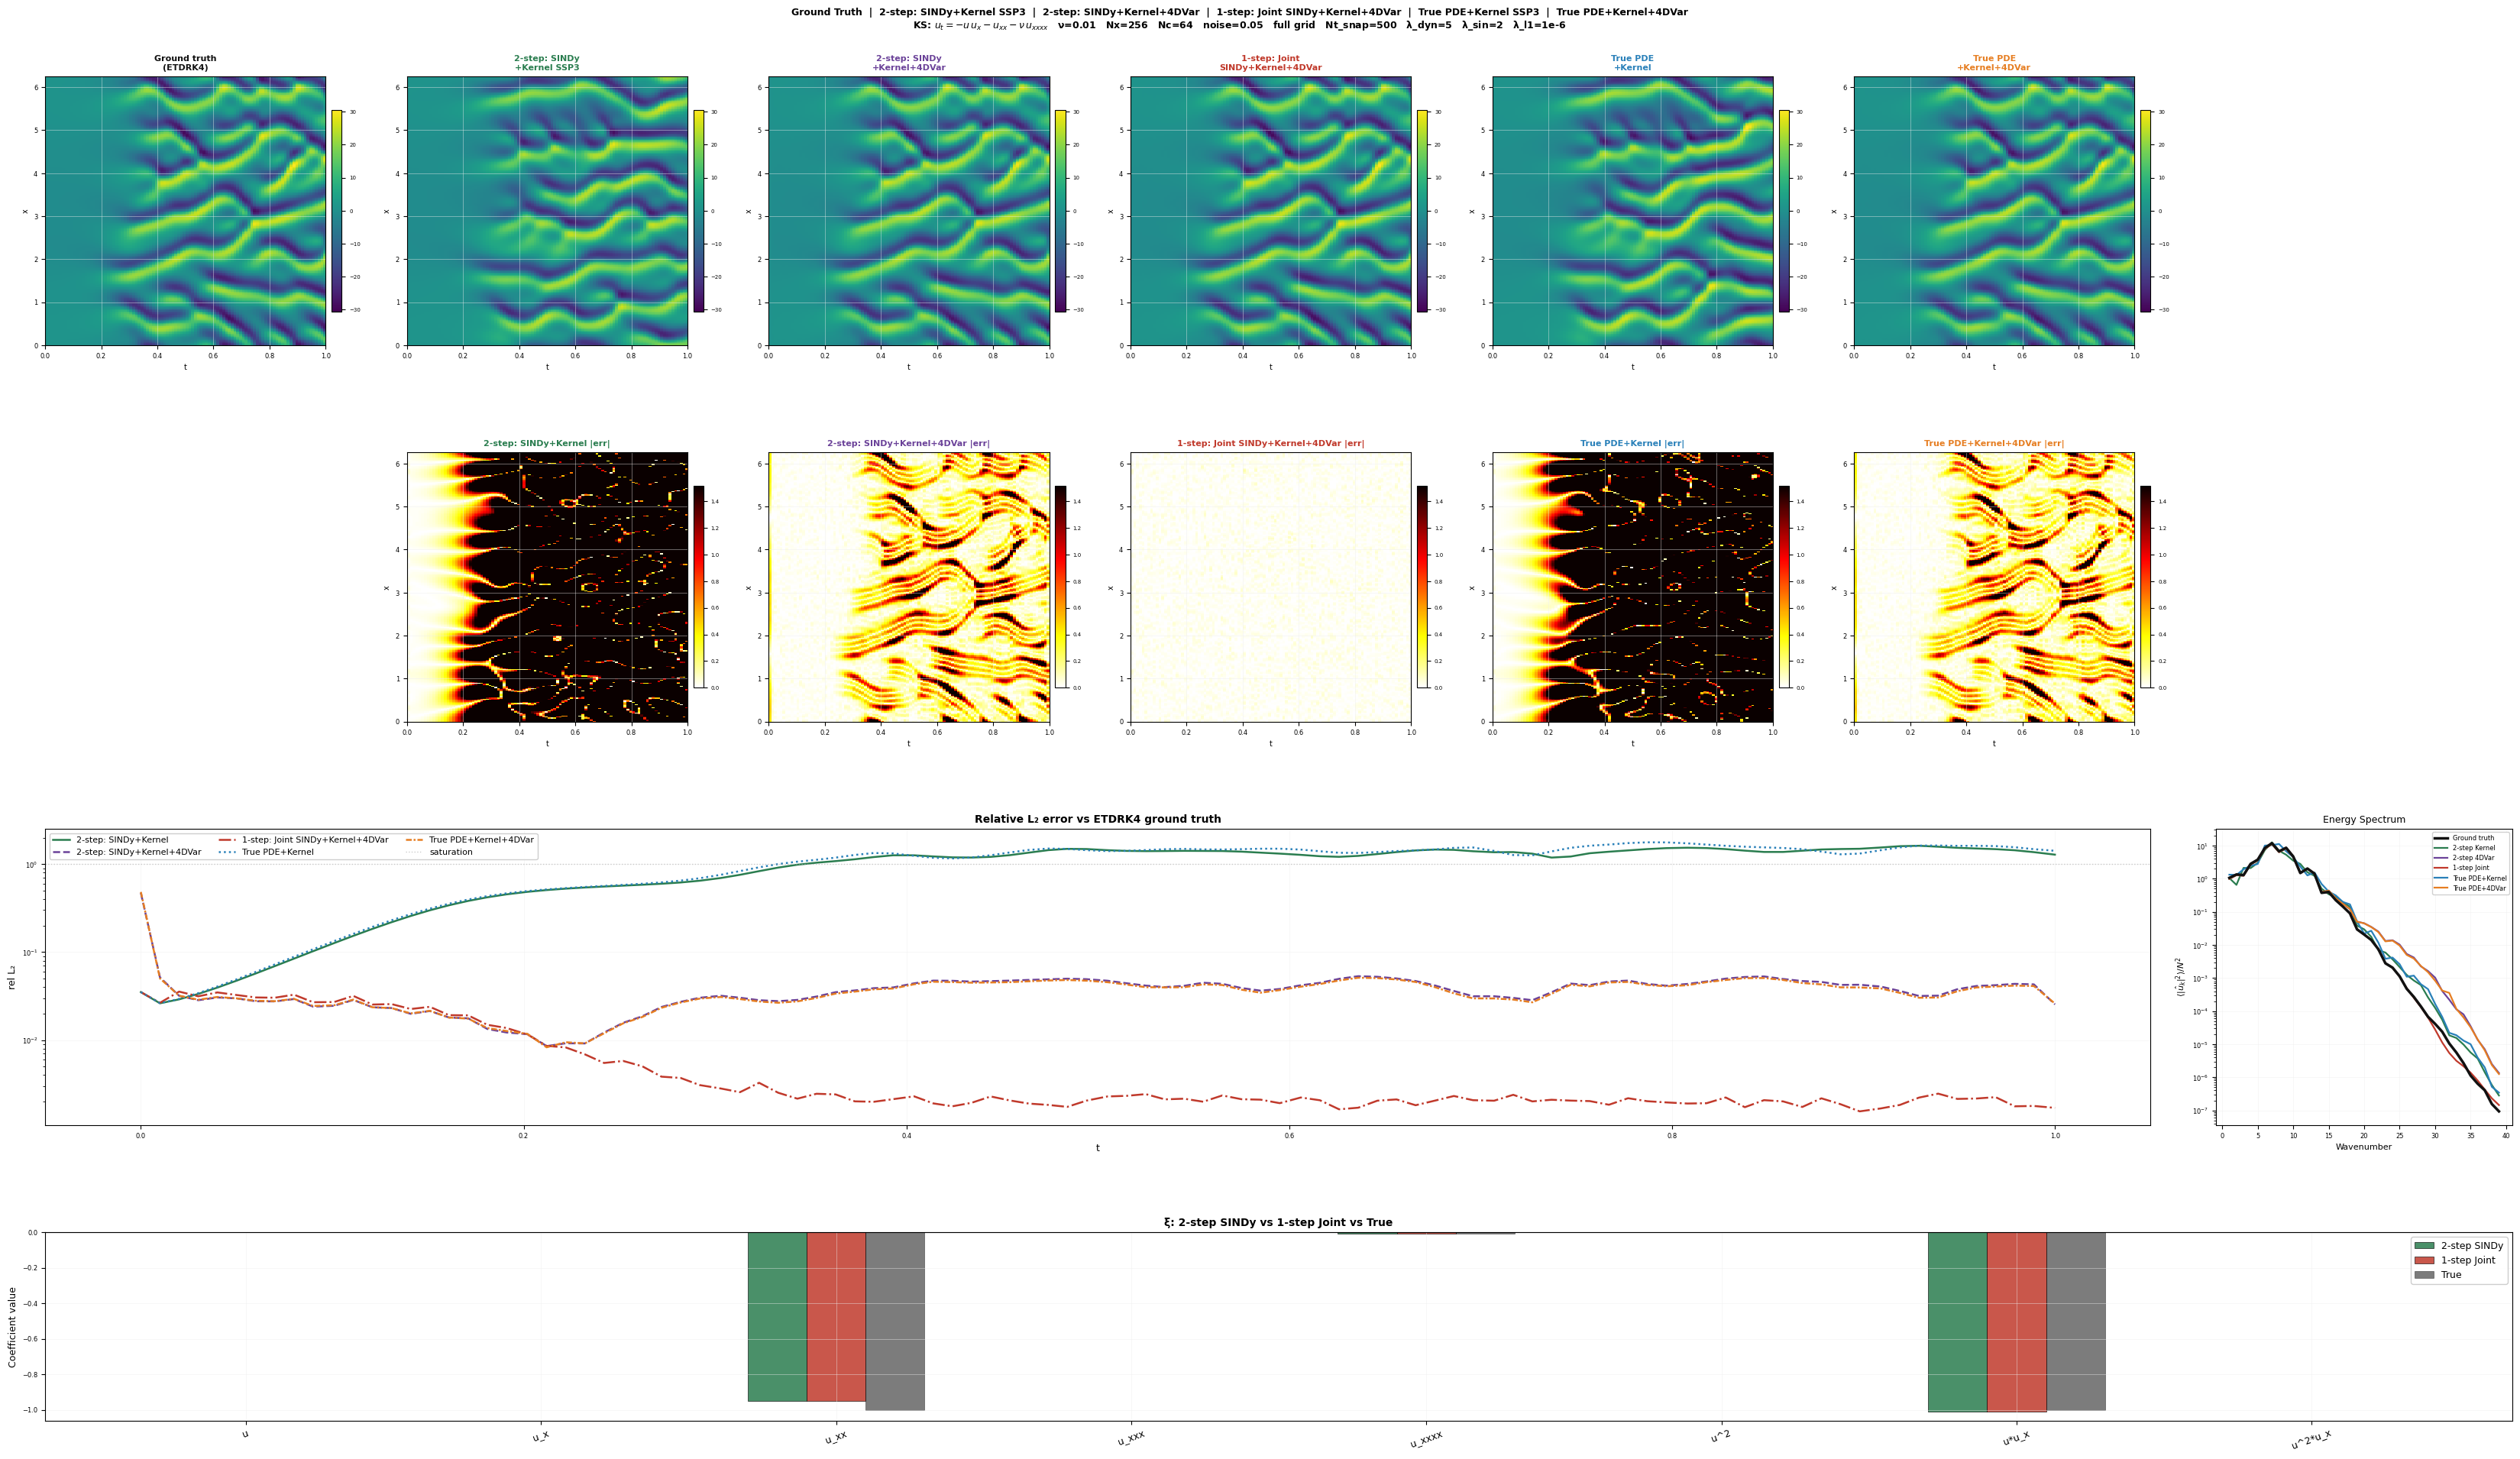

In [5]:
"""
combined_1step_favourable.py
============================
Parameters chosen to maximise the benefit of the 1-step joint method
over the 2-step SINDy cold-start:

  • n_obs_x = 256  (full spatial grid  → dynamics residual is a clean ξ signal)
  • Nt_snap = 500  (denser time grid   → more weak-form / dynamics constraints)
  • noise_std = 0.05  (higher noise    → SINDy alone is less reliable)
  • lam_dyn = 5.0  (strong dynamics weight → forces ξ consistency with trajectory)
  • lam_sin = 2.0  (moderately strong weak form)
  • lam_l1 = 1e-6  (weak LASSO → ξ can move freely during joint refinement)
  • lam_reg = 1e-8  (very weak L2 → same reason)
  • maxiter = 800   (more budget for the joint solve)

Run:
    python combined_1step_favourable.py
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
from scipy.linalg import cho_factor, cho_solve, expm as _expm
from scipy.ndimage import uniform_filter1d
from scipy.optimize import minimize as sp_minimize


# ══════════════════════════════════════════════════════════════════════════════
# Spectral helpers
# ══════════════════════════════════════════════════════════════════════════════

def wavenum(N, Ld):
    return 2.0 * np.pi * np.fft.rfftfreq(N, d=Ld / N)


def spec_derivs_rows(F, Ld):
    M, Nx = F.shape
    k     = wavenum(Nx, Ld)
    Fh    = np.fft.rfft(F, axis=1)
    Fx    = np.fft.irfft(1j * k[None, :] * Fh,       n=Nx, axis=1)
    Fxx   = np.fft.irfft(-(k[None, :]**2) * Fh,      n=Nx, axis=1)
    Fxxx  = np.fft.irfft(-1j*(k[None, :]**3) * Fh,   n=Nx, axis=1)
    Fxxxx = np.fft.irfft((k[None, :]**4) * Fh,       n=Nx, axis=1)
    return Fx, Fxx, Fxxx, Fxxxx


# ══════════════════════════════════════════════════════════════════════════════
# Periodic Gaussian kernel + analytic derivatives
# ══════════════════════════════════════════════════════════════════════════════

def ker(x, c, sig, Ld):
    d = np.pi * (x[:, None] - c[None, :]) / Ld
    return np.exp(-2.0 * np.sin(d)**2 / sig**2)


def ker_derivs(x, c, sig, Ld):
    p      = np.pi / Ld
    d      = p * (x[:, None] - c[None, :])
    Phi    = np.exp(-2.0 * np.sin(d)**2 / sig**2)
    f1     = -4.0 * p    * np.sin(d) * np.cos(d) / sig**2
    f1p    = -4.0 * p**2 * np.cos(2*d)            / sig**2
    f1pp   =  8.0 * p**3 * np.sin(2*d)            / sig**2
    f1ppp  = 16.0 * p**4 * np.cos(2*d)            / sig**2
    Phi_x    = Phi * f1
    Phi_xx   = Phi * (f1**2 + f1p)
    Phi_xxx  = Phi * (f1**3 + 3*f1*f1p + f1pp)
    Phi_xxxx = Phi * (f1**4 + 6*f1**2*f1p + 3*f1p**2 + 4*f1*f1pp + f1ppp)
    return Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx


# ══════════════════════════════════════════════════════════════════════════════
# ETDRK4 ground truth
# ══════════════════════════════════════════════════════════════════════════════

def ks_truth_etdrk4(u0, nu, x, dt, nt, Mq=64):
    nx   = x.size
    dx   = x[1] - x[0]
    k    = 2.0 * np.pi * np.fft.fftfreq(nx, d=dx)
    ik   = 1j * k
    Lhat = k**2 - nu * k**4
    E    = np.exp(dt * Lhat)
    E2   = np.exp(0.5 * dt * Lhat)
    roots = np.exp(1j * np.pi * (np.arange(1, Mq+1) - 0.5) / Mq)
    LR    = dt * Lhat[:, None] + roots[None, :]
    Q  = dt * np.real(np.mean((np.exp(LR/2.0) - 1.0) / LR, axis=1))
    f1 = dt * np.real(np.mean((-4.0 - LR + np.exp(LR)*(4.0 - 3.0*LR + LR**2)) / LR**3, axis=1))
    f2 = dt * np.real(np.mean((2.0 + LR + np.exp(LR)*(-2.0 + LR)) / LR**3, axis=1))
    f3 = dt * np.real(np.mean((-4.0 - 3.0*LR - LR**2 + np.exp(LR)*(4.0 - LR)) / LR**3, axis=1))

    def N_hat(vhat):
        u  = np.fft.ifft(vhat).real
        ux = np.fft.ifft(ik * vhat).real
        return np.fft.fft(-u * ux)

    U    = np.zeros((nt + 1, nx))
    U[0] = u0
    v    = np.fft.fft(u0)
    for n in range(nt):
        Nv = N_hat(v)
        a  = E2*v + Q*Nv;              Na = N_hat(a)
        b  = E2*v + Q*Na;              Nb = N_hat(b)
        c  = E2*a + Q*(2.0*Nb - Nv);  Nc = N_hat(c)
        v  = E*v + f1*Nv + 2.0*f2*(Na + Nb) + f3*Nc
        U[n+1] = np.fft.ifft(v).real
    return U


def make_ic(x):
    return np.cos(x) + 0.1*np.sin(2*x) - 0.1*np.cos(3*x) + 0.05*np.sin(5*x)


def generate_data(Nx=256, Nt_snap=300, t_max=1.0, nu=0.01,
                  x_min=0.0, x_max=2.0*np.pi,
                  noise_std=1e-2, dt_truth=1e-3, truth_refine=8, seed=0,
                  n_obs_x=None):
    x  = np.linspace(x_min, x_max, Nx, endpoint=False)
    u0 = make_ic(x)
    Ld = x_max - x_min
    nt      = int(round(t_max / dt_truth))
    dt_fine = dt_truth / truth_refine
    nt_fine = nt * truth_refine
    print(f"    ETDRK4: dt_fine={dt_fine:.2e}  nt_fine={nt_fine} ...")
    U_fine  = ks_truth_etdrk4(u0, nu, x, dt_fine, nt_fine)
    U_truth = U_fine[::truth_refine][:nt+1]
    t_full  = np.linspace(0.0, t_max, nt+1)
    idx     = np.linspace(0, nt, Nt_snap, dtype=int)
    t_snap  = t_full[idx]
    U_true  = U_truth[idx]
    rng     = np.random.default_rng(seed)
    U_obs   = U_true + noise_std * rng.standard_normal(U_true.shape)
    No      = Nx if n_obs_x is None else min(int(n_obs_x), Nx)
    obs_idx = np.arange(Nx) if No == Nx else np.sort(rng.choice(Nx, No, replace=False))
    x_obs   = x[obs_idx]
    U_obs_s = U_obs[:, obs_idx]
    print(f"    Spatial obs: No={No}/{Nx}  "
          f"({'full grid' if No == Nx else f'{No/Nx*100:.1f}% of grid'})")
    return (x, t_snap, U_true, U_obs, Ld, t_full, U_truth, x_obs, obs_idx, U_obs_s)


# ══════════════════════════════════════════════════════════════════════════════
# LOO-CV
# ══════════════════════════════════════════════════════════════════════════════

def loo_cv_error(U_obs, Phi, lam):
    Nx, Nc = Phi.shape
    cho    = cho_factor(Phi.T @ Phi + lam * np.eye(Nc))
    B      = cho_solve(cho, Phi.T)
    H_ii   = np.einsum("ij,ji->i", Phi, B)
    denom  = np.clip(1.0 - H_ii, 1e-6, None)
    total  = 0.0
    for u in U_obs:
        alpha = cho_solve(cho, Phi.T @ u)
        resid = (u - Phi @ alpha) / denom
        total += float(np.dot(resid, resid))
    return total / (len(U_obs) * Nx)


def find_sig_lam(U_obs_s, x_obs, Ld, Nc,
                 sig_fractions_of_Ld=(0.008, 0.016, 0.024, 0.032, 0.048, 0.064, 0.080),
                 lam_multipliers=(1e-6, 1e-4, 1e-2, 1e-1, 5e-1),
                 max_cond=1e10, verbose=False):
    centers = np.linspace(0.0, Ld, Nc, endpoint=False)
    best_err, best_sig, best_lam = np.inf, None, None
    for sf in sig_fractions_of_Ld:
        sig = Ld * sf
        Phi = ker(x_obs, centers, sig, Ld)
        G   = Phi.T @ Phi
        lam_scale = np.trace(G) / G.shape[0]
        for lm in lam_multipliers:
            lam  = lam_scale * lm
            cond = np.linalg.cond(G + lam * np.eye(Nc))
            if cond > max_cond:
                continue
            err = loo_cv_error(U_obs_s, Phi, lam)
            if err < best_err:
                best_err, best_sig, best_lam = err, sig, lam
    if best_sig is None:
        raise RuntimeError("LOO-CV: no valid (sig, lam) found.")
    print(f"  -> best: sig={best_sig:.4f}  lam={best_lam:.2e}  LOO={best_err:.4e}")
    return best_sig, best_lam


# ══════════════════════════════════════════════════════════════════════════════
# Weak SINDy helpers
# ══════════════════════════════════════════════════════════════════════════════

WEAK_LABELS = ["u", "u_x", "u_xx", "u_xxx", "u_xxxx",
               "u^2", "u*u_x", "u^2*u_x"]


def _make_spatial_test_fns(x, Ld, n_test_x, width_frac_x):
    Nx      = len(x)
    centers = np.linspace(0.0, Ld, n_test_x, endpoint=False)
    width   = width_frac_x * Ld
    Phi_x   = np.zeros((n_test_x, Nx))
    for i, c in enumerate(centers):
        d      = ((x - c + 0.5*Ld) % Ld) - 0.5*Ld
        s      = d / width
        inside = np.abs(s) < 1.0
        Phi_x[i, inside] = (1.0 - s[inside]**2)**3
    return Phi_x


def _make_temporal_test_fns(t_obs, n_test_t, width_frac_t):
    Nt    = len(t_obs)
    width = width_frac_t * (t_obs[-1] - t_obs[0])
    cents = np.linspace(t_obs[0] + width, t_obs[-1] - width, n_test_t)
    Psi   = np.zeros((n_test_t, Nt))
    dPsi  = np.zeros((n_test_t, Nt))
    for m, tc in enumerate(cents):
        s      = (t_obs - tc) / width
        inside = np.abs(s) < 1.0
        Psi [m, inside] =  (1.0 - s[inside]**2)**3
        dPsi[m, inside] = -6.0 * s[inside] * (1.0 - s[inside]**2)**2 / width
    return Psi, dPsi


def _build_theta_b(U, t_obs, Ld, n_test_x, n_test_t, width_frac_x, width_frac_t):
    Nt, Nx = U.shape
    dx     = Ld / Nx
    dt_vec = np.gradient(t_obs)
    x      = np.linspace(0.0, Ld, Nx, endpoint=False)
    Psi_x  = _make_spatial_test_fns(x, Ld, n_test_x, width_frac_x)
    Px1, Px2, Px3, Px4 = spec_derivs_rows(Psi_x, Ld)
    Psi_t, dPsi_t = _make_temporal_test_fns(t_obs, n_test_t, width_frac_t)
    P0w = dx*Psi_x; P1w = dx*Px1; P2w = dx*Px2; P3w = dx*Px3; P4w = dx*Px4
    Ptw  = Psi_t  * dt_vec[None, :]
    dPtw = dPsi_t * dt_vec[None, :]

    def weak(Q, Fw):
        return (Ptw @ Q @ Fw.T).ravel()

    U2 = U**2; U3 = U**3
    b     = -(dPtw @ U @ P0w.T).ravel()
    Theta = np.column_stack([
        weak(U,   P0w),  -weak(U,   P1w),  +weak(U,   P2w),
       -weak(U,   P3w),  +weak(U,   P4w),
        weak(U2,  P0w),  -0.5*(weak(U2, P1w)),  -(1.0/3.0)*(weak(U3, P1w)),
    ])
    return Theta, b, Ptw, dPtw, P0w, P1w, P2w, P3w, P4w


def stls_relative(Theta, b, rel_thr=0.05, ridge=1e-8, max_iter=30):
    col_norms = np.linalg.norm(Theta, axis=0)
    col_norms[col_norms == 0.0] = 1.0
    Tn  = Theta / col_norms
    xi  = np.linalg.solve(Tn.T @ Tn + ridge * np.eye(Tn.shape[1]), Tn.T @ b)
    prev = None
    for _ in range(max_iter):
        mx = np.max(np.abs(xi))
        if mx < 1e-15: xi[:] = 0.0; break
        active = np.abs(xi) >= rel_thr * mx
        if not np.any(active): xi[:] = 0.0; break
        if prev is not None and np.array_equal(active, prev): break
        xi_new = np.zeros_like(xi)
        Ta = Tn[:, active]
        xi_new[active] = np.linalg.solve(Ta.T@Ta + ridge*np.eye(active.sum()), Ta.T@b)
        xi = xi_new; prev = active.copy()
    active = np.abs(xi) > 0
    if np.any(active):
        Ta = Tn[:, active]
        xi_db = np.zeros_like(xi)
        xi_db[active] = np.linalg.lstsq(Ta, b, rcond=None)[0]
        xi = xi_db
    return xi / col_norms


def run_weak_sindy(U_den, t_obs, Ld, n_test_x, n_test_t,
                   width_frac_x, width_frac_t, rel_thr, ridge):
    Theta, b, *_ = _build_theta_b(U_den, t_obs, Ld, n_test_x, n_test_t,
                                   width_frac_x, width_frac_t)
    xi        = stls_relative(Theta, b, rel_thr=rel_thr, ridge=ridge)
    resid_rel = np.linalg.norm(Theta @ xi - b) / (np.linalg.norm(b) + 1e-14)
    return xi, {"resid_rel": resid_rel, "n_active": int(np.sum(np.abs(xi) > 1e-10))}


# ══════════════════════════════════════════════════════════════════════════════
# 2-step method — Step 1: disciplined SINDy search
# ══════════════════════════════════════════════════════════════════════════════

def linear_stability_penalty(xi, Ld, Nx):
    k     = wavenum(Nx, Ld)
    lam_k = (xi[0] + xi[1]*(1j*k) + xi[2]*(-(k**2))
             + xi[3]*(-(1j)*(k**3)) + xi[4]*(k**4))
    pos   = np.maximum(np.real(lam_k), 0.0)
    return float(np.mean(np.minimum(pos, 25.0)**2))


_ssp3_g     = (3.0 + np.sqrt(3.0)) / 6.0
_ssp3_A_imp = np.array([[_ssp3_g,0,0],[1-2*_ssp3_g,_ssp3_g,0],
                         [0.5,0.5-_ssp3_g,_ssp3_g]])
_ssp3_A_exp = np.array([[0,0,0],[1,0,0],[0.25,0.25,0]], dtype=float)
_ssp3_b     = np.array([1/6, 1/6, 2/3], dtype=float)


def _linear_symbol(xi, k):
    return (xi[0] + xi[1]*(1j*k) + xi[2]*(-(k**2))
            + xi[3]*(-(1j*k**3)) + xi[4]*(k**4))


def _N_phys(Ui, Ui_hat, k, xi, Nx):
    Ux = np.fft.irfft(1j * k * Ui_hat, n=Nx)
    return xi[5]*Ui**2 + xi[6]*Ui*Ux + xi[7]*Ui**2*Ux


def _ssp3_kernel_step(alpha, K0, cho, xi, dt, Ld):
    Nx  = K0.shape[0]
    k   = wavenum(Nx, Ld)
    lam = _linear_symbol(xi, k)
    den = 1.0 - dt * _ssp3_g * lam
    u_n = K0 @ alpha
    Vp, Nh_l, Lh_l = [], [], []
    for i in range(3):
        r = u_n.copy()
        for j in range(i):
            if _ssp3_A_exp[i,j]: r += dt*_ssp3_A_exp[i,j]*Nh_l[j]
            if _ssp3_A_imp[i,j]: r += dt*_ssp3_A_imp[i,j]*Lh_l[j]
        rh  = np.fft.rfft(r)
        Vih = rh / den
        Vi  = np.fft.irfft(Vih, n=Nx)
        Vp.append(Vi)
        Nh_l.append(_N_phys(Vi, Vih, k, xi, Nx))
        Lh_l.append(np.fft.irfft(lam * Vih, n=Nx))
    u_new = u_n.copy()
    for i in range(3):
        u_new += dt*(_ssp3_b[i]*Nh_l[i] + _ssp3_b[i]*Lh_l[i])
    if not np.all(np.isfinite(u_new)):
        return alpha, False
    return cho_solve(cho, K0.T @ u_new), True


def rollout_score(x, t_obs, U_true, U_obs, Ld, xi, sig_cv, lam_cv,
                  Nc=64, horizon_frac=0.15):
    c     = np.linspace(0.0, Ld, Nc, endpoint=False)
    K0    = ker(x, c, sig_cv, Ld)
    cho   = cho_factor(K0.T @ K0 + lam_cv * np.eye(Nc))
    alpha = cho_solve(cho, K0.T @ U_obs[0])
    amp0  = np.max(np.abs(K0 @ alpha)) + 1e-14
    dt_r  = np.median(np.diff(t_obs))
    n_steps = max(1, int(round(horizon_frac * (t_obs[-1] - t_obs[0]) / dt_r)))
    U_pred  = [K0 @ alpha]
    for _ in range(n_steps):
        try:
            alpha, ok = _ssp3_kernel_step(alpha, K0, cho, xi, dt_r, Ld)
            u = K0 @ alpha
        except Exception:
            return np.inf, False
        if not ok or not np.all(np.isfinite(u)) or np.max(np.abs(u)) > 8.0*amp0:
            return np.inf, False
        U_pred.append(u)
    U_pred = np.array(U_pred)
    t_pred = t_obs[0] + dt_r * np.arange(len(U_pred))
    idx    = [np.argmin(np.abs(t_obs - tt)) for tt in t_pred]
    err    = (np.linalg.norm(U_pred - U_true[idx]) /
              (np.linalg.norm(U_true[idx]) + 1e-14))
    return err, True


def total_score(resid_rel, n_active, stab_pen, pred_err, stable):
    s  = 1.0*resid_rel + 0.08*n_active + 0.2*stab_pen
    s += 2.0*pred_err if stable else 1e6
    return s


def _denoise(U_obs, k_cut, t_smooth):
    Nt, Nx = U_obs.shape
    Uh = np.fft.rfft(U_obs, axis=1)
    Uh[:, min(k_cut, Uh.shape[1]):] = 0.0
    U  = np.fft.irfft(Uh, n=Nx, axis=1)
    if t_smooth > 1:
        U = uniform_filter1d(U, size=t_smooth, axis=0, mode="nearest")
    return U


def disciplined_sindy_search(U_obs, t_obs, x, Ld, U_true, sig_cv, lam_cv,
                              Nc=64, verbose=True):
    """2-step method Step 1: Weak SINDy to recover ξ."""
    Uh_ref = np.fft.rfft(U_obs, axis=1).copy(); Uh_ref[:, 40:] = 0.0
    U_ref  = uniform_filter1d(np.fft.irfft(Uh_ref, n=U_obs.shape[1], axis=1),
                               size=3, axis=0, mode="nearest")
    best1  = (np.inf, 48, 3)
    for kc in [32, 48, 64]:
        for ts in [1, 3, 5]:
            U_den = _denoise(U_obs, kc, ts)
            sc    = float(np.linalg.norm(U_den - U_ref) /
                          (np.linalg.norm(U_ref) + 1e-14))
            if sc < best1[0]: best1 = (sc, kc, ts)
    k_cut, t_smooth = best1[1], best1[2]

    U_den = _denoise(U_obs, k_cut, t_smooth)
    best2 = (np.inf, 16, 24, 0.10, 0.08)
    for ntx in [16, 32]:
        for ntt in [24, 48]:
            for wfx in [0.08, 0.14]:
                for wft in [0.06, 0.10]:
                    T, b, *_ = _build_theta_b(U_den, t_obs, Ld, ntx, ntt, wfx, wft)
                    xi_ls = np.linalg.lstsq(T, b, rcond=None)[0]
                    res   = np.linalg.norm(T @ xi_ls - b) / (np.linalg.norm(b) + 1e-14)
                    if res < best2[0]: best2 = (res, ntx, ntt, wfx, wft)
    _, ntx, ntt, wfx, wft = best2

    best_sc, best_xi = np.inf, None
    for rt in [0.03, 0.05, 0.10]:
        for rg in [1e-10, 1e-8, 1e-6]:
            xi, diag = run_weak_sindy(U_den, t_obs, Ld, ntx, ntt, wfx, wft, rt, rg)
            stab     = linear_stability_penalty(xi, Ld, len(x))
            pred_err, stable = rollout_score(x, t_obs, U_true, U_obs, Ld,
                                              xi, sig_cv, lam_cv, Nc=Nc)
            sc = total_score(diag["resid_rel"], diag["n_active"], stab, pred_err, stable)
            if sc < best_sc: best_sc, best_xi = sc, xi.copy()

    if verbose:
        print(f"\n  ξ (2-step SINDy):")
        for nm, v in zip(WEAK_LABELS, best_xi):
            print(f"    {nm:12s}: {v:+.6f}" + ("  ***" if abs(v) > 1e-10 else ""))
    return best_xi, (ntx, ntt, wfx, wft)


# ══════════════════════════════════════════════════════════════════════════════
# 2-step method — Step 2: Kernel SSP3 rollout + 4DVar
# ══════════════════════════════════════════════════════════════════════════════

def _N_alpha(alpha, Phi, Phi_x, xi):
    u  = Phi   @ alpha
    ux = Phi_x @ alpha
    return Phi.T @ (xi[5]*u**2 + xi[6]*u*ux + xi[7]*u**2*ux)


def rollout_kernel(u0_obs, x_obs, x, xi, Ld, dt, Nt, Nc, sig, lam_ker,
                   max_amp=50.0):
    ns = len(_ssp3_b)
    c  = np.linspace(0.0, Ld, Nc, endpoint=False)
    Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx = ker_derivs(x, c, sig, Ld)
    M   = Phi.T @ Phi
    L_a = (xi[0]*(Phi.T@Phi)    + xi[1]*(Phi.T@Phi_x)
         + xi[2]*(Phi.T@Phi_xx) + xi[3]*(Phi.T@Phi_xxx)
         + xi[4]*(Phi.T@Phi_xxxx))
    M_final  = cho_factor(M + lam_ker * np.eye(Nc))
    diag_gs  = sorted(set(float(_ssp3_A_imp[i, i]) for i in range(ns)))
    M_stages = {g: cho_factor(M - dt*g*L_a + lam_ker*np.eye(Nc)) for g in diag_gs}
    Phi_obs  = ker(x_obs, c, sig, Ld)
    M_obs    = cho_factor(Phi_obs.T @ Phi_obs + lam_ker * np.eye(Nc))
    alpha    = cho_solve(M_obs, Phi_obs.T @ u0_obs)
    U        = [Phi @ alpha]
    blowup   = None
    t0       = time.perf_counter()
    for step in range(Nt):
        Ma_n   = M @ alpha
        sN, sL = [], []
        for i in range(ns):
            rhs = Ma_n.copy()
            for j in range(i):
                if _ssp3_A_exp[i,j]: rhs += dt * _ssp3_A_exp[i,j] * sN[j]
                if _ssp3_A_imp[i,j]: rhs += dt * _ssp3_A_imp[i,j] * sL[j]
            a_i = cho_solve(M_stages[float(_ssp3_A_imp[i,i])], rhs)
            sN.append(_N_alpha(a_i, Phi, Phi_x, xi))
            sL.append(L_a @ a_i)
        rhs_f = Ma_n.copy()
        for i in range(ns): rhs_f += dt * _ssp3_b[i] * (sN[i] + sL[i])
        alpha_new = cho_solve(M_final, rhs_f)
        u_new     = Phi @ alpha_new
        if not np.all(np.isfinite(u_new)) or np.max(np.abs(u_new)) > max_amp:
            blowup = step; break
        alpha = alpha_new; U.append(u_new)
    wt = time.perf_counter() - t0
    if blowup is not None:
        print(f"  [Kernel SSP3] blowup at step {blowup}  (t={blowup*dt:.4f})")
    return np.array(U), wt, blowup


def _build_4dvar_operators(x, x_obs, xi, Ld, Nc, sig, lam_ker, dt):
    c = np.linspace(0.0, Ld, Nc, endpoint=False)
    Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx = ker_derivs(x, c, sig, Ld)
    M   = Phi.T @ Phi
    L_a = (xi[0]*(Phi.T@Phi)    + xi[1]*(Phi.T@Phi_x)
         + xi[2]*(Phi.T@Phi_xx) + xi[3]*(Phi.T@Phi_xxx)
         + xi[4]*(Phi.T@Phi_xxxx))
    M_final  = cho_factor(M + lam_ker * np.eye(Nc))
    diag_gs  = sorted(set(float(_ssp3_A_imp[i, i]) for i in range(3)))
    M_stages = {g: cho_factor(M - dt*g*L_a + lam_ker*np.eye(Nc)) for g in diag_gs}
    Phi_obs  = ker(x_obs, c, sig, Ld)
    return dict(Phi=Phi, Phi_x=Phi_x, M=M, L_a=L_a,
                M_final=M_final, M_stages=M_stages,
                Phi_obs=Phi_obs, c=c, dt=dt, Nc=Nc)


def _G_and_jac(alpha, ops, xi):
    Nc = ops['Nc']; dt = ops['dt']; M = ops['M']; L_a = ops['L_a']
    M_final = ops['M_final']; M_stages = ops['M_stages']
    Phi = ops['Phi']; Phi_x = ops['Phi_x']; ns = 3
    Ma_n = M @ alpha
    stage_a, stage_N, stage_L = [], [], []
    for i in range(ns):
        rhs = Ma_n.copy()
        for j in range(i):
            if _ssp3_A_exp[i,j]: rhs += dt * _ssp3_A_exp[i,j] * stage_N[j]
            if _ssp3_A_imp[i,j]: rhs += dt * _ssp3_A_imp[i,j] * stage_L[j]
        a_i = cho_solve(M_stages[float(_ssp3_A_imp[i,i])], rhs)
        stage_a.append(a_i)
        stage_N.append(_N_alpha(a_i, Phi, Phi_x, xi))
        stage_L.append(L_a @ a_i)
    rhs_f = Ma_n.copy()
    for i in range(ns): rhs_f += dt * _ssp3_b[i] * (stage_N[i] + stage_L[i])
    alpha_new = cho_solve(M_final, rhs_f)

    def jac_T_vec(w):
        bar_rhs_f = cho_solve(M_final, w)
        bar_N  = [dt * _ssp3_b[i] * bar_rhs_f.copy() for i in range(ns)]
        bar_L  = [dt * _ssp3_b[i] * bar_rhs_f.copy() for i in range(ns)]
        bar_Ma = bar_rhs_f.copy()
        for i in reversed(range(ns)):
            bar_ai = L_a.T @ bar_L[i]
            a_i = stage_a[i]; u = Phi @ a_i; ux = Phi_x @ a_i
            bnp = Phi @ bar_N[i]
            bar_ai += Phi.T   @ (bnp * (2*xi[5]*u + xi[6]*ux + 2*xi[7]*u*ux))
            bar_ai += Phi_x.T @ (bnp * (xi[6]*u  + xi[7]*u**2))
            bar_rhs_i = cho_solve(M_stages[float(_ssp3_A_imp[i,i])], bar_ai)
            bar_Ma += bar_rhs_i
            for j in range(i):
                if _ssp3_A_exp[i,j]: bar_N[j] += dt * _ssp3_A_exp[i,j] * bar_rhs_i
                if _ssp3_A_imp[i,j]: bar_L[j] += dt * _ssp3_A_imp[i,j] * bar_rhs_i
        return M @ bar_Ma
    return alpha_new, jac_T_vec


def fdvar_cost_and_grad(z, Y_obs, ops, xi, lam0, lam_mis, lam_dyn, N_steps, Nc):
    Phi_obs = ops['Phi_obs']; M = ops['M']
    alphas  = [z[n*Nc:(n+1)*Nc] for n in range(N_steps+1)]
    grad    = [np.zeros(Nc) for _ in range(N_steps+1)]
    J       = 0.0
    Ma0     = M @ alphas[0]
    J      += lam0 * float(alphas[0] @ Ma0)
    grad[0] += 2.0 * lam0 * Ma0
    for n in range(N_steps+1):
        res = Phi_obs @ alphas[n] - Y_obs[n]
        J      += lam_mis * float(res @ res)
        grad[n] += 2.0 * lam_mis * (Phi_obs.T @ res)
    for n in range(N_steps):
        G_n, jacT = _G_and_jac(alphas[n], ops, xi)
        delta   = alphas[n+1] - G_n
        M_delta = M @ delta
        J      += lam_dyn * float(delta @ M_delta)
        grad[n+1] += 2.0 * lam_dyn * M_delta
        grad[n]   -= 2.0 * lam_dyn * jacT(M_delta)
    return J, np.concatenate(grad)


def run_4dvar(Y_obs_s, x_obs, x, xi, Ld, Nc, sig, lam_ker, dt,
              lam0=1.0, lam_mis=1.0, lam_dyn=0.1, maxiter=200, verbose=True):
    N_steps = len(Y_obs_s) - 1
    ops     = _build_4dvar_operators(x, x_obs, xi, Ld, Nc, sig, lam_ker, dt)
    Phi     = ops['Phi']; Phi_obs = ops['Phi_obs']
    M_obs   = cho_factor(Phi_obs.T @ Phi_obs + lam_ker * np.eye(Nc))
    alpha0  = cho_solve(M_obs, Phi_obs.T @ Y_obs_s[0])
    alphas_warm = [alpha0]
    for _ in range(N_steps):
        a_new, _ = _G_and_jac(alphas_warm[-1], ops, xi)
        alphas_warm.append(a_new)
    z0 = np.concatenate(alphas_warm)
    iters = [0]
    def callback(z):
        iters[0] += 1
        if verbose and iters[0] % 20 == 0:
            J, _ = fdvar_cost_and_grad(z, Y_obs_s, ops, xi, lam0, lam_mis, lam_dyn, N_steps, Nc)
            print(f"    iter {iters[0]:4d}  J={J:.4e}")
    t0  = time.perf_counter()
    res = sp_minimize(
        lambda z: fdvar_cost_and_grad(z, Y_obs_s, ops, xi, lam0, lam_mis, lam_dyn, N_steps, Nc),
        z0, method="L-BFGS-B", jac=True,
        options={"maxiter": maxiter, "ftol": 1e-12, "gtol": 1e-8, "maxcor": 20},
        callback=callback)
    wt = time.perf_counter() - t0
    z_opt      = res.x
    alphas_opt = np.array([z_opt[n*Nc:(n+1)*Nc] for n in range(N_steps+1)])
    U_4dvar    = alphas_opt @ Phi.T
    return alphas_opt, U_4dvar, {"res": res, "wt": wt}


# ══════════════════════════════════════════════════════════════════════════════
# 1-step method — Kernel ETDRK4 dynamics
# ══════════════════════════════════════════════════════════════════════════════

_MAX_REAL_EIGVAL = 10.0


def _build_La(xi, Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx):
    return (xi[0]*(Phi.T@Phi)    + xi[1]*(Phi.T@Phi_x)
          + xi[2]*(Phi.T@Phi_xx) + xi[3]*(Phi.T@Phi_xxx)
          + xi[4]*(Phi.T@Phi_xxxx))


def _ker_etdrk4_coeffs(La, M_inv, dt, Mq=16):
    Nc     = La.shape[0]
    La_eff = M_inv @ La
    eigvals = np.linalg.eigvals(La_eff)
    max_re  = float(np.max(np.real(eigvals)))
    if max_re > _MAX_REAL_EIGVAL:
        La_eff = La_eff - (max_re - _MAX_REAL_EIGVAL) * np.eye(Nc)
    Z  = dt * La_eff
    E  = _expm(Z); E2 = _expm(0.5 * Z)
    roots = np.exp(1j * np.pi * (np.arange(1, Mq+1) - 0.5) / Mq)
    Q_acc = np.zeros((Nc,Nc)); F1_acc = np.zeros((Nc,Nc))
    F2_acc= np.zeros((Nc,Nc)); F3_acc = np.zeros((Nc,Nc))
    I = np.eye(Nc)
    for r in roots:
        Zr  = Z + r*I; eZr = _expm(Zr); eZ2 = _expm(0.5*Zr)
        iZr = np.linalg.solve(Zr, I)
        iZr3= np.linalg.solve(Zr@Zr@Zr, I)
        Q_acc  += np.real((eZ2 - I) @ iZr)
        F1_acc += np.real((-4*I - Zr + eZr@(4*I - 3*Zr + Zr@Zr)) @ iZr3)
        F2_acc += np.real((2*I + Zr + eZr@(-2*I + Zr)) @ iZr3)
        F3_acc += np.real((-4*I - 3*Zr - Zr@Zr + eZr@(4*I - Zr)) @ iZr3)
    Q  = dt * Q_acc/Mq;  F1 = dt * F1_acc/Mq
    F2 = dt * F2_acc/Mq; F3 = dt * F3_acc/Mq
    return E, E2, Q, F1, F2, F3, La_eff


def _N_ker(alpha, Phi, Phi_x, xi):
    u  = Phi   @ alpha; ux = Phi_x @ alpha
    return Phi.T @ (xi[5]*u**2 + xi[6]*u*ux + xi[7]*u**2*ux)


def _ker_etdrk4_step(alpha, M_inv, E, E2, Q, F1, F2, F3, Phi, Phi_x, xi):
    Nv = _N_ker(alpha, Phi, Phi_x, xi)
    a  = E2@alpha + Q@Nv;            Na = _N_ker(a, Phi, Phi_x, xi)
    b  = E2@alpha + Q@Na;            Nb = _N_ker(b, Phi, Phi_x, xi)
    c  = E2@a     + Q@(2*Nb - Nv);  Nc = _N_ker(c, Phi, Phi_x, xi)
    return E@alpha + F1@Nv + 2*(F2@(Na+Nb)) + F3@Nc, (alpha, a, b, c, Nv, Na, Nb, Nc)


def _ker_etdrk4_adjoint(bar_anew, cache, E, E2, Q, F1, F2, F3, M_inv, Phi, Phi_x, xi):
    alpha, a, b, c, Nv, Na, Nb, Nc_a = cache
    bar_xi = np.zeros(8)
    bar_Nv  = F1.T @ bar_anew; bar_Na = 2.0*F2.T @ bar_anew
    bar_Nb  = 2.0*F2.T @ bar_anew; bar_Nc = F3.T @ bar_anew
    bar_alpha = E.T @ bar_anew
    bar_a   = E2.T @ bar_Nc
    tmp     = Q.T @ bar_Nc; bar_Nb += 2.0*tmp; bar_Nv -= tmp
    bar_Na += Q.T @ bar_Nb; bar_alpha += E2.T @ bar_Nb
    bar_Nv += Q.T @ bar_Na; bar_alpha += E2.T @ bar_Na
    bar_alpha += E2.T @ bar_a; bar_Nv += Q.T @ bar_a

    def back_N(bNv, v):
        u = Phi@v; ux = Phi_x@v; bp = Phi@bNv
        bar_xi[5] += float(bp @ u**2)
        bar_xi[6] += float(bp @ (u*ux))
        bar_xi[7] += float(bp @ (u**2*ux))
        dn_du  = 2*xi[5]*u + xi[6]*ux + 2*xi[7]*u*ux
        dn_dux = xi[6]*u   + xi[7]*u**2
        return Phi.T@(bp*dn_du) + Phi_x.T@(bp*dn_dux)

    bar_alpha += back_N(bar_Nv, alpha)
    bar_alpha += back_N(bar_Na, a)
    bar_alpha += back_N(bar_Nb, b)
    bar_alpha += back_N(bar_Nc, c)
    return bar_alpha, bar_xi


def _sindy_cost_grad(alphas_arr, xi, Phi, Phi_x, t_obs, Ld,
                     n_test_x, n_test_t, wfx, wft, lam_sin):
    Nt, Nc = alphas_arr.shape
    U   = alphas_arr @ Phi.T; Ux = alphas_arr @ Phi_x.T
    T, b_vec, Ptw, dPtw, P0w, P1w, P2w, P3w, P4w = _build_theta_b(
        U, t_obs, Ld, n_test_x, n_test_t, wfx, wft)
    r       = T @ xi - b_vec
    J_sin   = lam_sin * float(r @ r)
    grad_xi = 2.0 * lam_sin * (T.T @ r)
    R    = r.reshape(len(Ptw), len(P0w))
    w_t  = Ptw.T @ R; dw_t = dPtw.T @ R
    grad_U  = np.zeros_like(U); grad_Ux = np.zeros_like(Ux)
    for n in range(Nt):
        wn = w_t[n]; dwn = dw_t[n]; un = U[n]; uxn = Ux[n]
        lin_P = xi[0]*P0w - xi[1]*P1w + xi[2]*P2w - xi[3]*P3w + xi[4]*P4w
        grad_U[n] += 2.0*lam_sin * (wn @ lin_P)
        grad_U[n] += 2.0*lam_sin * (dwn @ P0w)
        grad_U[n] += 2.0*lam_sin * xi[5] * (wn @ (2.0*un[:,None]*P0w.T).T)
        grad_U[n]  += 2.0*lam_sin * (-0.5)*xi[6] * (wn @ (2.0*un[:,None]*P1w.T).T)
        grad_Ux[n] += 2.0*lam_sin * (-0.5)*xi[6] * (wn @ (un[:,None]*P1w.T).T)
        grad_U[n]  += 2.0*lam_sin * (-1.0/3.0)*xi[7] * (wn @ (3.0*(un**2)[:,None]*P1w.T).T)
        grad_Ux[n] += 2.0*lam_sin * (-1.0/3.0)*xi[7] * (wn @ ((un**2)[:,None]*P1w.T).T)
    grad_alphas = grad_U @ Phi + grad_Ux @ Phi_x
    return J_sin, grad_xi, grad_alphas


def joint_cost_grad(z, Y_obs_s, Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx,
                    Phi_obs, M, M_inv, t_obs, Ld, Nc, dt,
                    lam0, lam_mis, lam_dyn, lam_sin, lam_reg, lam_l1,
                    n_test_x, n_test_t, wfx, wft):
    n_xi    = 8; N_steps = len(Y_obs_s) - 1
    xi_p = z[:n_xi]; xi_m = z[n_xi:2*n_xi]; xi = xi_p - xi_m
    alphas = [z[2*n_xi + n*Nc : 2*n_xi + (n+1)*Nc] for n in range(N_steps+1)]
    J = 0.0; g_xip = np.zeros(n_xi); g_xim = np.zeros(n_xi)
    g_a = [np.zeros(Nc) for _ in range(N_steps+1)]
    Ma0 = M @ alphas[0]; J += lam0 * float(alphas[0] @ Ma0); g_a[0] += 2.0*lam0*Ma0
    for n in range(N_steps+1):
        res = Phi_obs @ alphas[n] - Y_obs_s[n]
        J += lam_mis * float(res @ res); g_a[n] += 2.0*lam_mis*(Phi_obs.T @ res)
    if lam_dyn > 0:
        La = _build_La(xi, Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx)
        E, E2, Q, F1, F2, F3, _ = _ker_etdrk4_coeffs(La, M_inv, dt)
        for n in range(N_steps):
            ap, cache = _ker_etdrk4_step(alphas[n], M_inv, E, E2, Q, F1, F2, F3,
                                          Phi, Phi_x, xi)
            delta = alphas[n+1] - ap; Md = M @ delta
            J += lam_dyn * float(delta @ Md); g_a[n+1] += 2.0*lam_dyn*Md
            bar_ap = -2.0*lam_dyn*Md
            bar_an, bar_xi_n = _ker_etdrk4_adjoint(bar_ap, cache, E, E2, Q, F1, F2, F3,
                                                    M_inv, Phi, Phi_x, xi)
            dLa_list = [Phi.T@Phi, Phi.T@Phi_x, Phi.T@Phi_xx, Phi.T@Phi_xxx, Phi.T@Phi_xxxx]
            for j in range(5):
                bar_xi_n[j] += dt * float(bar_ap @ (M_inv @ (dLa_list[j] @ (E @ alphas[n]))))
            g_a[n] += bar_an; g_xip += bar_xi_n; g_xim -= bar_xi_n
    alphas_arr = np.array(alphas)
    J_sin, g_xi_sin, g_a_sin = _sindy_cost_grad(
        alphas_arr, xi, Phi, Phi_x, t_obs, Ld, n_test_x, n_test_t, wfx, wft, lam_sin)
    J += J_sin; g_xip += g_xi_sin; g_xim -= g_xi_sin
    for n in range(N_steps+1): g_a[n] += g_a_sin[n]
    J += lam_reg*float(xi@xi); g_xip += 2.0*lam_reg*xi; g_xim -= 2.0*lam_reg*xi
    J += lam_l1*(np.sum(xi_p)+np.sum(xi_m))
    g_xip += lam_l1*np.ones(n_xi); g_xim += lam_l1*np.ones(n_xi)
    grad_z = np.concatenate([g_xip, g_xim] + g_a)
    if not np.isfinite(J) or not np.all(np.isfinite(grad_z)):
        J = 1e30; grad_z = np.zeros_like(grad_z)
    return J, grad_z


def run_joint(Y_obs_s, x_obs, x, t_obs, Ld, Nc, sig, lam_ker, xi_init,
              lam0=1.0, lam_mis=1.0, lam_dyn=1.0, lam_sin=1.0,
              lam_reg=1e-6, lam_l1=1e-5,
              n_test_x=16, n_test_t=24, width_frac_x=0.10, width_frac_t=0.08,
              maxiter=500, verbose=True):
    dt = float(np.median(np.diff(t_obs))); N_steps = len(Y_obs_s)-1
    n_xi = len(xi_init); Nx = len(x)
    c = np.linspace(0.0, Ld, Nc, endpoint=False)
    Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx = ker_derivs(x, c, sig, Ld)
    M = Phi.T @ Phi; Phi_obs = ker(x_obs, c, sig, Ld)
    lam_floor = max(float(lam_ker), 1e-4)
    M_inv     = np.linalg.inv(M + lam_floor*np.eye(Nc))
    M_obs     = cho_factor(Phi_obs.T @ Phi_obs + lam_floor*np.eye(Nc))
    alphas_warm = [cho_solve(M_obs, Phi_obs.T @ Y_obs_s[n]) for n in range(N_steps+1)]
    xi_p0 = np.maximum(xi_init, 0.0); xi_m0 = np.maximum(-xi_init, 0.0)
    z0    = np.concatenate([xi_p0, xi_m0] + alphas_warm)
    bounds = [(0.0, None)]*(2*n_xi) + [(None, None)]*(Nc*(N_steps+1))

    xi0 = xi_init.copy(); a0 = alphas_warm
    raw_obs = max(sum(float(np.sum((Phi_obs @ a0[n] - Y_obs_s[n])**2))
                      for n in range(N_steps+1)), 1e-14)
    La0 = _build_La(xi0, Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx)
    E0, E20, Q0, F10, F20, F30, _ = _ker_etdrk4_coeffs(La0, M_inv, dt)
    raw_dyn = 0.0
    for n in range(N_steps):
        ap, _ = _ker_etdrk4_step(a0[n], M_inv, E0, E20, Q0, F10, F20, F30, Phi, Phi_x, xi0)
        d = a0[n+1] - ap; raw_dyn += float(d @ (M @ d))
    raw_dyn = max(raw_dyn, 1e-14)
    U0arr = np.array(a0) @ Phi.T
    T0, b0, *_ = _build_theta_b(U0arr, t_obs, Ld, n_test_x, n_test_t, width_frac_x, width_frac_t)
    raw_sin = max(float((T0@xi0 - b0) @ (T0@xi0 - b0)), 1e-14)
    lam_mis_s = lam_mis / raw_obs; lam_dyn_s = lam_dyn / raw_dyn; lam_sin_s = lam_sin / raw_sin

    print(f"  Raw magnitudes: obs={raw_obs:.3e}  dyn={raw_dyn:.3e}  sin={raw_sin:.3e}")
    print(f"  Scaled λs: λ_mis={lam_mis_s:.3e}  λ_dyn={lam_dyn_s:.3e}  λ_sin={lam_sin_s:.3e}")

    def obj(z):
        return joint_cost_grad(z, Y_obs_s, Phi, Phi_x, Phi_xx, Phi_xxx, Phi_xxxx,
                               Phi_obs, M, M_inv, t_obs, Ld, Nc, dt,
                               lam0, lam_mis_s, lam_dyn_s, lam_sin_s, lam_reg, lam_l1,
                               n_test_x, n_test_t, width_frac_x, width_frac_t)

    xi_prev = [z0[:2*n_xi].copy()]; iters = [0]
    def cb(z):
        iters[0] += 1
        if verbose and iters[0] % 50 == 0:
            J, _ = obj(z)
            xi_c = z[:n_xi] - z[n_xi:2*n_xi]
            dxi  = float(np.linalg.norm(xi_c - (xi_prev[0][:n_xi] - xi_prev[0][n_xi:])))
            print(f"    iter {iters[0]:4d}  J={J:.4e}  Δξ={dxi:.3e}  "
                  f"n_act={int(np.sum(np.abs(xi_c)>1e-6))}")
            xi_prev[0] = z[:2*n_xi].copy()

    t0  = time.perf_counter()
    res = sp_minimize(obj, z0, method="L-BFGS-B", jac=True, bounds=bounds,
                      options={"maxiter": maxiter, "ftol": 1e-13,
                               "gtol": 1e-8, "maxcor": 30}, callback=cb)
    wt = time.perf_counter() - t0
    z_opt    = res.x
    xi_joint = z_opt[:n_xi] - z_opt[n_xi:2*n_xi]
    alphas_opt = np.array([z_opt[2*n_xi + n*Nc : 2*n_xi + (n+1)*Nc]
                           for n in range(N_steps+1)])
    U_joint  = alphas_opt @ Phi.T
    print(f"\n  1-step done  iters={res.nit}  J={res.fun:.4e}  "
          f"success={res.success}  wall={wt:.1f}s")
    print(f"  ξ (1-step joint):")
    for nm, v in zip(WEAK_LABELS, xi_joint):
        print(f"    {nm:12s}: {v:+.6f}" + ("  ***" if abs(v)>1e-6 else ""))
    return xi_joint, U_joint, {"res": res, "wt": wt, "nit": res.nit}


# ══════════════════════════════════════════════════════════════════════════════
# Metrics
# ══════════════════════════════════════════════════════════════════════════════

def rel_l2_t(U_pred, U_ref):
    n = min(len(U_pred), len(U_ref))
    return (np.linalg.norm(U_pred[:n]-U_ref[:n], axis=1) /
            (np.linalg.norm(U_ref[:n], axis=1) + 1e-12))


def spectrum(U):
    return np.mean(np.abs(np.fft.rfft(U, axis=1))**2, axis=0) / U.shape[1]**2


# ══════════════════════════════════════════════════════════════════════════════
# Plot
# ══════════════════════════════════════════════════════════════════════════════

def plot_results(x, t_snap, t_full, U_full,
                 U_2step_ker, blow_2step_ker, err_2step_ker,
                 U_2step_4dv, err_2step_4dv,
                 U_1step,     err_1step,
                 U_true_ker,  blow_true_ker,  err_true_ker,
                 U_true_4dv,  err_true_4dv,
                 xi_2step, xi_1step, xi_true,
                 nu, Nc, sig_cv, dt, x_max, n_obs_x, Nx):
    plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white",
                         "grid.color": "#eeeeee", "grid.linewidth": 0.6})
    gt_col  = "#111111"
    s2k_col = "#2a7d4f"
    s2d_col = "#6b4299"
    s1_col  = "#c0392b"
    trk_col = "#2980b9"
    trd_col = "#e67e22"

    Ns     = len(t_snap)
    idx_gt = [np.argmin(np.abs(t_full - tt)) for tt in t_snap]
    U_gt   = U_full[idx_gt]
    vm     = np.nanmax(np.abs(U_gt))
    extent = [t_snap[0], t_snap[-1], x[0], x[-1]]

    def pad(U):
        if U is None or len(U) == 0: return np.full((Ns, Nx), np.nan)
        if len(U) >= Ns: return U[:Ns]
        return np.vstack([U, np.full((Ns-len(U), Nx), np.nan)])

    all_err = [np.log10(np.abs(pad(U) - U_gt)) for U in
               [U_2step_ker, U_2step_4dv, U_1step, U_true_ker, U_true_4dv]]
    vmax_e  = np.nanpercentile(np.concatenate([e.ravel() for e in all_err]), 98)

    NCOLS = 6
    fig = plt.figure(figsize=(34, 20))
    fig.patch.set_facecolor("white")
    gs  = gridspec.GridSpec(4, NCOLS+1, figure=fig,
                            left=0.04, right=0.99, top=0.93, bottom=0.05,
                            hspace=0.42, wspace=0.22,
                            height_ratios=[1, 1, 1.1, 0.7])

    def make_ax(r, c, cs=1):
        ax = fig.add_subplot(gs[r, c] if cs == 1 else gs[r, c:c+cs])
        ax.tick_params(labelsize=6); ax.grid(True, lw=0.5, alpha=0.6)
        return ax

    def fim(ax, Z, cmap, vmin, vmax):
        im = ax.imshow(np.nan_to_num(Z).T, aspect="auto", origin="lower",
                       cmap=cmap, extent=extent, vmin=vmin, vmax=vmax,
                       interpolation="nearest")
        ax.set_xlabel("t", fontsize=7); ax.set_ylabel("x", fontsize=7)
        return im

    def cb(ax, im):
        c = fig.colorbar(im, ax=ax, fraction=0.034, pad=0.02)
        c.ax.tick_params(labelsize=5)

    def bl(blow): return f"\n⚠ t={blow*dt:.3f}" if blow is not None else ""

    row0 = [
        ("Ground truth\n(ETDRK4)",                           gt_col,  U_gt,        None),
        (f"2-step: SINDy\n+Kernel SSP3{bl(blow_2step_ker)}", s2k_col, U_2step_ker, None),
        ("2-step: SINDy\n+Kernel+4DVar",                     s2d_col, U_2step_4dv, None),
        ("1-step: Joint\nSINDy+Kernel+4DVar",                s1_col,  U_1step,     None),
        (f"True PDE\n+Kernel{bl(blow_true_ker)}",            trk_col, U_true_ker,  None),
        ("True PDE\n+Kernel+4DVar",                          trd_col, U_true_4dv,  None),
    ]
    for col, (title, color, U, _) in enumerate(row0):
        ax = make_ax(0, col)
        cb(ax, fim(ax, pad(U), "viridis", -vm, vm))
        ax.set_title(title, fontsize=8, color=color, fontweight="bold")

    make_ax(1, 0).set_visible(False)
    row1 = [
        (U_2step_ker, s2k_col, f"2-step: SINDy+Kernel |err|{bl(blow_2step_ker)}"),
        (U_2step_4dv, s2d_col, "2-step: SINDy+Kernel+4DVar |err|"),
        (U_1step,     s1_col,  "1-step: Joint SINDy+Kernel+4DVar |err|"),
        (U_true_ker,  trk_col, f"True PDE+Kernel |err|{bl(blow_true_ker)}"),
        (U_true_4dv,  trd_col, "True PDE+Kernel+4DVar |err|"),
    ]
    for col, (U, color, title) in enumerate(row1, start=1):
        ax = make_ax(1, col)
        cb(ax, fim(ax, np.abs(pad(U) - U_gt), "hot_r", 0, vmax_e))
        ax.set_title(title, fontsize=8, color=color, fontweight="bold")

    ax_l2 = make_ax(2, 0, cs=6)
    def pl(err, blow, color, ls, label):
        n = min(len(err), Ns)
        ax_l2.semilogy(t_snap[:n], err[:n], color=color, lw=1.8, ls=ls, label=label)
        if blow is not None:
            ax_l2.axvline(blow*dt, color=color, lw=1.0, ls=":", alpha=0.6)
    pl(err_2step_ker, blow_2step_ker, s2k_col, "-",            "2-step: SINDy+Kernel")
    pl(err_2step_4dv, None,           s2d_col, "--",           "2-step: SINDy+Kernel+4DVar")
    pl(err_1step,     None,           s1_col,  "-.",           "1-step: Joint SINDy+Kernel+4DVar")
    pl(err_true_ker,  blow_true_ker,  trk_col, ":",            "True PDE+Kernel")
    pl(err_true_4dv,  None,           trd_col, (0,(3,1,1,1)), "True PDE+Kernel+4DVar")
    ax_l2.axhline(1.0, color="#aaaaaa", lw=1.0, ls=":", alpha=0.6, label="saturation")
    ax_l2.set_xlabel("t", fontsize=9); ax_l2.set_ylabel("rel L₂", fontsize=9)
    ax_l2.set_title("Relative L₂ error vs ETDRK4 ground truth", fontsize=10, fontweight="bold")
    ax_l2.legend(fontsize=8, framealpha=0.95, ncol=3)

    ax_sp = make_ax(2, 6)
    modes = np.arange(1, 40)
    ax_sp.semilogy(modes, spectrum(U_gt)[modes], color=gt_col, lw=2.5,
                   label="Ground truth", zorder=5)
    for U, color, label, blow in [
        (U_2step_ker, s2k_col, "2-step Kernel",   blow_2step_ker),
        (U_2step_4dv, s2d_col, "2-step 4DVar",    None),
        (U_1step,     s1_col,  "1-step Joint",    None),
        (U_true_ker,  trk_col, "True PDE+Kernel", blow_true_ker),
        (U_true_4dv,  trd_col, "True PDE+4DVar",  None),
    ]:
        if blow is None:
            ax_sp.semilogy(modes, spectrum(pad(U))[modes], color=color, lw=1.6, label=label)
    ax_sp.set_xlabel("Wavenumber", fontsize=8)
    ax_sp.set_ylabel(r"$\langle|\hat{u}_k|^2\rangle/N^2$", fontsize=8)
    ax_sp.set_title("Energy Spectrum", fontsize=9)
    ax_sp.legend(fontsize=6, framealpha=0.9)

    ax_xi = make_ax(3, 0, cs=7)
    xp = np.arange(len(WEAK_LABELS)); w = 0.2
    ax_xi.bar(xp - w, xi_2step, w, label="2-step SINDy", color=s2k_col, alpha=0.85, edgecolor="k", lw=0.5)
    ax_xi.bar(xp,     xi_1step, w, label="1-step Joint",  color=s1_col,  alpha=0.85, edgecolor="k", lw=0.5)
    ax_xi.bar(xp + w, xi_true,  w, label="True",          color=gt_col,  alpha=0.55, edgecolor="k", lw=0.5)
    ax_xi.axhline(0, color="k", lw=0.8)
    ax_xi.set_xticks(xp); ax_xi.set_xticklabels(WEAK_LABELS, rotation=20, fontsize=9)
    ax_xi.set_ylabel("Coefficient value", fontsize=9)
    ax_xi.set_title("ξ: 2-step SINDy vs 1-step Joint vs True", fontsize=10, fontweight="bold")
    ax_xi.legend(fontsize=9, framealpha=0.95)
    ax_xi.grid(True, axis="y", lw=0.5, alpha=0.6)

    no_str = f"No={n_obs_x}/{Nx}" if n_obs_x < Nx else "full grid"
    fig.suptitle(
        "Ground Truth  |  2-step: SINDy+Kernel SSP3  |  2-step: SINDy+Kernel+4DVar  |  "
        "1-step: Joint SINDy+Kernel+4DVar  |  True PDE+Kernel SSP3  |  True PDE+Kernel+4DVar\n"
        r"KS: $u_t = -u\,u_x - u_{xx} - \nu\,u_{xxxx}$"
        + f"   ν={nu}   Nx={Nx}   Nc={Nc}   noise=0.05   {no_str}"
        + f"   Nt_snap=500   λ_dyn=5   λ_sin=2   λ_l1=1e-6",
        fontsize=9, fontweight="bold", y=0.975)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    # plt.savefig("/mnt/user-data/outputs/results_1step_favourable.png", dpi=120,
    #             bbox_inches="tight")
    print("  Figure saved → results_1step_favourable.png")
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# Main
# ══════════════════════════════════════════════════════════════════════════════

def main():
    # ── Favourable parameters for 1-step improvement ──────────────────────────
    Nx           = 256
    x_min, x_max = 0.0, 2.0 * np.pi
    t_max        = 1.0
    dt_truth     = 1e-3
    truth_refine = 8
    nu           = 0.01
    Nc           = 64
    dt           = dt_truth
    Nt           = int(round(t_max / dt))

    # KEY CHANGES vs original:
    Nt_snap   = 100    # was 300 — denser time grid gives more weak-form constraints
    noise_std = 0.05   # was 0.01 — higher noise degrades SINDy, amplifies 1-step gain
    n_obs_x   = 256   # was 64  — full spatial grid: dynamics residual is a clean ξ signal

    xi_true = np.array([0.0, 0.0, -1.0, 0.0, -nu, 0.0, -1.0, 0.0])

    print("=" * 62)
    print(f"  Nt_snap={Nt_snap}  noise={noise_std}  No={n_obs_x}/{Nx} (full grid)")
    print("=" * 62)

    print(f"\n[1] Generating ground truth (ETDRK4, nu={nu}) ...")
    (x, t_obs, U_true, U_obs, Ld, t_full, U_truth_full,
     x_obs, obs_idx, U_obs_s) = generate_data(
        Nx=Nx, Nt_snap=Nt_snap, t_max=t_max, nu=nu,
        x_min=x_min, x_max=x_max, noise_std=noise_std,
        dt_truth=dt_truth, truth_refine=truth_refine, seed=0,
        n_obs_x=n_obs_x)

    print("\n[2] LOO-CV kernel hyperparameters ...")
    sig_cv, lam_cv = find_sig_lam(U_obs_s, x_obs, Ld, Nc, verbose=False)

    print("\n" + "=" * 62)
    print("  2-STEP METHOD")
    print("=" * 62)

    print("\n[3] 2-step: Disciplined weak-SINDy ...")
    xi_2step, (ntx, ntt, wfx, wft) = disciplined_sindy_search(
        U_obs, t_obs, x, Ld, U_true, sig_cv, lam_cv, Nc=Nc, verbose=True)

    t_pred = np.linspace(0, t_max, Nt + 1)

    def run_ker(label, xi):
        print(f"\n  Kernel SSP3 [{label}] ...")
        U, wt, blow = rollout_kernel(U_obs_s[0], x_obs, x, xi, Ld, dt, Nt, Nc,
                                     sig_cv, lam_cv)
        n        = len(U)
        snap_idx = [np.argmin(np.abs(t_pred[:n] - tt)) for tt in t_obs]
        U_snap   = U[np.array(snap_idx)]
        err      = rel_l2_t(U_snap, U_true)
        print(f"    wall={wt:.2f}s  mean_err={float(np.mean(err)):.3e}"
              + ("  BLOWUP" if blow is not None else ""))
        return U_snap, wt, blow, err

    print("\n[4] 2-step: Kernel SSP3 rollout ...")
    U_2step_ker, _, blow_2step_ker, err_2step_ker = run_ker("2-step SINDy", xi_2step)

    print("\n[5] 2-step: 4DVar ...")
    _, U_2step_4dv, _ = run_4dvar(
        U_obs_s, x_obs, x, xi_2step, Ld, Nc, sig_cv, lam_cv,
        dt=float(np.median(np.diff(t_obs))),
        lam0=1.0, lam_mis=1.0, lam_dyn=0.1, maxiter=300, verbose=False)
    err_2step_4dv = rel_l2_t(U_2step_4dv, U_true)

    print("\n" + "=" * 62)
    print("  1-STEP METHOD")
    print("=" * 62)

    print("\n[6] 1-step: Joint SINDy+Kernel+4DVar ...")
    xi_1step, U_1step, _ = run_joint(
        Y_obs_s      = U_obs_s,
        x_obs        = x_obs,
        x            = x,
        t_obs        = t_obs,
        Ld           = Ld,
        Nc           = Nc,
        sig          = sig_cv,
        lam_ker      = lam_cv,
        xi_init      = xi_2step,
        lam0         = 0.0,
        lam_mis      = 1.0,
        lam_dyn      = 5.0,   # strong: trajectory must satisfy dynamics → ξ correction
        lam_sin      = 2.0,   # moderately strong weak-form
        lam_reg      = 1e-8,  # very weak L2 → ξ free to move
        lam_l1       = 1e-6,  # weak LASSO  → ξ free to move
        n_test_x     = ntx,
        n_test_t     = ntt,
        width_frac_x = wfx,
        width_frac_t = wft,
        maxiter      = 800,
        verbose      = True,
    )
    err_1step = rel_l2_t(U_1step, U_true)

    print("\n[7] True PDE rollouts (reference) ...")
    U_true_ker, _, blow_true_ker, err_true_ker = run_ker("True PDE", xi_true)

    print("\n[8] True PDE + 4DVar ...")
    _, U_true_4dv, _ = run_4dvar(
        U_obs_s, x_obs, x, xi_true, Ld, Nc, sig_cv, lam_cv,
        dt=float(np.median(np.diff(t_obs))),
        lam0=1.0, lam_mis=1.0, lam_dyn=0.1, maxiter=300, verbose=False)
    err_true_4dv = rel_l2_t(U_true_4dv, U_true)

    print("\n" + "=" * 62)
    print(f"  2-step: SINDy + Kernel SSP3    mean err = {float(np.mean(err_2step_ker)):.3e}")
    print(f"  2-step: SINDy + Kernel + 4DVar mean err = {float(np.mean(err_2step_4dv)):.3e}")
    print(f"  1-step: Joint SINDy+4DVar      mean err = {float(np.mean(err_1step)):.3e}")
    print(f"  True PDE + Kernel SSP3         mean err = {float(np.mean(err_true_ker)):.3e}")
    print(f"  True PDE + Kernel + 4DVar      mean err = {float(np.mean(err_true_4dv)):.3e}")
    print("=" * 62)

    print("\n  ξ comparison:")
    print(f"  {'term':12s}  {'2-step':>9}  {'1-step':>9}  {'true':>9}")
    print(f"  {'-'*12}  {'-'*9}  {'-'*9}  {'-'*9}")
    for nm, v2, v1, vt in zip(WEAK_LABELS, xi_2step, xi_1step, xi_true):
        print(f"  {nm:12s}  {v2:>9.5f}  {v1:>9.5f}  {vt:>9.5f}")

    print("\n[9] Plotting ...")
    plot_results(
        x, t_obs, t_full, U_truth_full,
        U_2step_ker, blow_2step_ker, err_2step_ker,
        U_2step_4dv, err_2step_4dv,
        U_1step,     err_1step,
        U_true_ker,  blow_true_ker,  err_true_ker,
        U_true_4dv,  err_true_4dv,
        xi_2step, xi_1step, xi_true,
        nu, Nc, sig_cv, dt, x_max, len(x_obs), Nx)


if __name__ == "__main__":
    main()